### init

In [3]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import wandb
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX 
                            using \showthe\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


fig_width_pt = 234.8  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    # "text.latex.preamble": r'\usepackage{amsfonts}',
    "font.family": "Nimbus Sans",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [3.2489276324892766, 2.0079477038671003]


### VI vs DE vs MLE vs Curve


In [126]:
api = wandb.Api()
results = []

for s in ["0zkos614",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="MLE" if run.config['curve_params']['k'] == 0 else "Curve",
            DegFreedom=run.config['curve_params']['k'] + 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        # res = dict(Id=run.id,
        # #    CurveSpace=f"{run.config['curve_params']['k']}",
        #     CurveSpace=run.config['curve_params']['k'],
        #     Jitter=run.config['curve_params']['jitter_multiplier'],
        #     Seed=run.config['rng_seed'],
        #     WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
        #     Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        #     Metric="mean",
        #     DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
        #     DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
        #     DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
        #     EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
        #     NumSteps=run.config['curve_params'].get('num_steps', -1),
        #     LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
        #     CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
        #     LoraRank=run.config['lora_params'].get('r', -1),
        #     RegularizationMode=run.config['curve_params'].get('regularizer', False),
        #     Gravity=run.config['curve_params'].get('gravity', 0.),
        #     EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
        #     bezierLength=run.summary.get('Curve length', 0),
        #     acc=run.summary.get(f"post_pred_test_mean_acc", 0),
        #     ece=run.summary.get(f"post_pred_test_mean_ece", 0),
        #     nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
        #     # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
        #     # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
        #     # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        #     # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        #     )
        # results.append(res)

for s in ["unb6x3vq",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="DE",
            DegFreedom=run.config['curve_params']['k'], #+ 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode="minibatch",
            DS_WindowSize=-1,
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_de_acc", 0),
            ece=run.summary.get(f"test_de_ece", 0),
            nll=-run.summary.get(f"test_de_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

t_run = tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"))
for run in t_run:
    if run.state != 'finished':
        print(f"Skipping {run.name} because it is not finished")
        continue
    t_run.set_postfix_str(run.name)
    res = dict(Id=run.id,
    #    CurveSpace=f"{run.config['curve_params']['k']}",
        Model="ScalaBL",
        DegFreedom=1,
        Jitter=-1,
        Seed=run.config['seed'],
        WeightDecay=-1,
        Dataset=run.config['dataset'],
        Metric="ppd",
        DS_Sampling=-1,
        DS_Mode="minibatch",
        DS_WindowSize=-1,
        EntropyMaxScale=-1,
        NumSteps=run.config['max_train_steps'],
        LoraMode="AsB",
        CurveMode=-1,
        LoraRank=run.config['lora_r'],
        RegularizationMode=False,
        Gravity=-1,
        EnergyWeakening=-1,
        # bezierLength=run.summary.get('Curve length', 0),
        acc=run.summary.get(f"final_val_acc", 0),
        ece=run.summary.get(f"final_val_ece", 0),
        nll=run.summary.get(f"final_val_nll", 0),
        # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
        # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
        # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        )
    results.append(res)

    

df = pd.DataFrame(results)
# df['CurveSpace'] = df['CurveSpace'].apply(lambda x: 'MLE' if x == 0 else f'Curve_{x}')
df.head()

100%|██████████| 24/24 [00:00<00:00, 3069.94it/s, scalabl-obqa-sample40-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id]

Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-obqa-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished


,Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,acc,ece,nll
0,dnjchqms,Curve,6,0,8,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,As(t)B,Bezier,8,False,0,1,0.900,0.056942,0.337576
1,v6cifdaz,Curve,6,0,4,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,As(t)B,Bezier,8,False,0,1,0.885,0.057138,0.332405
2,6emdndh6,Curve,6,0,2,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,As(t)B,Bezier,8,False,0,1,0.900,0.049955,0.309974
3,vc1q3re4,Curve,6,0,1,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,As(t)B,Bezier,8,False,0,1,0.885,0.038748,0.317836
4,2owl9jlu,Curve,6,0,8,0.01,obqa,ppd,minibatch,classic,...,5000,As(t)B,Bezier,8,False,0,1,0.902,0.032790,0.270770


In [127]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,acc,ece,nll
Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,,,


In [128]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
Model ['Curve' 'MLE' 'DE' 'ScalaBL']
DegFreedom [ 6  3  1 10]
Jitter [ 0 -1]
Seed [8 4 2 1 0 7 6]
WeightDecay [ 0.01 -1.  ]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m' 'winogrande_s' 'ARC-Easy']
Metric ['ppd']
DS_Sampling ['minibatch' 'None' -1]
DS_Mode ['classic' 'minibatch']
DS_WindowSize [-1]
EntropyMaxScale [ 0 -1]
NumSteps [5000]
LoraMode ['As(t)B' 'A(t)B' 'AsB']
CurveMode ['Bezier' -1]
LoraRank [8]
RegularizationMode [False]
Gravity [ 0 -1]
EnergyWeakening [ 1 -1]

Experiment differs in ['Model', 'DegFreedom', 'Jitter', 'WeightDecay', 'Dataset', 'DS_Sampling', 'DS_Mode', 'EntropyMaxScale', 'LoraMode', 'CurveMode', 'Gravity', 'EnergyWeakening'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc compare Entropy Scale

In [129]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
df_subset = df_subset[df_subset['Dataset']!='ARC-Easy']
df_subset = df_subset[df_subset['Dataset']!='winogrande_s']
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'Model', 'DegFreedom'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       Model   DegFreedom                              
ARC-Challenge Curve   3           0.883750  0.337572  0.048529
                      6           0.892500  0.324448  0.050696
              DE      3           0.901250  0.300610  0.525800
                      6           0.898750  0.301807  0.524635
                      10          0.895000  0.298854  0.519306
              MLE     1           0.886250  0.326249  0.060490
              ScalaBL 1           0.902027  0.297852  0.041976
obqa          Curve   3           0.915000  0.244980  0.028358
                      6           0.906000  0.264976  0.029702
              DE      3           0.917500  0.228231  0.469771
                      6           0.920500  0.222564  0.472848
                      10          0.923500  0.223299  0.475908
              MLE     1           0.917000  0.244404  0.024823
              ScalaBL 1           0.915000  0.224854  0.023838
winogrande_m  Curve   3           0.804583  0.437815  0.038768
                      6           0.811042  0.435443  0.040568
              DE      3           0.828125  0.395557  0.167246
                      6           0.825625  0.396008  0.168026
                      10          0.828542  0.391048  0.168740
              MLE     1           0.811250  0.434169  0.062158
              ScalaBL 1           0.816653  0.393066  0.038685

In [130]:
df_subset = df_subset.loc[:, ["Seed", 'Model', 'DegFreedom', 'Dataset', 'acc', 'nll', 'ece']].melt(id_vars=['Seed', 'Model', 'DegFreedom', 'Dataset'], var_name="Metric")

model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

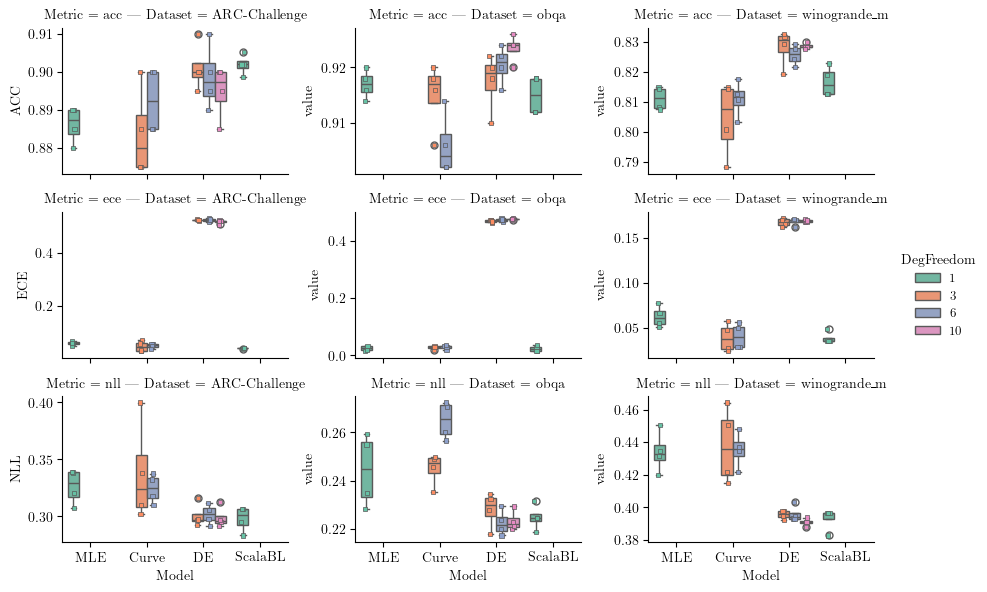

In [131]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])


g = sns.catplot(data=df_subset, x='Model', y='value', hue='DegFreedom', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Metric'] == row_name) & (df_subset['Dataset'] == col_name)],
            x='Model',
            y='value',
            hue='DegFreedom',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1305911/301518286.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric']).mean().reset_index()
/tmp/ipykernel_1305911/301518286.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)


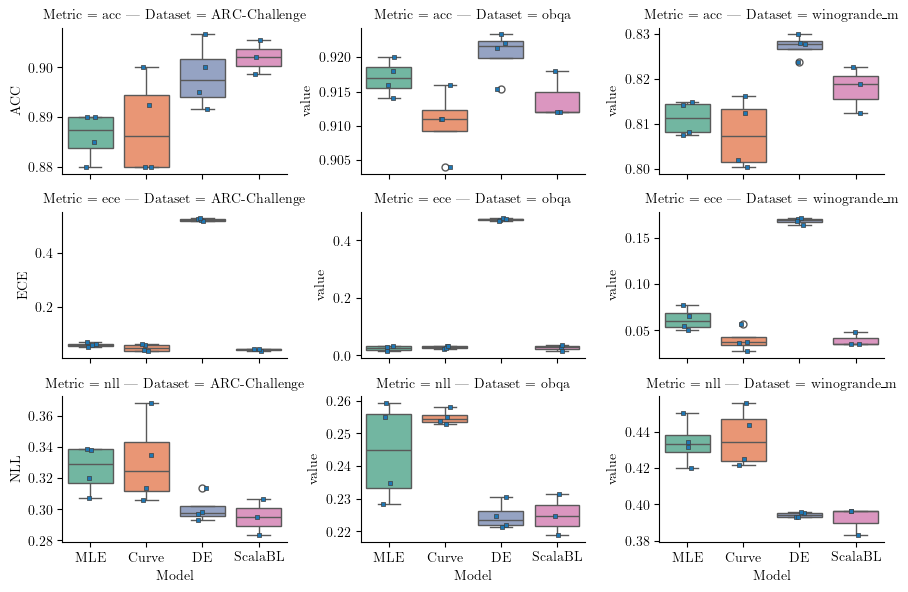

In [132]:
# Reference accuracy values from table 2
# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric']).mean().reset_index()
# Sort by Model order (MLE, Curve, DE, ScalaBL) and DegFreedom
# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset2[(df_subset2['Metric'] == row_name) & (df_subset2['Dataset'] == col_name)],
            x='Model',
            y='value',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
g.tight_layout()


### DE vs MLE vs Curve LastLayer


In [7]:
api = wandb.Api()
results = []

for s in ["75rfrghb",]: # MLE/ Curve 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="MLE" if run.config['curve_params']['k'] == 0 else "Curve",
            DegFreedom=run.config['curve_params']['k'] + 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        # res = dict(Id=run.id,
        # #    CurveSpace=f"{run.config['curve_params']['k']}",
        #     CurveSpace=run.config['curve_params']['k'],
        #     Jitter=run.config['curve_params']['jitter_multiplier'],
        #     Seed=run.config['rng_seed'],
        #     WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
        #     Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        #     Metric="mean",
        #     DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
        #     DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
        #     DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
        #     EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
        #     NumSteps=run.config['curve_params'].get('num_steps', -1),
        #     LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
        #     CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
        #     LoraRank=run.config['lora_params'].get('r', -1),
        #     RegularizationMode=run.config['curve_params'].get('regularizer', False),
        #     Gravity=run.config['curve_params'].get('gravity', 0.),
        #     EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
        #     bezierLength=run.summary.get('Curve length', 0),
        #     acc=run.summary.get(f"post_pred_test_mean_acc", 0),
        #     ece=run.summary.get(f"post_pred_test_mean_ece", 0),
        #     nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
        #     # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
        #     # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
        #     # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        #     # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        #     )
        # results.append(res)

for s in ["h23dngln",]: # DE 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="DE",
            DegFreedom=run.config['curve_params']['k'] + 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode="minibatch",
            DS_WindowSize=-1,
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_de_acc", 0),
            ece=run.summary.get(f"test_de_ece", 0),
            nll=-run.summary.get(f"test_de_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

# t_run = tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"))  # VI
# for run in t_run:
#     if run.state != 'finished':
#         print(f"Skipping {run.name} because it is not finished")
#         continue
#     t_run.set_postfix_str(run.name)
#     res = dict(Id=run.id,
#     #    CurveSpace=f"{run.config['curve_params']['k']}",
#         Model="ScalaBL",
#         DegFreedom=1,
#         Jitter=-1,
#         Seed=run.config['seed'],
#         WeightDecay=-1,
#         Dataset=run.config['dataset'],
#         Metric="ppd",
#         DS_Sampling=-1,
#         DS_Mode="minibatch",
#         DS_WindowSize=-1,
#         EntropyMaxScale=-1,
#         NumSteps=run.config['max_train_steps'],
#         LoraMode="AsB",
#         CurveMode=-1,
#         LoraRank=run.config['lora_r'],
#         RegularizationMode=False,
#         Gravity=-1,
#         EnergyWeakening=-1,
#         # bezierLength=run.summary.get('Curve length', 0),
#         acc=run.summary.get(f"final_val_acc", 0),
#         ece=run.summary.get(f"final_val_ece", 0),
#         nll=run.summary.get(f"final_val_nll", 0),
#         # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
#         # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
#         # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
#         # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
#         )
#     results.append(res)

    

df = pd.DataFrame(results)
# df['CurveSpace'] = df['CurveSpace'].apply(lambda x: 'MLE' if x == 0 else f'Curve_{x}')
df.head()

h23dngln: 100%|██████████| 24/24 [00:00<00:00, 405.78it/s, silvery-sweep-1]


,Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,acc,ece,nll
0,d2gi42pg,Curve,11,0,8,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.865,0.081726,0.371704
1,g5xmrxhl,Curve,11,0,4,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.865,0.078302,0.393052
2,29nk3v0u,Curve,11,0,2,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.870,0.065190,0.379998
3,vxxcxghh,Curve,11,0,1,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.880,0.069842,0.380754
4,su551tix,Curve,11,0,8,0.01,obqa,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.802,0.047414,0.551782


In [8]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,acc,ece,nll
Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,,,


In [9]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
Model ['Curve' 'MLE' 'DE']
DegFreedom [11  3  1]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m']
Metric ['ppd']
DS_Sampling ['minibatch' 'None']
DS_Mode ['classic' 'minibatch']
DS_WindowSize [-1]
EntropyMaxScale [ 0 -1]
NumSteps [5000]
LoraMode ['A(t)B(t)' 'A(t)B']
CurveMode ['bezier' 'Bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]

Experiment differs in ['Model', 'DegFreedom', 'Dataset', 'DS_Sampling', 'DS_Mode', 'EntropyMaxScale', 'LoraMode', 'CurveMode'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [10]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
df_subset = df_subset[df_subset['Dataset']!='ARC-Easy']
df_subset = df_subset[df_subset['Dataset']!='winogrande_s']
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'Model', 'DegFreedom'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       Model DegFreedom                              
ARC-Challenge Curve 3           0.870000  0.383498  0.065959
                    11          0.870000  0.381377  0.073765
              DE    3           0.870000  0.385231  0.050016
                    11          0.865000  0.386557  0.057081
              MLE   1           0.868750  0.381289  0.054782
obqa          Curve 3           0.803500  0.550943  0.045428
                    11          0.805000  0.554501  0.049878
              DE    3           0.803000  0.547115  0.046295
                    11          0.799000  0.546804  0.047256
              MLE   1           0.803500  0.553559  0.037412
winogrande_m  Curve 3           0.618333  0.652108  0.097277
                    11          0.622292  0.654264  0.104990
              DE    3           0.616042  0.648842  0.095807
                    11          0.622083  0.651048  0.094373
              MLE   1           0.614167  0.650929  0.098602

In [11]:
df_subset = df_subset.loc[:, ["Seed", 'Model', 'DegFreedom', 'Dataset', 'acc', 'nll', 'ece']].melt(id_vars=['Seed', 'Model', 'DegFreedom', 'Dataset'], var_name="Metric")

model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

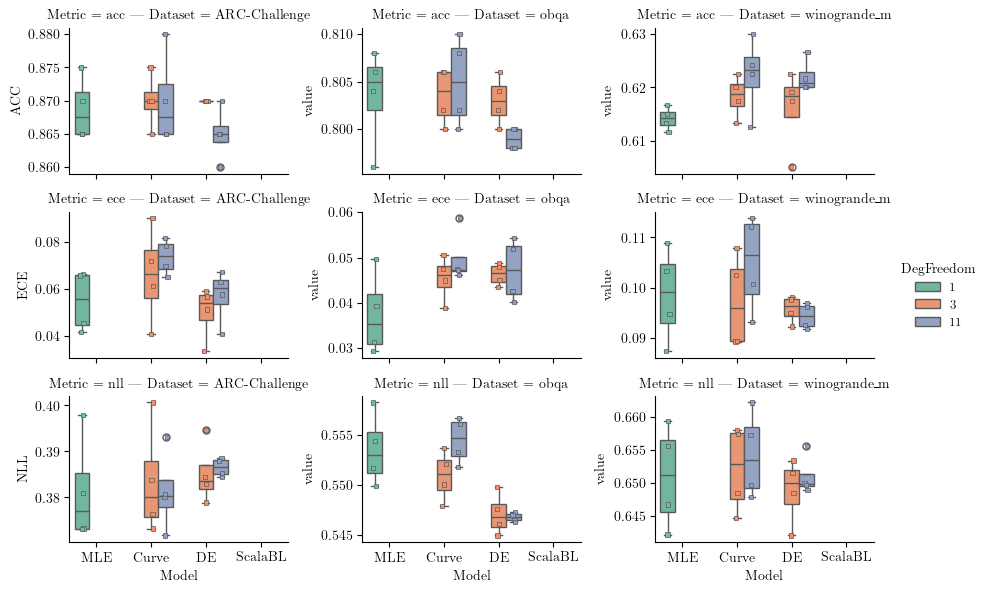

In [12]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])


g = sns.catplot(data=df_subset, x='Model', y='value', hue='DegFreedom', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Metric'] == row_name) & (df_subset['Dataset'] == col_name)],
            x='Model',
            y='value',
            hue='DegFreedom',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1315295/301518286.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric']).mean().reset_index()
/tmp/ipykernel_1315295/301518286.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)


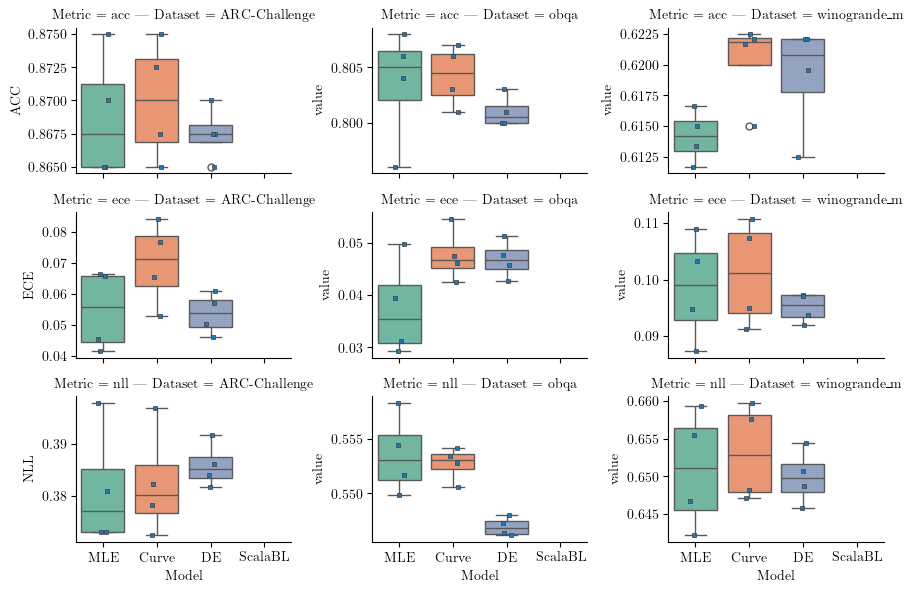

In [13]:
# Reference accuracy values from table 2
# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric']).mean().reset_index()
# Sort by Model order (MLE, Curve, DE, ScalaBL) and DegFreedom
# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset2[(df_subset2['Metric'] == row_name) & (df_subset2['Dataset'] == col_name)],
            x='Model',
            y='value',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
g.tight_layout()


### FixedPoints compare with VI vs DE vs MLE vs Curve


In [27]:
api = wandb.Api()
results = []

for s in ["20h06muz",]: # Fixed Control Points training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="Curve (Fixed CP)",
            DegFreedom=len(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

for s in ["0zkos614",]: # Curve training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="MLE" if run.config['curve_params']['k'] == 0 else "Curve",
            DegFreedom=run.config['curve_params']['k'] + 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        # res = dict(Id=run.id,
        # #    CurveSpace=f"{run.config['curve_params']['k']}",
        #     CurveSpace=run.config['curve_params']['k'],
        #     Jitter=run.config['curve_params']['jitter_multiplier'],
        #     Seed=run.config['rng_seed'],
        #     WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
        #     Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        #     Metric="mean",
        #     DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
        #     DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
        #     DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
        #     EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
        #     NumSteps=run.config['curve_params'].get('num_steps', -1),
        #     LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
        #     CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
        #     LoraRank=run.config['lora_params'].get('r', -1),
        #     RegularizationMode=run.config['curve_params'].get('regularizer', False),
        #     Gravity=run.config['curve_params'].get('gravity', 0.),
        #     EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
        #     bezierLength=run.summary.get('Curve length', 0),
        #     acc=run.summary.get(f"post_pred_test_mean_acc", 0),
        #     ece=run.summary.get(f"post_pred_test_mean_ece", 0),
        #     nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
        #     # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
        #     # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
        #     # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        #     # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        #     )
        # results.append(res)

for s in ["unb6x3vq",]: # think DE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="DE",
            DegFreedom=run.config['curve_params']['k'], #+ 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode="minibatch",
            DS_WindowSize=-1,
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_de_acc", 0),
            ece=run.summary.get(f"test_de_ece", 0),
            nll=-run.summary.get(f"test_de_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

t_run = tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"))  # ScalaBL
for run in t_run:
    if run.state != 'finished':
        print(f"Skipping {run.name} because it is not finished")
        continue
    t_run.set_postfix_str(run.name)
    res = dict(Id=run.id,
    #    CurveSpace=f"{run.config['curve_params']['k']}",
        Model="ScalaBL",
        DegFreedom=1,
        Jitter=-1,
        Seed=run.config['seed'],
        WeightDecay=-1,
        Dataset=run.config['dataset'],
        Metric="ppd",
        DS_Sampling=-1,
        DS_Mode="minibatch",
        DS_WindowSize=-1,
        EntropyMaxScale=-1,
        NumSteps=run.config['max_train_steps'],
        LoraMode="AsB",
        CurveMode=-1,
        LoraRank=run.config['lora_r'],
        RegularizationMode=False,
        Gravity=-1,
        EnergyWeakening=-1,
        # bezierLength=run.summary.get('Curve length', 0),
        acc=run.summary.get(f"final_val_acc", 0),
        ece=run.summary.get(f"final_val_ece", 0),
        nll=run.summary.get(f"final_val_nll", 0),
        # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
        # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
        # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        )
    results.append(res)

    

df = pd.DataFrame(results)
# df['CurveSpace'] = df['CurveSpace'].apply(lambda x: 'MLE' if x == 0 else f'Curve_{x}')
df.head()

20h06muz:   0%|          | 0/22 [00:00<?, ?it/s, summer-sweep-16]  

20h06muz: 100%|██████████| 22/22 [00:00<00:00, 588.74it/s, old_rare-sweep-17]


Skipping northern-sweep-22 because it is not finished
Skipping charmed-sweep-21 because it is not finished
Skipping hopeful-sweep-20 because it is not finished
Skipping mild-sweep-19 because it is not finished
Skipping deft-sweep-18 because it is not finished
Skipping trim-sweep-17 because it is not finished
Skipping super-sweep-14 because it is not finished
Skipping fancy-sweep-10 because it is not finished
Skipping solar-sweep-8 because it is not finished
Skipping noble-sweep-9 because it is not finished
Skipping blooming-sweep-7 because it is not finished


100%|██████████| 24/24 [00:00<00:00, 2652.17it/s, scalabl-obqa-sample40-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id]

Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-obqa-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished


,Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,acc,ece,nll
0,krunuar4,Curve (Fixed CP),5,0,2,0.01,winogrande_m,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.817500,0.070572,0.443597
1,zs9b9kkz,Curve (Fixed CP),5,0,1,0.01,winogrande_m,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.825833,0.045821,0.422287
2,7zy93yic,Curve (Fixed CP),3,0,4,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.905000,0.064303,0.325918
3,bzdpp3b5,Curve (Fixed CP),3,0,2,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.880000,0.056563,0.342657
4,xsaslzma,Curve (Fixed CP),3,0,1,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.890000,0.049050,0.318249


In [28]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,acc,ece,nll
Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,,,


In [29]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
Model ['Curve (Fixed CP)' 'Curve' 'MLE' 'DE' 'ScalaBL']
DegFreedom [ 5  3  6  1 10]
Jitter [ 0 -1]
Seed [2 1 4 8 0 7 6]
WeightDecay [ 0.01 -1.  ]
Dataset ['winogrande_m' 'ARC-Challenge' 'obqa' 'winogrande_s' 'ARC-Easy']
Metric ['ppd']
DS_Sampling ['minibatch' 'None' -1]
DS_Mode ['classic' 'minibatch']
DS_WindowSize [-1]
EntropyMaxScale [ 0 -1]
NumSteps [5000]
LoraMode ['A(t)B(t)' 'As(t)B' 'A(t)B' 'AsB']
CurveMode ['bezier' 'Bezier' -1]
LoraRank [8]
RegularizationMode [False]
Gravity [ 0 -1]
EnergyWeakening [ 1 -1]

Experiment differs in ['Model', 'DegFreedom', 'Jitter', 'WeightDecay', 'Dataset', 'DS_Sampling', 'DS_Mode', 'EntropyMaxScale', 'LoraMode', 'CurveMode', 'Gravity', 'EnergyWeakening'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc compare Entropy Scale

In [30]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
df_subset = df_subset[df_subset['Dataset']!='ARC-Easy']
df_subset = df_subset[df_subset['Dataset']!='winogrande_s']
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'Model', 'DegFreedom'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       Model            DegFreedom                              
ARC-Challenge Curve            3           0.883750  0.337572  0.048529
                               6           0.892500  0.324448  0.050696
              Curve (Fixed CP) 3           0.891667  0.328941  0.056639
              DE               3           0.901250  0.300610  0.525800
                               6           0.898750  0.301807  0.524635
                               10          0.895000  0.298854  0.519306
              MLE              1           0.886250  0.326249  0.060490
              ScalaBL          1           0.902027  0.297852  0.041976
obqa          Curve            3           0.915000  0.244980  0.028358
                               6           0.906000  0.264976  0.029702
              Curve (Fixed CP) 5           0.914000  0.256374  0.038858
              DE               3           0.917500  0.228231  0.469771
                               6           0.920500  0.222564  0.472848
                               10          0.923500  0.223299  0.475908
              MLE              1           0.917000  0.244404  0.024823
              ScalaBL          1           0.915000  0.224854  0.023838
winogrande_m  Curve            3           0.804583  0.437815  0.038768
                               6           0.811042  0.435443  0.040568
              Curve (Fixed CP) 3           0.816250  0.478852  0.090298
                               5           0.821667  0.432942  0.058197
              DE               3           0.828125  0.395557  0.167246
                               6           0.825625  0.396008  0.168026
                               10          0.828542  0.391048  0.168740
              MLE              1           0.811250  0.434169  0.062158
              ScalaBL          1           0.816653  0.393066  0.038685

In [31]:
df_subset = df_subset.loc[:, ["Seed", 'Model', 'DegFreedom', 'Dataset', 'acc', 'nll', 'ece']].melt(id_vars=['Seed', 'Model', 'DegFreedom', 'Dataset'], var_name="Metric")

model_order = ['MLE', 'Curve', 'Curve (Fixed CP)', 'DE', 'ScalaBL']
df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

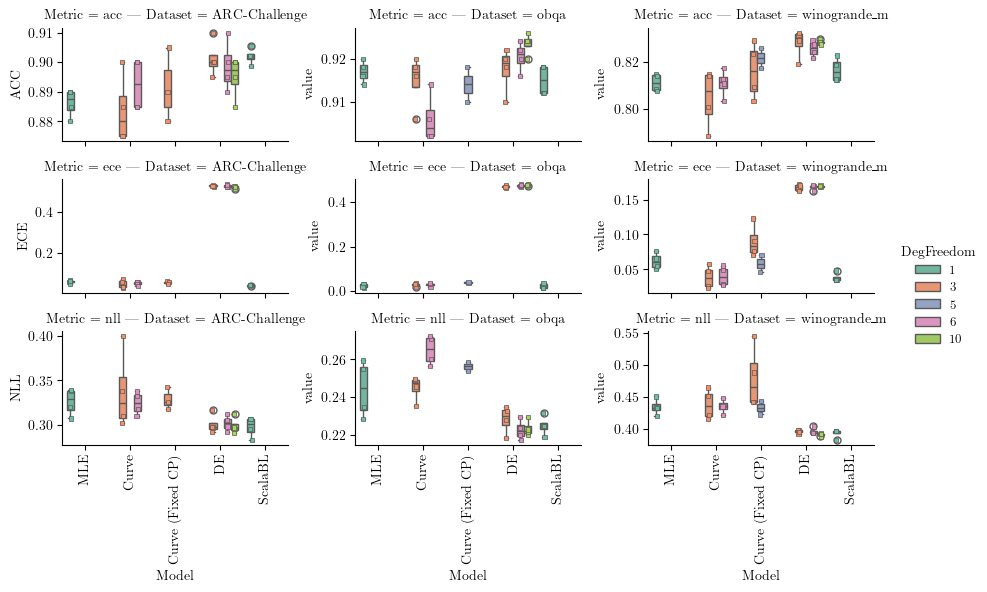

In [32]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])


g = sns.catplot(data=df_subset, x='Model', y='value', hue='DegFreedom', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Metric'] == row_name) & (df_subset['Dataset'] == col_name)],
            x='Model',
            y='value',
            hue='DegFreedom',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
# rotate x tick labels for all subplots
for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=90)
g.tight_layout()


/tmp/ipykernel_1334156/2015359192.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)


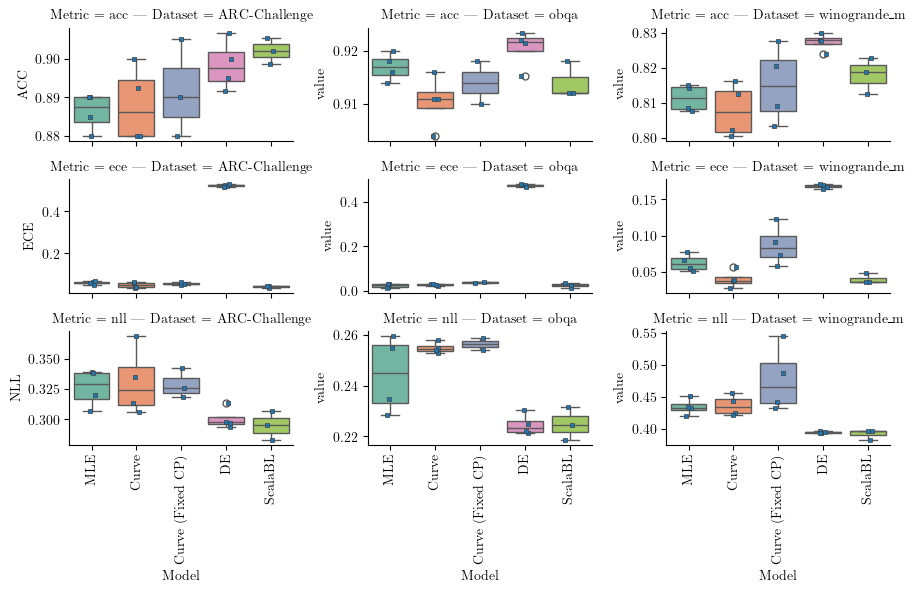

In [33]:
# Reference accuracy values from table 2
# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric'], observed=False).mean().reset_index()
# Sort by Model order (MLE, Curve, DE, ScalaBL) and DegFreedom
# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset2[(df_subset2['Metric'] == row_name) & (df_subset2['Dataset'] == col_name)],
            x='Model',
            y='value',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
# rotate x tick labels for all subplots
for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=90)
g.tight_layout()


### Compare loss landscape

In [7]:
from wandb import Api

api = Api()
run = api.run("ddold/qwen_PtoC/5hgtjsd6")
run.summary.get(f"Curve Predictive Train", 0)

{'_type': 'image-file', 'format': 'png', 'height': 300, 'path': 'media/images/Curve Predictive Train_11031_71c12f2fb5903dfea4dc.png', 'sha256': '71c12f2fb5903dfea4dc9b50da0b02a354306cb7303173fad0cd733097dd5016', 'size': 24902, 'width': 400}

### Curve per leave 


In [43]:
api = wandb.Api()
results = []

for s in ["umeb6pa2",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0),
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf),
            )
        results.append(res)

for s in ["zbdorvq8",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)    
        else:
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf),
            )
        results.append(res)
df = pd.DataFrame(results)
df.head()

zbdorvq8: 100%|██████████| 24/24 [00:00<00:00, 399.94it/s, confused-sweep-2]


,Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,EnergyWeakening,Tsample,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,vzdda6hu,6,"[0, 0, 0, 0, 0, 0]",0,8,0.01,ARC-Challenge,ppd,minibatch,classic,...,1,per_leaf,35.288780,0.910,0.049384,0.299048,0.345555,0.013379,0.007814,0.332175
1,6rxbmzj7,6,"[0, 0, 0, 0, 0, 0]",0,4,0.01,ARC-Challenge,ppd,minibatch,classic,...,1,per_leaf,35.690102,0.910,0.034357,0.283648,0.332553,0.015483,0.007000,0.317071
2,7n0sjx0s,6,"[0, 0, 0, 0, 0, 0]",0,2,0.01,ARC-Challenge,ppd,minibatch,classic,...,1,per_leaf,36.289398,0.890,0.071027,0.381386,0.208612,0.023940,0.010940,0.184672
3,4wuzzqxt,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,ARC-Challenge,ppd,minibatch,classic,...,1,per_leaf,35.023643,0.880,0.040297,0.335218,0.310160,0.007615,0.005794,0.302545
4,p3whhn0m,6,"[0, 0, 0, 0, 0, 0]",0,8,0.01,ARC-Challenge,ppd,minibatch,classic,...,1,per_leaf,24.733397,0.885,0.039292,0.320283,0.319459,0.003807,0.004902,0.315652


In [44]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,,,,,,,,


In [45]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [6 3]
CpFix ['[0, 0, 0, 0, 0, 0]' '[0, 0, 0]']
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m']
Metric ['ppd']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['A(t)B(t)' 'As(t)B' 'Asd(t)B']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['per_leaf' 'combined']

Experiment differs in ['CurveSpace', 'CpFix', 'Dataset', 'LoraMode', 'Tsample'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [46]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['Tsample'] == 'per_leaf']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset','LoraMode', 'CurveSpace', 'Tsample'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       LoraMode CurveSpace Tsample                               
ARC-Challenge A(t)B(t) 3          per_leaf  0.907500  0.303390  0.058632
                       6          per_leaf  0.897500  0.324825  0.048766
              As(t)B   3          per_leaf  0.892500  0.319242  0.051929
                       6          per_leaf  0.882500  0.323127  0.046199
              Asd(t)B  3          combined  0.892500  0.321465  0.047275
                                  per_leaf  0.892500  0.323128  0.044780
obqa          A(t)B(t) 3          per_leaf  0.911000  0.245141  0.029407
                       6          per_leaf  0.913000  0.243792  0.027687
              As(t)B   3          per_leaf  0.912500  0.254035  0.029761
                       6          per_leaf  0.917500  0.251796  0.025687
              Asd(t)B  3          combined  0.913500  0.246888  0.030048
                                  per_leaf  0.914000  0.247020  0.027997
winogrande_m  A(t)B(t) 3          per_leaf  0.799583  0.462981  0.056829
                       6          per_leaf  0.802083  0.463214  0.063532
              As(t)B   3          per_leaf  0.809792  0.452272  0.056209
                       6          per_leaf  0.814167  0.448249  0.060784
              Asd(t)B  3          combined  0.810000  0.444934  0.053675
                                  per_leaf  0.810208  0.446078  0.055203

ARC-Challenge per_leaf
ARC-Challenge combined
obqa per_leaf
obqa combined
winogrande_m per_leaf
winogrande_m combined
Dataset = ARC-Challenge | Tsample = per_leaf
ARC-Challenge
Dataset = obqa | Tsample = per_leaf
obqa
Dataset = winogrande_m | Tsample = per_leaf
winogrande_m


/tmp/ipykernel_12870/3139429871.py:25: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/3139429871.py:25: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/3139429871.py:25: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/3139429871.py:25: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/3139429871.py:25: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/3139429871.py:25: FutureWarning: Use "auto" to set automatic grayscale colors. From 

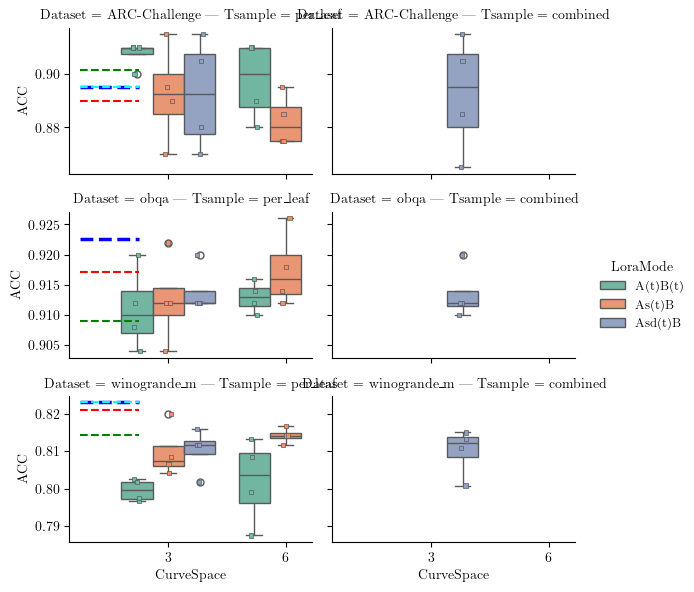

In [47]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['LoraMode'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='CurveSpace', y='acc', hue='LoraMode', kind='box', row='Dataset', col='Tsample', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        entropy_scale = ax.get_title().split('=')[2].strip()
        print(ds, entropy_scale)
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
            x='CurveSpace',
            y='acc',
            hue='LoraMode',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_12870/73135356.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/73135356.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/73135356.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/73135356.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/73135356.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/73135356.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gr

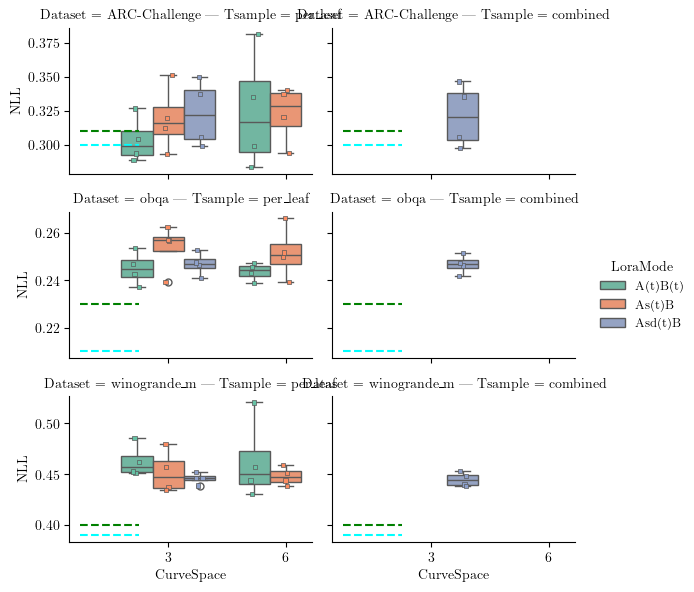

In [48]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='CurveSpace', y='nll', hue='LoraMode', kind='box', row='Dataset', col='Tsample', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        x='CurveSpace',
        y='nll',
        hue='LoraMode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_12870/4214643291.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/4214643291.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/4214643291.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/4214643291.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/4214643291.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/4214643291.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From 

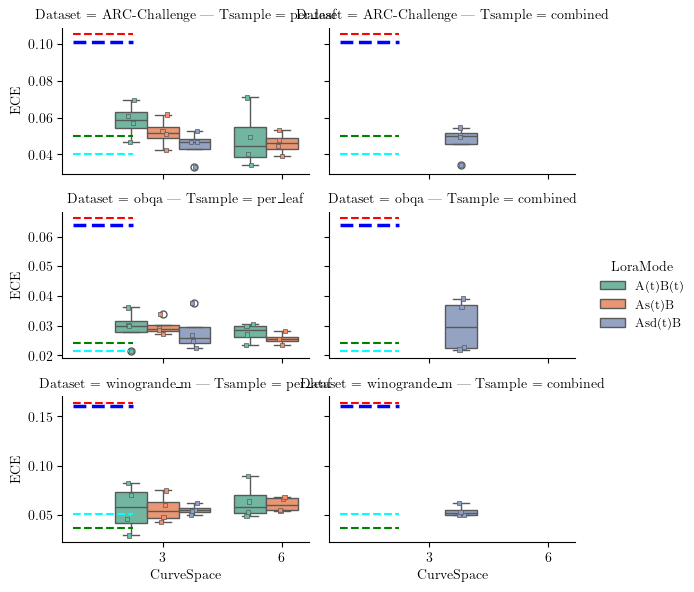

In [49]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='CurveSpace', y='ece', hue='LoraMode', kind='box', row='Dataset', col='Tsample', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        x='CurveSpace',
        y='ece',
        hue='LoraMode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### Flat-Lora 


In [3]:
api = wandb.Api()
results = []


for s in ["kvfhm79j",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)
        
for s in ["r8fcpq9i",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)


for s in ["7mv3szwn",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        space = len(run.config['curve_params']['cp_fix'])
        if space == 1:
            acc=run.summary.get(f"cp_fixed_0_post_pred_test_mean_acc", 0)
            ece=run.summary.get(f"cp_fixed_0_post_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"cp_fixed_0_post_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
                acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
                ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
                nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
                test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
                test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
                std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
                mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
            else:
                acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
                ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
                nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

                test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
                test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
                std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
                mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace="MLE" if space == 1 else space,
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)
df = pd.DataFrame(results)
df

r8fcpq9i:  32%|███▏      | 41/128 [00:00<00:00, 272.06it/s, polished-sweep-59]     

Skipping curious-sweep-112 because it is not finished
Skipping fragrant-sweep-111 because it is not finished
Skipping royal-sweep-110 because it is not finished
Skipping amber-sweep-107 because it is not finished
Skipping rare-sweep-101 because it is not finished
Skipping usual-sweep-100 because it is not finished
Skipping smart-sweep-85 because it is not finished


7mv3szwn: 100%|██████████| 48/48 [00:00<00:00, 551.96it/s, resilient-sweep-3]


Skipping crimson-sweep-48 because it is not finished


,Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,Tsample,LoraRho,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,x8ty9syr,3,"[0, 0, 0]",0,8,0.01,winogrande_m,ppd,minibatch,classic,...,combined,1.0,24.684416,0.604167,0.080447,0.644400,0.609044,0.009803,0.015307,0.599231
1,xppc5kt6,3,"[0, 0, 0]",0,4,0.01,winogrande_m,ppd,minibatch,classic,...,combined,1.0,24.132126,0.633333,0.117590,0.684474,0.514929,0.001808,0.004257,0.513083
2,2y9nyyo4,3,"[0, 0, 0]",0,2,0.01,winogrande_m,ppd,minibatch,classic,...,combined,1.0,24.205212,0.629167,0.111882,0.673053,0.520093,0.006122,0.007048,0.513918
3,nvc3xuad,3,"[0, 0, 0]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,combined,1.0,24.738529,0.623333,0.074753,0.642329,0.597374,0.002587,0.007921,0.594741
4,igymfd89,3,"[0, 0, 0]",0,8,0.01,winogrande_m,ppd,minibatch,classic,...,combined,0.5,25.781818,0.830833,0.060692,0.412952,0.326947,0.019140,0.031155,0.307601
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
243,rgz5er40,MLE,[1],0,8,0.01,winogrande_m,ppd,minibatch,classic,...,combined,0.1,0.000000,0.821667,0.058265,0.427552,-inf,-inf,-inf,-inf
244,px551eaj,MLE,[1],0,2,0.01,winogrande_m,ppd,minibatch,classic,...,combined,0.1,0.000000,0.785833,0.050470,0.461038,-inf,-inf,-inf,-inf
245,gt6ubwkt,MLE,[1],0,1,0.01,winogrande_m,ppd,minibatch,classic,...,combined,1.0,0.000000,0.618333,0.064730,0.636872,-inf,-inf,-inf,-inf
246,dzdpd9xm,MLE,[1],0,2,0.01,winogrande_m,ppd,minibatch,classic,...,combined,10.0,0.000000,0.625833,0.109175,0.700990,-inf,-inf,-inf,-inf


In [4]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,LoraRho,,,,,,,,


In [5]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [3 'MLE']
CpFix ['[0, 0, 0]' '[1]']
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['winogrande_m' 'ARC-Challenge' 'obqa']
Metric ['ppd']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['A(t)B(t)' 'Asd(t)B']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined' 'per_leaf']
LoraRho [ 1.    0.5   0.01  0.05  0.1  10.  ]

Experiment differs in ['CurveSpace', 'CpFix', 'Dataset', 'LoraMode', 'Tsample', 'LoraRho'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [6]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']

df_subset['Config'] = df_subset.apply(lambda row: f"K={row['CurveSpace']} -- LM={row['LoraMode']}", axis=1)
# df_subset = df_subset[df_subset['Tsample'] == 'per_leaf']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset','LoraMode', 'CurveSpace', 'Tsample', 'LoraRho'])[['acc', 'nll', 'ece']].mean()

acc       nll  \
Dataset       LoraMode CurveSpace Tsample  LoraRho                       
ARC-Challenge A(t)B(t) 3          combined 0.01     0.901250  0.333414   
                                           0.10     0.891250  0.349665   
                                           1.00     0.890000  0.322987   
                                           10.00    0.828750  0.561027   
                                  per_leaf 0.01     0.896250  0.334633   
...                                                      ...       ...   
winogrande_m  Asd(t)B  3          per_leaf 0.01     0.808958  0.459153   
                                           0.05     0.807292  0.456469   
                                           0.10     0.811042  0.447492   
                                           0.50     0.817083  0.436783   
                                           1.00     0.625000  0.663223   

                                                         ece  
Dataset       LoraMode CurveSpace Tsample  LoraRho            
ARC-Challenge A(t)B(t) 3          combined 0.01     0.056095  
                                           0.10     0.056760  
                                           1.00     0.050481  
                                           10.00    0.165513  
                                  per_leaf 0.01     0.050980  
...                                                      ...  
winogrande_m  Asd(t)B  3          per_leaf 0.01     0.065078  
                                           0.05     0.062514  
                                           0.10     0.061477  
                                           0.50     0.069225  
                                           1.00     0.092909  

[64 rows x 3 columns]

ARC-Challenge combined
ARC-Challenge per_leaf
obqa combined
obqa per_leaf
winogrande_m combined


/tmp/ipykernel_37248/3085625595.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3085625595.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3085625595.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3085625595.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3085625595.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


winogrande_m per_leaf


/tmp/ipykernel_37248/3085625595.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


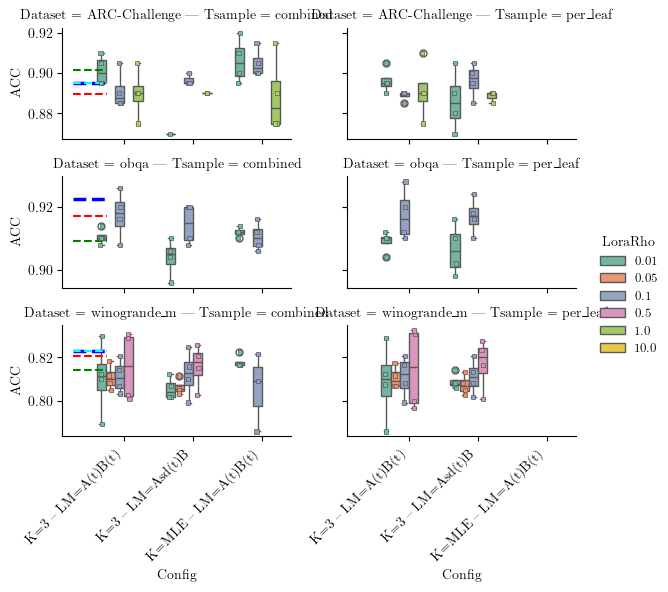

In [7]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

df_subset['LoraRho'] = df_subset['LoraRho'].astype(str)
numeric_rhos = sorted(df_subset['LoraRho'].astype(float).unique())
hue_order = [str(x) for x in numeric_rhos]

# Filter out bad runs with dataset-specific thresholds
min_acc = {
    'ARC-Easy': 0.85,
    'obqa': 0.83,
    'ARC-Challenge': 0.85,
    'boolq': 0.65,
    'winogrande_m': 0.7,
    'winogrande_s': 0.55
}
df_subset = df_subset[df_subset['acc'] > df_subset['Dataset'].map(min_acc).fillna(0)]

# # df_subset = df_subset[df_subset['Config']==0]
# hue_order = list(df_subset['LoraRho'].unique())
# hue_order.sort()
# # hue_order = None
# # hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='Config', y='acc', hue='LoraRho', kind='box', row='Dataset', col='Tsample', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        entropy_scale = ax.get_title().split('=')[2].strip()
        print(ds, entropy_scale)
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
            x='Config',
            y='acc',
            hue='LoraRho',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    # print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    # print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
# g.set_xticklabels(rotation=90, ha='center')
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_37248/3782151349.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3782151349.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3782151349.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3782151349.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3782151349.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3782151349.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From 

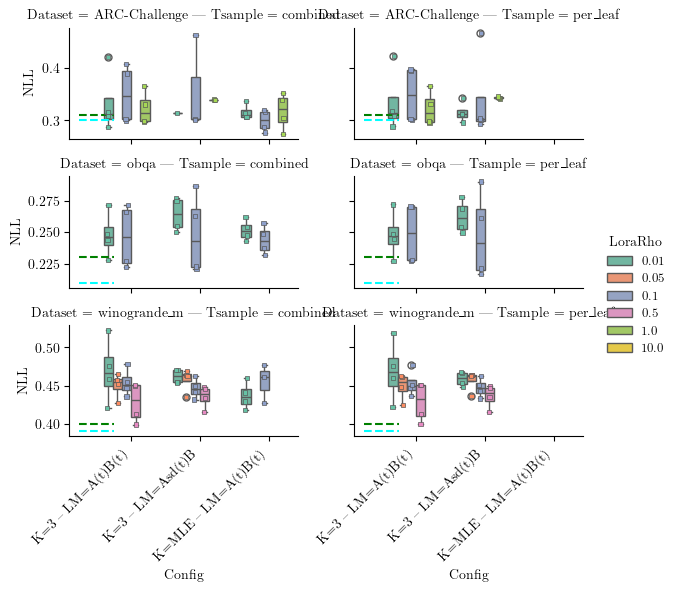

In [8]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='Config', y='nll', hue='LoraRho', kind='box', row='Dataset', col='Tsample', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        x='Config',
        y='nll',
        hue='LoraRho',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_37248/2528788350.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/2528788350.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/2528788350.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/2528788350.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/2528788350.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/2528788350.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From 

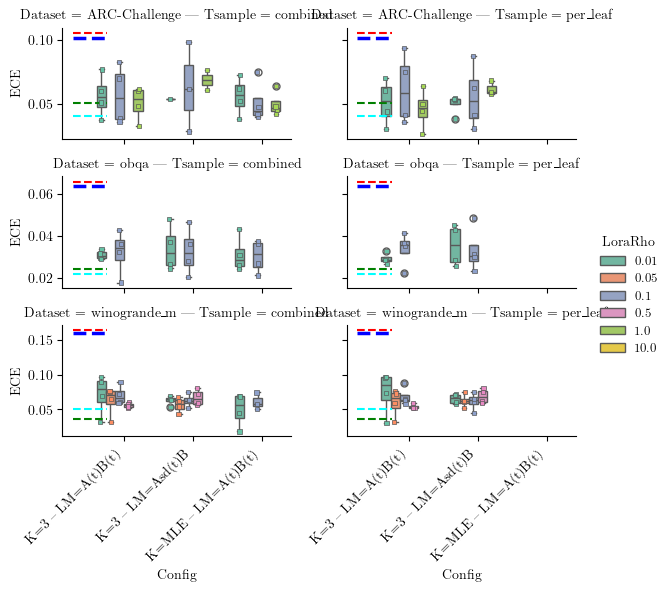

In [9]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='Config', y='ece', hue='LoraRho', kind='box', row='Dataset', col='Tsample', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        x='Config',
        y='ece',
        hue='LoraRho',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed

for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

### VI vs DE vs MLE vs Curve vs Flat-Lora


In [3]:
api = wandb.Api()
results = []


test_mean_entropy_ppd=0.
test_mutual_information_ppd=0.
std_entropy_along_curve=0.
mean_entropy_along_curve=0.

for s in ["0zkos614",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="MLE" if run.config['curve_params']['k'] == 0 else "Curve",
            CpFix="[1]",
            DegFreedom=run.config['curve_params']['k'] + 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample="combined",
            LoraRho=0.,
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        # res = dict(Id=run.id,
        # #    CurveSpace=f"{run.config['curve_params']['k']}",
        #     CurveSpace=run.config['curve_params']['k'],
        #     Jitter=run.config['curve_params']['jitter_multiplier'],
        #     Seed=run.config['rng_seed'],
        #     WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
        #     Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        #     Metric="mean",
        #     DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
        #     DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
        #     DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
        #     EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
        #     NumSteps=run.config['curve_params'].get('num_steps', -1),
        #     LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
        #     CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
        #     LoraRank=run.config['lora_params'].get('r', -1),
        #     RegularizationMode=run.config['curve_params'].get('regularizer', False),
        #     Gravity=run.config['curve_params'].get('gravity', 0.),
        #     EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
        #     bezierLength=run.summary.get('Curve length', 0),
        #     acc=run.summary.get(f"post_pred_test_mean_acc", 0),
        #     ece=run.summary.get(f"post_pred_test_mean_ece", 0),
        #     nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
        #     # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
        #     # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
        #     # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        #     # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        #     )
        # results.append(res)

for s in ["unb6x3vq",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="DE",
            # CurveSpace=run.config['curve_params']['k'],
            CpFix="DE",
            DegFreedom=run.config['curve_params']['k'], #+ 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode="minibatch",
            DS_WindowSize=-1,
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample="combined",
            LoraRho=0.,
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_de_acc", 0),
            ece=run.summary.get(f"test_de_ece", 0),
            nll=-run.summary.get(f"test_de_ll", 0),
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

t_run = tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"))
for run in t_run:
    if run.state != 'finished':
        print(f"Skipping {run.name} because it is not finished")
        continue
    t_run.set_postfix_str(run.name)
    res = dict(Id=run.id,
    #    CurveSpace=f"{run.config['curve_params']['k']}",
        Model="ScalaBL",
        CpFix="ScalaBL",
        DegFreedom=1,
        Jitter=-1,
        Seed=run.config['seed'],
        WeightDecay=-1,
        Dataset=run.config['dataset'],
        Metric="ppd",
        DS_Sampling=-1,
        DS_Mode="minibatch",
        DS_WindowSize=-1,
        EntropyMaxScale=-1,
        NumSteps=run.config['max_train_steps'],
        LoraMode="AsB",
        CurveMode=-1,
        LoraRank=run.config['lora_r'],
        RegularizationMode=False,
        Gravity=-1,
        EnergyWeakening=-1,
        Tsample="combined",
        LoraRho=0.,
        bezierLength=run.summary.get('Curve length', 0),
        acc=run.summary.get(f"final_val_acc", 0),
        ece=run.summary.get(f"final_val_ece", 0),
        nll=run.summary.get(f"final_val_nll", 0),
        test_mean_entropy_ppd=test_mean_entropy_ppd,
        test_mutual_information_ppd=test_mutual_information_ppd,
        std_entropy_along_curve=std_entropy_along_curve,
        mean_entropy_along_curve=mean_entropy_along_curve,
        # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
        # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
        # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        )
    results.append(res)

# Flat Lora
for s in ["kvfhm79j",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            DegFreedom=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Model=f"Flat_k={len(run.config['curve_params']['cp_fix'])}",
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)
        
for s in ["r8fcpq9i",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            DegFreedom=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Model=f"Flat_k={len(run.config['curve_params']['cp_fix'])}",
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)


for s in ["7mv3szwn",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        space = len(run.config['curve_params']['cp_fix'])
        if space == 1:
            acc=run.summary.get(f"cp_fixed_0_post_pred_test_mean_acc", 0)
            ece=run.summary.get(f"cp_fixed_0_post_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"cp_fixed_0_post_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
                acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
                ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
                nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
                test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
                test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
                std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
                mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
            else:
                acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
                ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
                nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

                test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
                test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
                std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
                mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            DegFreedom=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Model=f"Flat_MLE",
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)

df = pd.DataFrame(results)
# df['CurveSpace'] = df['CurveSpace'].apply(lambda x: 'MLE' if x == 0 else f'Curve_{x}')
df.head()

0zkos614: 100%|██████████| 36/36 [00:00<00:00, 357.13it/s, swift-sweep-1]   


100%|██████████| 24/24 [00:00<00:00, 2283.55it/s, scalabl-obqa-sample40-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id]


Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-obqa-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished


r8fcpq9i:  77%|███████▋  | 98/128 [00:00<00:00, 453.13it/s, balmy-sweep-38]        

Skipping curious-sweep-112 because it is not finished
Skipping fragrant-sweep-111 because it is not finished
Skipping royal-sweep-110 because it is not finished
Skipping amber-sweep-107 because it is not finished
Skipping rare-sweep-101 because it is not finished
Skipping usual-sweep-100 because it is not finished
Skipping smart-sweep-85 because it is not finished


7mv3szwn: 100%|██████████| 48/48 [00:00<00:00, 532.62it/s, resilient-sweep-3]


Skipping crimson-sweep-48 because it is not finished


,Id,Model,CpFix,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,...,Tsample,LoraRho,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,dnjchqms,Curve,[1],6,0,8,0.01,ARC-Challenge,ppd,minibatch,...,combined,0.0,24.431843,0.900,0.056942,0.337576,0.0,0.0,0.0,0.0
1,v6cifdaz,Curve,[1],6,0,4,0.01,ARC-Challenge,ppd,minibatch,...,combined,0.0,24.490715,0.885,0.057138,0.332405,0.0,0.0,0.0,0.0
2,6emdndh6,Curve,[1],6,0,2,0.01,ARC-Challenge,ppd,minibatch,...,combined,0.0,24.555595,0.900,0.049955,0.309974,0.0,0.0,0.0,0.0
3,vc1q3re4,Curve,[1],6,0,1,0.01,ARC-Challenge,ppd,minibatch,...,combined,0.0,24.410172,0.885,0.038748,0.317836,0.0,0.0,0.0,0.0
4,2owl9jlu,Curve,[1],6,0,8,0.01,obqa,ppd,minibatch,...,combined,0.0,24.375814,0.902,0.032790,0.270770,0.0,0.0,0.0,0.0


In [4]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,Model,CpFix,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,LoraRho,,,,,,,,


In [5]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
Model ['Curve' 'MLE' 'DE' 'ScalaBL' 'Flat_k=3' 'Flat_MLE']
CpFix ['[1]' 'DE' 'ScalaBL' '[0, 0, 0]']
DegFreedom [ 6  3  1 10]
Jitter [ 0 -1]
Seed [8 4 2 1 0 7 6]
WeightDecay [ 0.01 -1.  ]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m' 'winogrande_s' 'ARC-Easy']
Metric ['ppd']
DS_Sampling ['minibatch' 'None' -1]
DS_Mode ['classic' 'minibatch']
DS_WindowSize [-1]
EntropyMaxScale [ 0 -1]
NumSteps [5000]
LoraMode ['As(t)B' 'A(t)B' 'AsB' 'A(t)B(t)' 'Asd(t)B']
CurveMode ['Bezier' -1 'bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [ 0 -1]
EnergyWeakening [ 1 -1]
Tsample ['combined' 'per_leaf']
LoraRho [ 0.    1.    0.5   0.01  0.05  0.1  10.  ]

Experiment differs in ['Model', 'CpFix', 'DegFreedom', 'Jitter', 'WeightDecay', 'Dataset', 'DS_Sampling', 'DS_Mode', 'EntropyMaxScale', 'LoraMode', 'CurveMode', 'Gravity', 'EnergyWeakening', 'Tsample', 'LoraRho'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc compare Entropy Scale

In [6]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
df_subset = df_subset[df_subset['Dataset']!='ARC-Easy']
df_subset = df_subset[df_subset['Dataset']!='winogrande_s']
df_subset = df_subset[(df_subset['LoraRho']==0.) | (df_subset['LoraRho']==0.1) | (df_subset['LoraRho']==0.5)]
df_subset = df_subset[((df_subset['Tsample']=='per_leaf') &  (df_subset['Model'].str.startswith("Flat_k")) & (df_subset['LoraMode'] == "A(t)B(t)")) | (~(df_subset['Model'].str.startswith("Flat_k")))]
df_subset = df_subset[~((df_subset['Dataset'] == "winogrande_m") & (df_subset['Model'].str.startswith("Flat_k")) & (df_subset['LoraRho'] == 0.1))]
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'Model', 'DegFreedom'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       Model    DegFreedom                              
ARC-Challenge Curve    3           0.883750  0.337572  0.048529
                       6           0.892500  0.324448  0.050696
              DE       3           0.901250  0.300610  0.525800
                       6           0.898750  0.301807  0.524635
                       10          0.895000  0.298854  0.519306
              Flat_MLE 1           0.905000  0.300189  0.050950
              Flat_k=3 3           0.888750  0.348918  0.061379
              MLE      1           0.886250  0.326249  0.060490
              ScalaBL  1           0.902027  0.297852  0.041976
obqa          Curve    3           0.915000  0.244980  0.028358
                       6           0.906000  0.264976  0.029702
              DE       3           0.917500  0.228231  0.469771
                       6           0.920500  0.222564  0.472848
                       10          0.923500  0.223299  0.475908
              Flat_MLE 1           0.910500  0.243741  0.030390
              Flat_k=3 3           0.917500  0.248904  0.033798
              MLE      1           0.917000  0.244404  0.024823
              ScalaBL  1           0.915000  0.224854  0.023838
winogrande_m  Curve    3           0.804583  0.437815  0.038768
                       6           0.811042  0.435443  0.040568
              DE       3           0.828125  0.395557  0.167246
                       6           0.825625  0.396008  0.168026
                       10          0.828542  0.391048  0.168740
              Flat_MLE 1           0.805556  0.455224  0.061081
              Flat_k=3 3           0.815000  0.428739  0.054342
              MLE      1           0.811250  0.434169  0.062158
              ScalaBL  1           0.816653  0.393066  0.038685

In [7]:
df_subset = df_subset.loc[:, ["Seed", 'Model', 'DegFreedom', 'Dataset', 'LoraRho', 'acc', 'nll', 'ece']].melt(id_vars=['Seed', 'Model', 'DegFreedom', 'Dataset', 'LoraRho'], var_name="Metric")

model_order = ['MLE', 'Curve', 'DE', 'ScalaBL', 'Flat_MLE', 'Flat_k=3']
df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

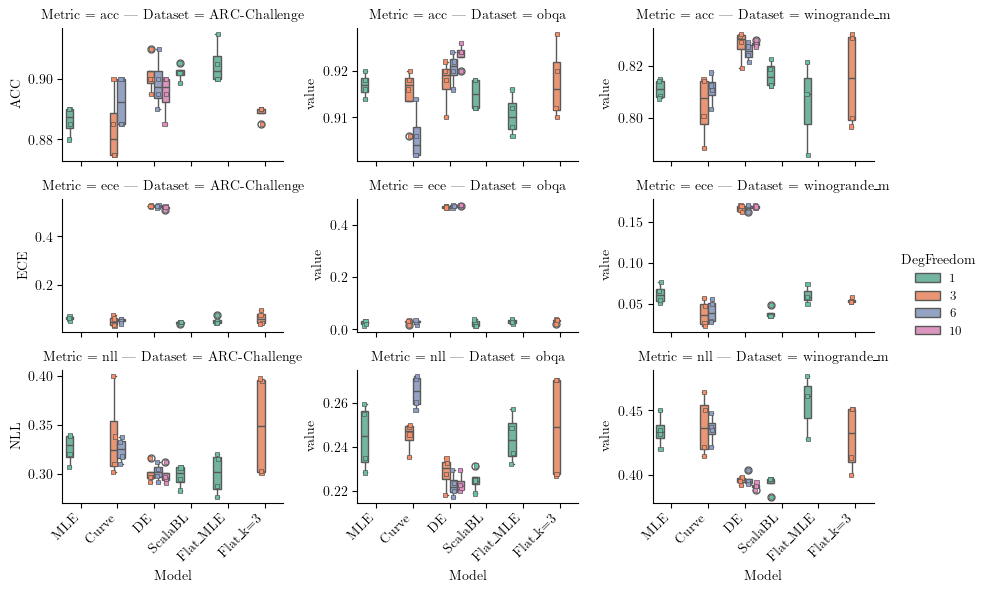

In [10]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])


g = sns.catplot(data=df_subset, x='Model', y='value', hue='DegFreedom', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Metric'] == row_name) & (df_subset['Dataset'] == col_name)],
            x='Model',
            y='value',
            hue='DegFreedom',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())



# Adjust legend placement if needed
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()


/tmp/ipykernel_51909/1676404820.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric']).mean().reset_index()
/tmp/ipykernel_51909/1676404820.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)


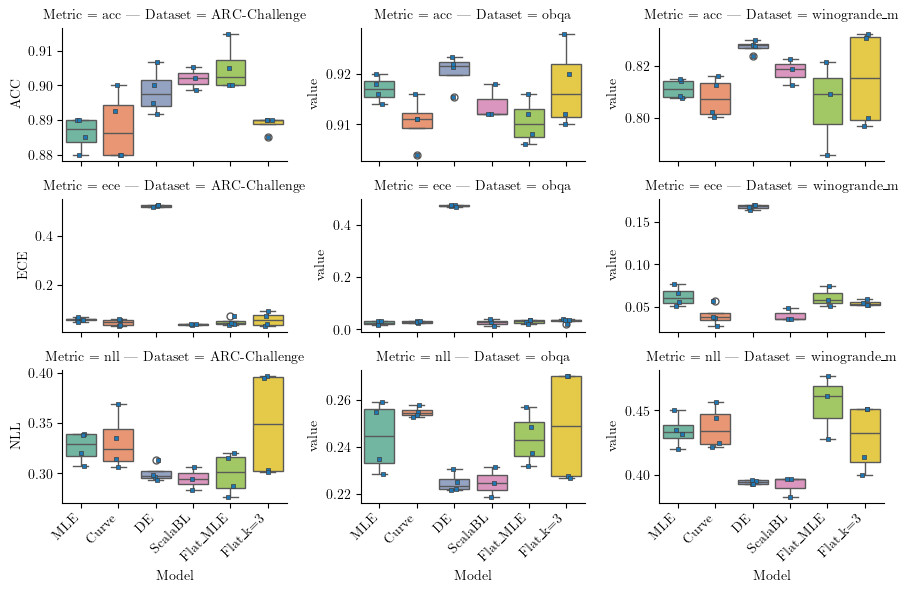

In [9]:
# Reference accuracy values from table 2
# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric']).mean().reset_index()
# Sort by Model order (MLE, Curve, DE, ScalaBL) and DegFreedom
# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset2[(df_subset2['Metric'] == row_name) & (df_subset2['Dataset'] == col_name)],
            x='Model',
            y='value',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()


### Curve length with adding delta w

In [4]:
api = wandb.Api()
results = []


for s in ["4lzudwro",]: # 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        space = len(run.config['curve_params']['cp_fix'])
        if space == 1:
            acc=run.summary.get(f"cp_fixed_0_post_pred_test_mean_acc", 0)
            ece=run.summary.get(f"cp_fixed_0_post_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"cp_fixed_0_post_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
                acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
                ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
                nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
                test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
                test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
                std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
                mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
            else:
                acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
                ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
                nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

                test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
                test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
                std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
                mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            DegFreedom=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Model=f"Flat_MLE",
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)

df = pd.DataFrame(results)
# df['CurveSpace'] = df['CurveSpace'].apply(lambda x: 'MLE' if x == 0 else f'Curve_{x}')
df.head()

4lzudwro:   0%|          | 0/72 [00:00<?, ?it/s, whole-sweep-53]      

4lzudwro: 100%|██████████| 72/72 [00:00<00:00, 276.02it/s, lemon-sweep-25]        


Skipping lunar-sweep-18 because it is not finished
Skipping feasible-sweep-17 because it is not finished
Skipping silvery-sweep-16 because it is not finished
Skipping atomic-sweep-15 because it is not finished
Skipping exalted-sweep-14 because it is not finished
Skipping fluent-sweep-13 because it is not finished
Skipping dry-sweep-6 because it is not finished
Skipping breezy-sweep-5 because it is not finished
Skipping silver-sweep-4 because it is not finished
Skipping swift-sweep-3 because it is not finished
Skipping cool-sweep-2 because it is not finished
Skipping effortless-sweep-1 because it is not finished


,Id,DegFreedom,CpFix,Model,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,...,Tsample,LoraRho,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,k4olxcic,1,[1],Flat_MLE,0,2,0.01,obqa,ppd,minibatch,...,per_leaf,0.0,0.0,0.906,0.036953,0.279377,-inf,-inf,-inf,-inf
1,yriutusa,1,[1],Flat_MLE,0,1,0.01,obqa,ppd,minibatch,...,per_leaf,0.0,0.0,0.904,0.019531,0.255603,-inf,-inf,-inf,-inf
2,io8c8o82,1,[1],Flat_MLE,0,2,0.01,obqa,ppd,minibatch,...,per_leaf,0.1,0.0,0.916,0.031477,0.215207,-inf,-inf,-inf,-inf
3,nr37slbq,1,[1],Flat_MLE,0,1,0.01,obqa,ppd,minibatch,...,per_leaf,0.1,0.0,0.908,0.038449,0.237949,-inf,-inf,-inf,-inf
4,yxlcgs33,1,[1],Flat_MLE,0,2,0.01,obqa,ppd,minibatch,...,per_leaf,0.5,0.0,0.904,0.027926,0.252398,-inf,-inf,-inf,-inf


In [5]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,DegFreedom,CpFix,Model,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,LoraRho,,,,,,,,


In [14]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
DegFreedom [1 3]
CpFix ['[1]' '[0, 0, 0]' '[1, 0, 1]']
Model ['Flat_MLE']
Jitter [0]
Seed [2 1]
WeightDecay [0.01]
Dataset ['obqa' 'winogrande_m']
Metric ['ppd']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['A(t)B(t)' 'Asd(t)B']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['per_leaf']
LoraRho [0.  0.1 0.5]

Experiment differs in ['DegFreedom', 'CpFix', 'Dataset', 'LoraMode', 'LoraRho'] configs


array(['obqa', 'winogrande_m'], dtype=object)

#### curve length

In [15]:
df_clean[variable_idx + ['bezierLength']].groupby(variable_idx).describe()

bezierLength             \
                                                          count       mean   
DegFreedom CpFix     Dataset      LoraMode LoraRho                           
1          [1]       obqa         A(t)B(t) 0.0              2.0   0.000000   
                                           0.1              2.0   0.000000   
                                           0.5              2.0   0.000000   
                                  Asd(t)B  0.0              2.0   0.000000   
                                           0.1              2.0   0.000000   
                                           0.5              2.0   0.000000   
                     winogrande_m A(t)B(t) 0.0              2.0   0.000000   
                                           0.1              2.0   0.000000   
                                           0.5              2.0   0.000000   
                                  Asd(t)B  0.0              2.0   0.000000   
                                           0.1              2.0   0.000000   
                                           0.5              2.0   0.000000   
3          [0, 0, 0] obqa         A(t)B(t) 0.0              2.0  25.395664   
                                           0.1              2.0  25.333452   
                                           0.5              2.0  25.766871   
                                  Asd(t)B  0.0              2.0  41.538078   
                                           0.1              2.0  41.545992   
                                           0.5              2.0  41.534657   
                     winogrande_m A(t)B(t) 0.0              2.0  24.910491   
                                           0.1              2.0  24.898174   
                                           0.5              2.0  25.623293   
                                  Asd(t)B  0.0              2.0  41.610138   
                                           0.1              2.0  41.621960   
                                           0.5              2.0  41.551245   
           [1, 0, 1] obqa         A(t)B(t) 0.0              2.0  26.690658   
                                           0.1              2.0  26.588102   
                                           0.5              2.0  28.143085   
                     winogrande_m A(t)B(t) 0.0              2.0  25.707582   
                                           0.1              2.0  25.973811   
                                           0.5              2.0  28.455189   

                                                                         \
                                                         std        min   
DegFreedom CpFix     Dataset      LoraMode LoraRho                        
1          [1]       obqa         A(t)B(t) 0.0      0.000000   0.000000   
                                           0.1      0.000000   0.000000   
                                           0.5      0.000000   0.000000   
                                  Asd(t)B  0.0      0.000000   0.000000   
                                           0.1      0.000000   0.000000   
                                           0.5      0.000000   0.000000   
                     winogrande_m A(t)B(t) 0.0      0.000000   0.000000   
                                           0.1      0.000000   0.000000   
                                           0.5      0.000000   0.000000   
                                  Asd(t)B  0.0      0.000000   0.000000   
                                           0.1      0.000000   0.000000   
                                           0.5      0.000000   0.000000   
3          [0, 0, 0] obqa         A(t)B(t) 0.0      0.252590  25.217056   
                                           0.1      0.203942  25.189243   
                                           0.5      0.057558  25.726171   
                                  Asd(t)B  0.0      0.005303  41.534328   
                                           0.1     

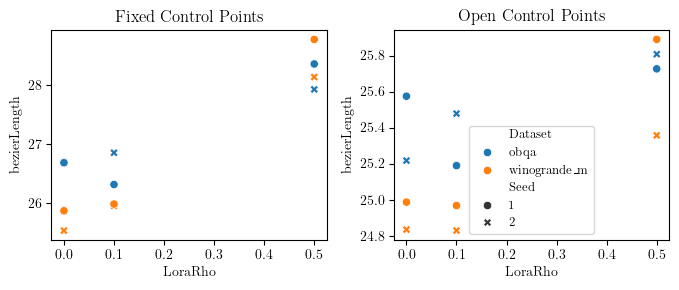

In [16]:
from copy import deepcopy
df_length = df_clean[df_clean['CpFix'] != '[1]']
df_length = df_length[df_length['LoraMode'] == 'A(t)B(t)']
ids = deepcopy(variable_idx)
ids.remove('CpFix')
df_fix = df_length[df_length['CpFix'] == "[1, 0, 1]"].set_index(ids)
df_open = df_length[df_length['CpFix'] == "[0, 0, 0]"].set_index(ids)


fig, ax = plt.subplots(1,2, figsize=(7,3))
sns.scatterplot(data=df_fix.reset_index(), x='LoraRho', y='bezierLength', hue='Dataset', style='Seed', ax=ax[0], legend=False)
sns.scatterplot(data=df_open.reset_index(), x='LoraRho', y='bezierLength', hue='Dataset', style='Seed', ax=ax[1])
ax[0].set_title("Fixed Control Points")
ax[1].set_title("Open Control Points")
plt.tight_layout()

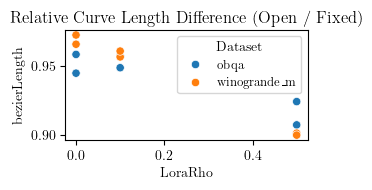

In [17]:
df_rel_diff = df_open['bezierLength'] / df_fix['bezierLength']

ax = sns.scatterplot(data=df_rel_diff.reset_index(), x='LoraRho', y='bezierLength', hue='Dataset')
ax.set_title("Relative Curve Length Difference (Open / Fixed)")
plt.tight_layout()

#### acc compare Entropy Scale

In [21]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['Dataset']!='ARC-Easy']
# df_subset = df_subset[df_subset['Dataset']!='winogrande_s']
# df_subset = df_subset[(df_subset['LoraRho']==0.) | (df_subset['LoraRho']==0.1) | (df_subset['LoraRho']==0.5)]
# df_subset = df_subset[((df_subset['Tsample']=='per_leaf') &  (df_subset['Model'].str.startswith("Flat_k")) & (df_subset['LoraMode'] == "A(t)B(t)")) | (~(df_subset['Model'].str.startswith("Flat_k")))]
# df_subset = df_subset[~((df_subset['Dataset'] == "winogrande_m") & (df_subset['Model'].str.startswith("Flat_k")) & (df_subset['LoraRho'] == 0.1))]
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
idx = ['Dataset', 'LoraMode', 'DegFreedom', 'CpFix', 'LoraRho']
df_subset.groupby(idx)[['acc', 'nll', 'ece']].mean()

acc       nll  \
Dataset      LoraMode DegFreedom CpFix     LoraRho                       
obqa         A(t)B(t) 1          [1]       0.0      0.905000  0.267490   
                                           0.1      0.912000  0.226578   
                                           0.5      0.907000  0.257908   
                      3          [0, 0, 0] 0.0      0.908000  0.248269   
                                           0.1      0.901000  0.270385   
                                           0.5      0.918000  0.252445   
                                 [1, 0, 1] 0.0      0.911000  0.256860   
                                           0.1      0.910000  0.231230   
                                           0.5      0.922000  0.257773   
             Asd(t)B  1          [1]       0.0      0.909000  0.265812   
                                           0.1      0.914000  0.232572   
                                           0.5      0.907000  0.251183   
                      3          [0, 0, 0] 0.0      0.912000  0.249494   
                                           0.1      0.916000  0.230124   
                                           0.5      0.911000  0.254408   
winogrande_m A(t)B(t) 1          [1]       0.0      0.807917  0.436633   
                                           0.1      0.800417  0.456057   
                                           0.5      0.818750  0.426393   
                      3          [0, 0, 0] 0.0      0.802083  0.457367   
                                           0.1      0.812500  0.448875   
                                           0.5      0.814583  0.425282   
                                 [1, 0, 1] 0.0      0.813333  0.461527   
                                           0.1      0.805000  0.458472   
                                           0.5      0.827083  0.417484   
             Asd(t)B  1          [1]       0.0      0.813333  0.431361   
                                           0.1      0.800417  0.458303   
                                           0.5      0.825417  0.426075   
                      3          [0, 0, 0] 0.0      0.806667  0.442788   
                                           0.1      0.807500  0.447952   
                                           0.5      0.825417  0.425332   

                                                         ece  
Dataset      LoraMode DegFreedom CpFix     LoraRho            
obqa         A(t)B(t) 1          [1]       0.0      0.028242  
                                           0.1      0.034963  
                                           0.5      0.033305  
                      3          [0, 0, 0] 0.0      0.033065  
                                           0.1      0.031969  
                                           0.5      0.033020  
                                 [1, 0, 1] 0.0      0.036763  
                                           0.1      0.029367  
                                           0.5      0.036976  
             Asd(t)B  1          [1]       0.0      0.036831  
                                           0.1      0.020924  
                                           0.5      0.035511  
                      3          [0, 0, 0] 0.0      0.030120  
                                           0.1      0.024384  
                                           0.5      0.031456  
winogrande_m A(t)B(t) 1          [1]       0.0      0.038755  
                                           0.1      0.053986  
                                           0.5      0.066116  
                      3          [0, 0, 0] 0.0      0.057935  
                                           0.1      0.060982  
                                           0.5      0.052327  
                                 [1, 0, 1] 0.0      0.073616  
                                           0.1      0.066751  
                                           0.5      0.065455  
             Asd(t)B  1          [1]       0.0    

### Flat-Lora + Tunnel 


In [4]:
api = wandb.Api()
results = []


for s in ["n0iky0l6",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            LoraRhoS=run.config['lora_params'].get('lora_rho_s', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)
 
df = pd.DataFrame(results)
df

n0iky0l6: 100%|██████████| 36/36 [00:00<00:00, 367.00it/s, distinctive-sweep-1]

,Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,LoraRho,LoraRhoS,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,b69djy6s,3,"[0, 0, 0]",0,2,0.01,obqa,ppd,minibatch,classic,...,0.0,1.0,25.676846,0.908000,0.026051,0.245066,0.243803,0.020234,0.003967,0.223569
1,73ih8wl4,3,"[0, 0, 0]",0,1,0.01,obqa,ppd,minibatch,classic,...,0.0,1.0,25.843540,0.906000,0.039538,0.261069,0.222965,0.028251,0.005733,0.194714
2,2zgkfnwq,3,"[0, 0, 0]",0,2,0.01,obqa,ppd,minibatch,classic,...,0.0,0.5,25.539959,0.920000,0.026425,0.229304,0.211175,0.013793,0.004242,0.197382
3,k02s6res,3,"[0, 0, 0]",0,1,0.01,obqa,ppd,minibatch,classic,...,0.0,0.5,25.229546,0.910000,0.039005,0.255059,0.213113,0.020589,0.007745,0.192523
4,83a3u0gd,3,"[0, 0, 0]",0,2,0.01,obqa,ppd,minibatch,classic,...,0.0,0.1,25.475342,0.926000,0.029099,0.227496,0.196354,0.012772,0.004925,0.183582
5,96ltvm8q,3,"[0, 0, 0]",0,1,0.01,obqa,ppd,minibatch,classic,...,0.0,0.1,25.527870,0.908000,0.026990,0.254022,0.233299,0.015580,0.004434,0.217719
6,0ykmewxr,3,"[0, 0, 0]",0,2,0.01,obqa,ppd,minibatch,classic,...,0.1,1.0,25.973606,0.912000,0.028739,0.252047,0.200528,0.036353,0.006318,0.164175
7,s2xm52ft,3,"[0, 0, 0]",0,1,0.01,obqa,ppd,minibatch,classic,...,0.1,1.0,25.830635,0.908000,0.021733,0.234735,0.258837,0.031907,0.007016,0.226930
8,1q7pubma,3,"[0, 0, 0]",0,2,0.01,obqa,ppd,minibatch,classic,...,0.1,0.5,25.555149,0.916000,0.016410,0.236861,0.215860,0.021721,0.004921,0.194139
9,rs6z5gl8,3,"[0, 0, 0]",0,1,0.01,obqa,ppd,minibatch,classic,...,0.1,0.5,25.614265,0.906000,0.048126,0.273151,0.197320,0.022594,0.005325,0.174726


In [5]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,LoraRho,LoraRhoS,,,,,,,,


In [6]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [3]
CpFix ['[0, 0, 0]']
Jitter [0]
Seed [2 1]
WeightDecay [0.01]
Dataset ['obqa' 'winogrande_m']
Metric ['ppd']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['per_leaf']
LoraRho [0.  0.1 0.5]
LoraRhoS [1.  0.5 0.1]

Experiment differs in ['Dataset', 'LoraRho', 'LoraRhoS'] configs


array(['obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [10]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']

df_subset['Config'] = df_subset.apply(lambda row: f"LM={row['LoraMode']}, Rho_s={row['LoraRhoS']}", axis=1)
# df_subset = df_subset[df_subset['Tsample'] == 'per_leaf']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset','LoraMode', 'CurveSpace', 'Tsample', 'LoraRho', 'LoraRhoS'])[['acc', 'nll', 'ece']].mean()

acc  \
Dataset      LoraMode  CurveSpace Tsample  LoraRho LoraRhoS             
obqa         A(t)eB(t) 3          per_leaf 0.0     0.1       0.917000   
                                                   0.5       0.915000   
                                                   1.0       0.907000   
                                           0.1     0.1       0.916000   
                                                   0.5       0.911000   
                                                   1.0       0.910000   
                                           0.5     0.1       0.901000   
                                                   0.5       0.904000   
                                                   1.0       0.895000   
winogrande_m A(t)eB(t) 3          per_leaf 0.0     0.1       0.805417   
                                                   0.5       0.815000   
                                                   1.0       0.812917   
                                           0.1     0.1       0.797917   
                                                   0.5       0.796667   
                                                   1.0       0.793333   
                                           0.5     0.1       0.800000   
                                                   0.5       0.795417   
                                                   1.0       0.778750   

                                                                  nll  \
Dataset      LoraMode  CurveSpace Tsample  LoraRho LoraRhoS             
obqa         A(t)eB(t) 3          per_leaf 0.0     0.1       0.240759   
                                                   0.5       0.242182   
                                                   1.0       0.253067   
                                           0.1     0.1       0.219422   
                                                   0.5       0.255006   
                                                   1.0       0.243391   
                                           0.5     0.1       0.277890   
                                                   0.5       0.258900   
                                                   1.0       0.267120   
winogrande_m A(t)eB(t) 3          per_leaf 0.0     0.1       0.453580   
                                                   0.5       0.451779   
                                                   1.0       0.452759   
                                           0.1     0.1       0.462287   
                                                   0.5       0.460223   
                                                   1.0       0.471285   
                                           0.5     0.1       0.437385   
                                                   0.5       0.454322   
                                                   1.0       0.513226   

                                                                  ece  
Dataset      LoraMode  CurveSpace Tsample  LoraRho LoraRhoS            
obqa         A(t)eB(t) 3          per_leaf 0.0     0.1       0.028045  
                                                   0.5       0.032715  
                                                   1.0       0.032794  
                                           0.1     0.1       0.025126  
                                                   0.5       0.032268  
                                                   1.0       0.025236  
                                           0.5     0.1       0.044826  
                                                   0.5       0.027886  
                                                   1.0       0.041139  
winogrande_m A(t)eB(t) 3          per_leaf 0.0     0.1       0.062514  
                                                   0.5       0.059537  
                                                   1.0       0.065103  
                                           0.1     0.1       0.060297  
                                                   0.5       0.0

/tmp/ipykernel_135381/3071046440.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_135381/3071046440.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


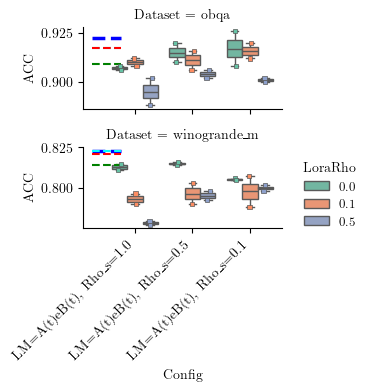

In [11]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

df_subset['LoraRho'] = df_subset['LoraRho'].astype(str)
numeric_rhos = sorted(df_subset['LoraRho'].astype(float).unique())
hue_order = [str(x) for x in numeric_rhos]

# # Filter out bad runs with dataset-specific thresholds
# min_acc = {
#     'ARC-Easy': 0.85,
#     'obqa': 0.83,
#     'ARC-Challenge': 0.85,
#     'boolq': 0.65,
#     'winogrande_m': 0.7,
#     'winogrande_s': 0.55
# }
# df_subset = df_subset[df_subset['acc'] > df_subset['Dataset'].map(min_acc).fillna(0)]

# # df_subset = df_subset[df_subset['Config']==0]
# hue_order = list(df_subset['LoraRho'].unique())
# hue_order.sort()
# # hue_order = None
# # hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='Config', y='acc', hue='LoraRho', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        # entropy_scale = ax.get_title().split('=')[2].strip()
        # print(ds, entropy_scale)
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
            data=df_subset[(df_subset['Dataset'] == ds)],
            x='Config',
            y='acc',
            hue='LoraRho',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    # print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    # print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
# g.set_xticklabels(rotation=90, ha='center')
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_135381/2861870824.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_135381/2861870824.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


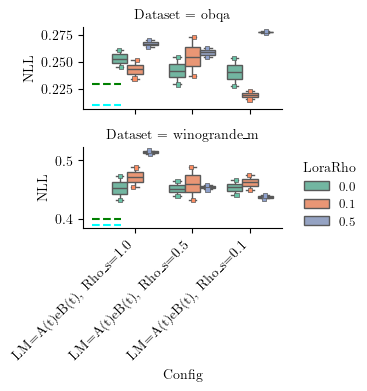

In [12]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='Config', y='nll', hue='LoraRho', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    # entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        data=df_subset[(df_subset['Dataset'] == ds)],
        x='Config',
        y='nll',
        hue='LoraRho',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_135381/166450926.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_135381/166450926.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


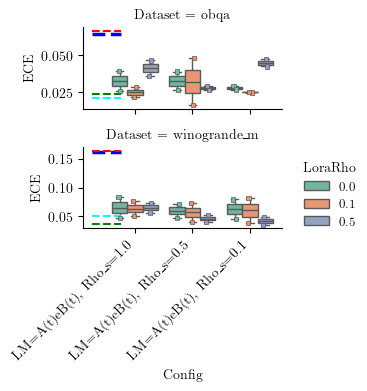

In [13]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='Config', y='ece', hue='LoraRho', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    # entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        data=df_subset[(df_subset['Dataset'] == ds)],
        x='Config',
        y='ece',
        hue='LoraRho',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed

for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

### Flat-Lora + Tunnel 


In [3]:
api = wandb.Api()
results = []


for s in ["j4c2yysv",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "combined":
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        else:
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            LoraRhoS=run.config['lora_params'].get('lora_rho_s', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)
 
df = pd.DataFrame(results)
df

j4c2yysv:   2%|▏         | 31/1440 [00:00<00:05, 277.55it/s, lilac-sweep-1393]   

Skipping scarlet-sweep-1440 because it is not finished
Skipping electric-sweep-1439 because it is not finished
Skipping amber-sweep-1438 because it is not finished
Skipping usual-sweep-1437 because it is not finished
Skipping deft-sweep-1432 because it is not finished
Skipping elated-sweep-1431 because it is not finished
Skipping eternal-sweep-1430 because it is not finished
Skipping vital-sweep-1429 because it is not finished
Skipping prime-sweep-1424 because it is not finished
Skipping bumbling-sweep-1423 because it is not finished
Skipping autumn-sweep-1422 because it is not finished
Skipping earthy-sweep-1421 because it is not finished
Skipping helpful-sweep-1416 because it is not finished
Skipping warm-sweep-1415 because it is not finished
Skipping lunar-sweep-1414 because it is not finished
Skipping azure-sweep-1413 because it is not finished
Skipping snowy-sweep-1408 because it is not finished
Skipping fresh-sweep-1407 because it is not finished
Skipping swept-sweep-1406 because

j4c2yysv:  12%|█▏        | 171/1440 [00:00<00:02, 570.79it/s, lilac-sweep-1393]

Skipping blooming-sweep-1398 because it is not finished
Skipping jolly-sweep-1397 because it is not finished
Skipping summer-sweep-1396 because it is not finished
Skipping amber-sweep-1395 because it is not finished
Skipping northern-sweep-1394 because it is not finished
Skipping true-sweep-1393 because it is not finished
Skipping hopeful-sweep-1392 because it is not finished
Skipping firm-sweep-1391 because it is not finished
Skipping vivid-sweep-1390 because it is not finished
Skipping frosty-sweep-1389 because it is not finished
Skipping tough-sweep-1388 because it is not finished
Skipping faithful-sweep-1387 because it is not finished
Skipping solar-sweep-1386 because it is not finished
Skipping denim-sweep-1385 because it is not finished
Skipping royal-sweep-1384 because it is not finished
Skipping sandy-sweep-1383 because it is not finished
Skipping curious-sweep-1382 because it is not finished
Skipping lyric-sweep-1381 because it is not finished
Skipping cosmic-sweep-1380 becaus

j4c2yysv:  22%|██▏       | 311/1440 [00:00<00:01, 634.73it/s, peach-sweep-1116]

Skipping blooming-sweep-1248 because it is not finished
Skipping electric-sweep-1247 because it is not finished
Skipping woven-sweep-1246 because it is not finished
Skipping glowing-sweep-1245 because it is not finished
Skipping fresh-sweep-1244 because it is not finished
Skipping dainty-sweep-1243 because it is not finished
Skipping super-sweep-1242 because it is not finished
Skipping atomic-sweep-1241 because it is not finished
Skipping visionary-sweep-1240 because it is not finished
Skipping sunny-sweep-1239 because it is not finished
Skipping worthy-sweep-1238 because it is not finished
Skipping driven-sweep-1237 because it is not finished
Skipping lunar-sweep-1236 because it is not finished
Skipping comfy-sweep-1235 because it is not finished
Skipping toasty-sweep-1234 because it is not finished
Skipping decent-sweep-1233 because it is not finished
Skipping sparkling-sweep-1232 because it is not finished
Skipping apricot-sweep-1231 because it is not finished
Skipping eager-sweep-1

... (18 outputs left out)

j4c2yysv: 100%|█████████▉| 1437/1440 [00:03<00:00, 228.26it/s, generous-sweep-1]  

Skipping cerulean-sweep-40 because it is not finished
Skipping elated-sweep-39 because it is not finished
Skipping firm-sweep-38 because it is not finished
Skipping confused-sweep-37 because it is not finished
Skipping olive-sweep-32 because it is not finished
Skipping honest-sweep-31 because it is not finished
Skipping dandy-sweep-30 because it is not finished
Skipping desert-sweep-29 because it is not finished
Skipping playful-sweep-24 because it is not finished
Skipping apricot-sweep-23 because it is not finished
Skipping zesty-sweep-21 because it is not finished
Skipping deep-sweep-20 because it is not finished
Skipping still-sweep-19 because it is not finished
Skipping serene-sweep-18 because it is not finished
Skipping trim-sweep-17 because it is not finished
Skipping sage-sweep-10 because it is not finished


j4c2yysv: 100%|██████████| 1440/1440 [00:03<00:00, 448.80it/s, generous-sweep-1]


,Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,LoraRho,LoraRhoS,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,m7f3vv0u,6,"[0, 0, 0, 0, 0, 0]",0,8000,0.01,obqa,ppd,minibatch,classic,...,0.5,0.5,36.923859,0.902000,0.039203,0.294302,0.274235,0.079868,0.008648,0.194367
1,sfbqjlio,6,"[0, 0, 0, 0, 0, 0]",0,400,0.01,obqa,ppd,minibatch,classic,...,0.5,0.5,37.026894,0.908000,0.029389,0.254967,0.276296,0.075497,0.010158,0.200800
2,m3swcm25,6,"[0, 0, 0, 0, 0, 0]",0,20,0.01,obqa,ppd,minibatch,classic,...,0.5,0.5,36.921234,0.920000,0.030933,0.264135,0.311635,0.075922,0.008481,0.235713
3,2zelwg5j,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,obqa,ppd,minibatch,classic,...,0.5,0.5,37.080284,0.902000,0.049552,0.270472,0.260739,0.079364,0.008262,0.181375
4,k1e5hmp2,6,"[0, 0, 0, 0, 0, 0]",0,8000,0.01,obqa,ppd,minibatch,classic,...,0.5,0.1,36.902191,0.898000,0.032954,0.272732,0.280622,0.076187,0.008444,0.204434
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208,2q81vtfw,3,"[0, 0, 0]",0,400,0.01,winogrande_m,ppd,minibatch,classic,...,0.5,0.1,25.292877,0.826667,0.067724,0.430638,0.332653,0.081354,0.004683,0.251300
209,cztdux5e,3,"[0, 0, 0]",0,8000,0.01,winogrande_m,ppd,minibatch,classic,...,0.5,0.0,25.218988,0.822500,0.043267,0.410260,0.358394,0.078823,0.004301,0.279571
210,qk2q0erb,3,"[0, 0, 0]",0,400,0.01,winogrande_m,ppd,minibatch,classic,...,0.5,0.0,25.190018,0.815833,0.031814,0.422703,0.414276,0.069923,0.004631,0.344353
211,ulaa75a5,3,"[0, 0, 0]",0,20,0.01,winogrande_m,ppd,minibatch,classic,...,0.5,0.0,24.946373,0.803333,0.019541,0.431952,0.478131,0.070697,0.003801,0.407434


In [4]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,LoraRho,LoraRhoS,,,,,,,,


In [5]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [6 3]
CpFix ['[0, 0, 0, 0, 0, 0]' '[0, 0, 0]']
Jitter [0]
Seed [8000  400   20    1]
WeightDecay [0.01]
Dataset ['obqa' 'winogrande_m' 'ARC-Challenge']
Metric ['ppd']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['A(t)eB' 'Asd(t)eB']
CurveMode ['bezier']
LoraRank [  8 224]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_noBMA']
LoraRho [0.5 0.  0.1]
LoraRhoS [0.5 0.1 0.  2.  1. ]

Experiment differs in ['CurveSpace', 'CpFix', 'Dataset', 'LoraMode', 'LoraRank', 'LoraRho', 'LoraRhoS'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [10]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']

df_subset['Config'] = df_subset.apply(lambda row: f"K={row['CpFix']} LM={row['LoraMode']}, r={row['LoraRank']}", axis=1)
# df_subset = df_subset[df_subset['Tsample'] == 'per_leaf']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset','LoraMode', 'CurveSpace', 'Tsample', 'LoraRho', 'LoraRhoS'])[['acc', 'nll', 'ece']].mean()

acc  \
Dataset       LoraMode CurveSpace Tsample        LoraRho LoraRhoS             
ARC-Challenge A(t)eB   3          combined_noBMA 0.0     1.0       0.885000   
                                                 0.1     1.0       0.915000   
              Asd(t)eB 3          combined_noBMA 0.0     2.0       0.875000   
obqa          A(t)eB   3          combined_noBMA 0.1     0.0       0.908000   
                                                 0.5     0.0       0.899500   
                                                         0.1       0.900000   
                                                         0.5       0.903000   
                       6          combined_noBMA 0.0     0.0       0.920000   
                                                 0.5     0.0       0.898000   
                                                         0.1       0.907000   
                                                         0.5       0.908000   
              Asd(t)eB 3          combined_noBMA 0.0     1.0       0.918000   
                       6          combined_noBMA 0.5     0.5       0.890000   
                                                         2.0       0.848000   
winogrande_m  A(t)eB   3          combined_noBMA 0.0     0.0       0.816458   
                                                         0.1       0.807500   
                                                         0.5       0.810500   
                                                         1.0       0.804375   
                                                         2.0       0.804833   
                                                 0.1     0.0       0.808125   
                                                         0.1       0.804000   
                                                         0.5       0.814722   
                                                         1.0       0.806429   
                                                         2.0       0.804833   
                                                 0.5     0.0       0.811146   
                                                         0.1       0.813810   
                                                         0.5       0.806667   
                                                         1.0       0.801667   
                                                         2.0       0.732500   
              Asd(t)eB 3          combined_noBMA 0.0     0.0       0.812262   
                                                         0.1       0.814167   
                                                         0.5       0.813000   
                                                         1.0       0.811786   
                                                 0.1     0.0       0.809583   
                                                         0.1       0.807500   
                                                         0.5       0.815521   
                                                         1.0       0.808542   
                                                         2.0       0.802708   
                                                 0.5     0.0       0.808646   
                                                         0.1       0.811667   
                                                         0.5       0.813438   
                                                         1.0       0.807604   
                                                         2.0       0.756146   
                       6          combined_noBMA 0.0     0.5       0.802500   

                                                                        nll  \
Dataset       LoraMode CurveSpace Tsample        LoraRho LoraRhoS             
ARC-Challenge A(t)eB   3          combined_noBMA 0.0     1.0       0.325099   
                                                 0.1     1.0       0.317475   
              Asd(t)eB 3          combined_noBMA 0.0     2.0       0.346677   
obqa          A(t)eB   3          combined

/tmp/ipykernel_206514/508001092.py:43: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/508001092.py:43: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/508001092.py:43: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/508001092.py:43: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/508001092.py:43: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/508001092.py:43: FutureWarning: Use "auto" to set automatic grayscale colors. From 

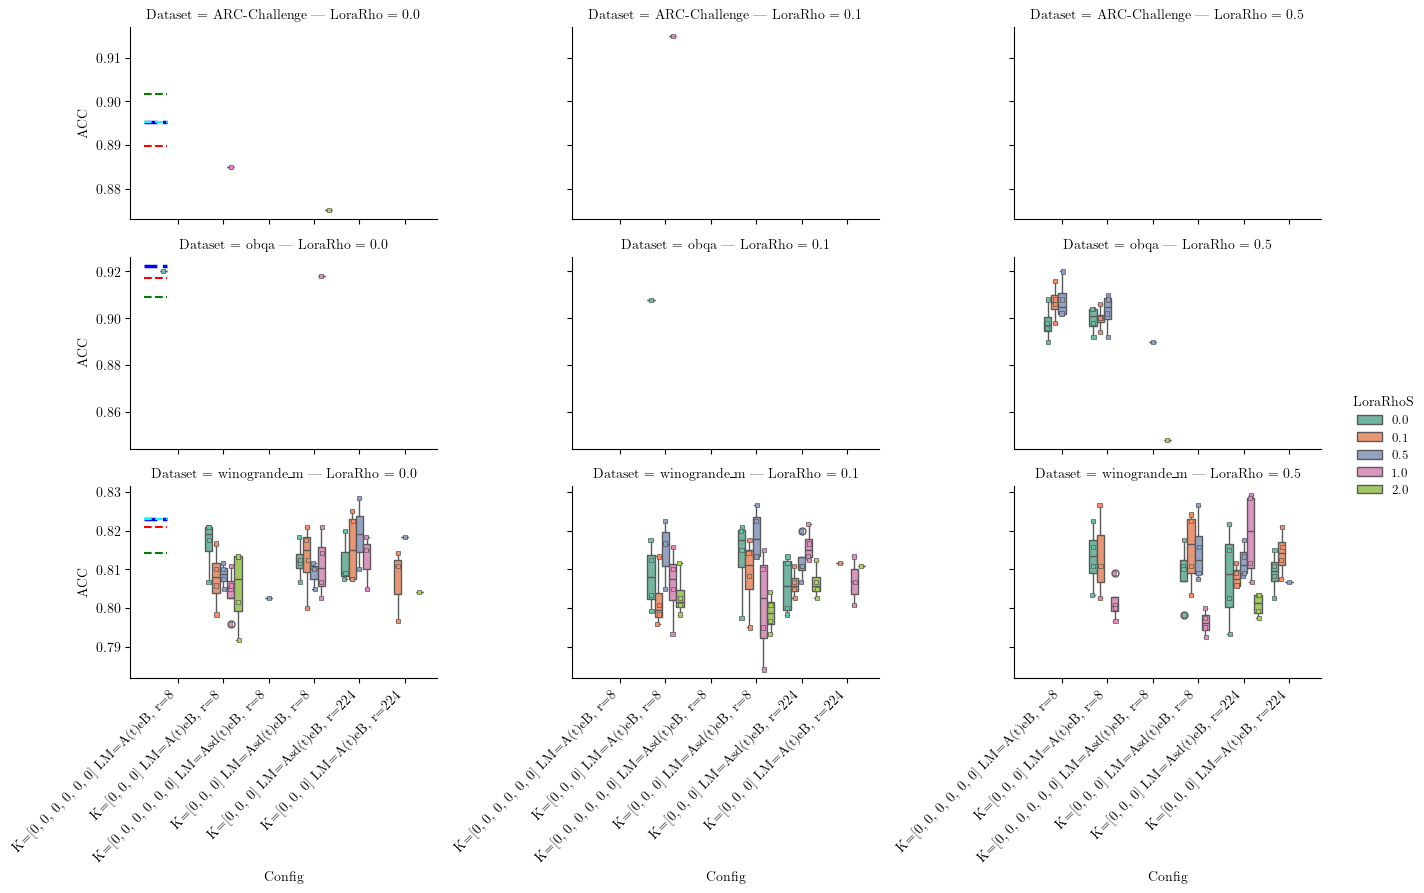

In [11]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

df_subset['LoraRhoS'] = df_subset['LoraRhoS'].astype(str)
numeric_rhos = sorted(df_subset['LoraRhoS'].astype(float).unique())
hue_order = [str(x) for x in numeric_rhos]

# # Filter out bad runs with dataset-specific thresholds
min_acc = {
    'ARC-Easy': 0.85,
    'obqa': 0.83,
    'ARC-Challenge': 0.85,
    'boolq': 0.65,
    'winogrande_m': 0.76,
    'winogrande_s': 0.55
}
df_subset = df_subset[df_subset['acc'] > df_subset['Dataset'].map(min_acc).fillna(0)]

# # df_subset = df_subset[df_subset['Config']==0]
# hue_order = list(df_subset['LoraRhoS'].unique())
# hue_order.sort()
# # hue_order = None
# # hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='Config', y='acc', hue='LoraRhoS', kind='box', row='Dataset', col='LoraRho', sharey='row', palette='Set2', height=figsize[1]*1.5, row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        entropy_scale = ax.get_title().split('=')[2].strip()
        entropy_scale = float(entropy_scale)
        # print(ds, entropy_scale)
        # print(type(entropy_scale))
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['LoraRho'] == entropy_scale)],
            # data=df_subset[(df_subset['Dataset'] == ds)],
            x='Config',
            y='acc',
            hue='LoraRhoS',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    # print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    # print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
# g.set_xticklabels(rotation=90, ha='center')
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_206514/3319792652.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/3319792652.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/3319792652.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/3319792652.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/3319792652.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/3319792652.py:24: FutureWarning: Use "auto" to set automatic grayscale colors.

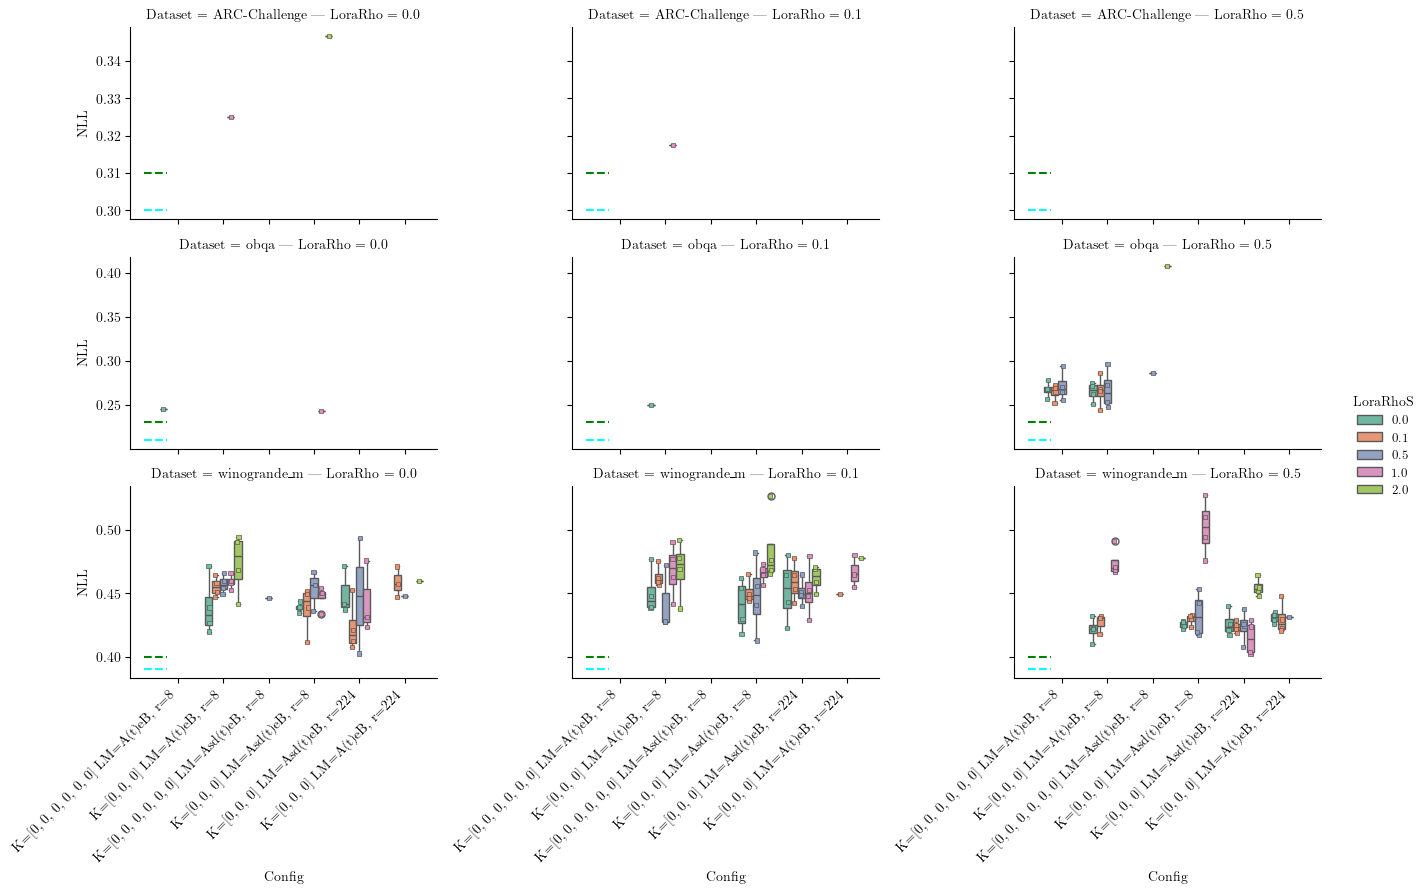

In [12]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='Config', y='nll', hue='LoraRhoS', kind='box', row='Dataset', col='LoraRho', sharey='row', palette='Set2', height=figsize[1]*1.5, row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    entropy_scale = float(entropy_scale)
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['LoraRho'] == entropy_scale)],
        # data=df_subset[(df_subset['Dataset'] == ds)],
        x='Config',
        y='nll',
        hue='LoraRhoS',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_206514/1966538968.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/1966538968.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/1966538968.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/1966538968.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/1966538968.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_206514/1966538968.py:19: FutureWarning: Use "auto" to set automatic grayscale colors.

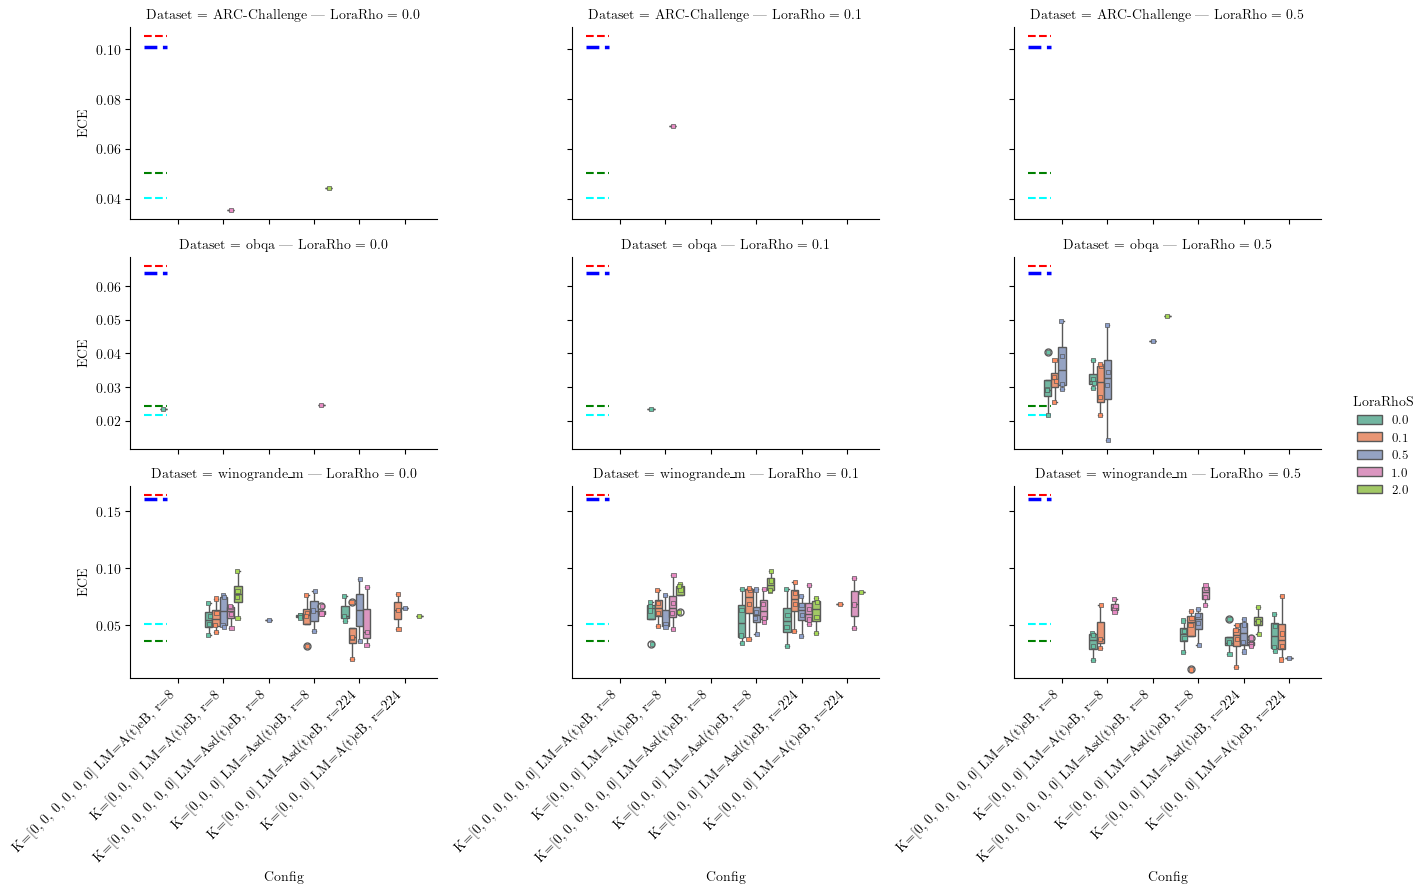

In [13]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='Config', y='ece', hue='LoraRhoS', kind='box', row='Dataset', col='LoraRho', sharey='row', palette='Set2', height=figsize[1]*1.5, row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    entropy_scale = float(entropy_scale)
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['LoraRho'] == entropy_scale)],
        # data=df_subset[(df_subset['Dataset'] == ds)],
        x='Config',
        y='ece',
        hue='LoraRhoS',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed

for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

### Rotation Tunnel 


In [24]:
api = wandb.Api()
results = []


for s in ["n3kqizw0",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "combined":
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        else:
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            LoraRhoS=run.config['lora_params'].get('lora_rho_s', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)
 
df = pd.DataFrame(results)
df

n3kqizw0: 100%|██████████| 12/12 [00:00<00:00, 376.87it/s, azure-sweep-1]


,Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,LoraRho,LoraRhoS,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,movlp1ua,3,"[0, 0, 0]",0,8000,0.01,ARC-Challenge,ppd,minibatch,classic,...,0.1,0.1,24.053976,0.825000,0.169852,0.567717,0.911382,0.057685,0.010855,0.853697
1,vhuqj826,3,"[0, 0, 0]",0,400,0.01,ARC-Challenge,ppd,minibatch,classic,...,0.1,0.1,24.074715,0.840000,0.182616,0.559075,0.914334,0.057978,0.010513,0.856356
2,k0ay49be,3,"[0, 0, 0]",0,20,0.01,ARC-Challenge,ppd,minibatch,classic,...,0.1,0.1,24.055702,0.820000,0.151748,0.573083,0.912393,0.057897,0.015941,0.854496
3,jdgdg0pt,3,"[0, 0, 0]",0,1,0.01,ARC-Challenge,ppd,minibatch,classic,...,0.1,0.1,24.075752,0.830000,0.160009,0.576544,0.916947,0.058218,0.013453,0.858730
4,zazccitc,3,"[0, 0, 0]",0,8000,0.01,obqa,ppd,minibatch,classic,...,0.1,0.1,24.053976,0.780000,0.127359,0.671708,0.934492,0.064043,0.007644,0.870449
5,3s8p4s2h,3,"[0, 0, 0]",0,400,0.01,obqa,ppd,minibatch,classic,...,0.1,0.1,24.074715,0.768000,0.124317,0.680992,0.930664,0.064781,0.012534,0.865882
6,po50sx7z,3,"[0, 0, 0]",0,20,0.01,obqa,ppd,minibatch,classic,...,0.1,0.1,24.055702,0.780000,0.140028,0.668193,0.934026,0.064012,0.007523,0.870014
7,sg1eolgs,3,"[0, 0, 0]",0,1,0.01,obqa,ppd,minibatch,classic,...,0.1,0.1,24.075752,0.782000,0.140153,0.674609,0.936964,0.067508,0.009025,0.869456
8,g2x9axj6,3,"[0, 0, 0]",0,8000,0.01,winogrande_m,ppd,minibatch,classic,...,0.1,0.1,24.053976,0.636667,0.120350,0.703100,0.501105,0.039885,0.006591,0.461220
9,lqjivrmn,3,"[0, 0, 0]",0,400,0.01,winogrande_m,ppd,minibatch,classic,...,0.1,0.1,24.074715,0.642500,0.117265,0.699205,0.502619,0.040682,0.006001,0.461936


In [25]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,LoraRho,LoraRhoS,,,,,,,,


In [26]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [3]
CpFix ['[0, 0, 0]']
Jitter [0]
Seed [8000  400   20    1]
WeightDecay [0.01]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m']
Metric ['ppd']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['Arot(t)sdeBrot(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_noBMA']
LoraRho [0.1]
LoraRhoS [0.1]

Experiment differs in ['Dataset'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [27]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']

df_subset['Config'] = df_subset.apply(lambda row: f"LM={row['LoraMode']}, Rho_s={row['LoraRhoS']}", axis=1)
# df_subset = df_subset[df_subset['Tsample'] == 'per_leaf']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset','LoraMode', 'CurveSpace', 'Tsample', 'LoraRho', 'LoraRhoS'])[['acc', 'nll', 'ece']].mean()

,,,,,,acc,nll,ece
Dataset,LoraMode,CurveSpace,Tsample,LoraRho,LoraRhoS,,,
ARC-Challenge,Arot(t)sdeBrot(t),3,combined_noBMA,0.1,0.1,0.82875,0.569105,0.166056
obqa,Arot(t)sdeBrot(t),3,combined_noBMA,0.1,0.1,0.77750,0.673875,0.132964
winogrande_m,Arot(t)sdeBrot(t),3,combined_noBMA,0.1,0.1,0.63750,0.699879,0.117052


/tmp/ipykernel_193706/3071046440.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_193706/3071046440.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_193706/3071046440.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


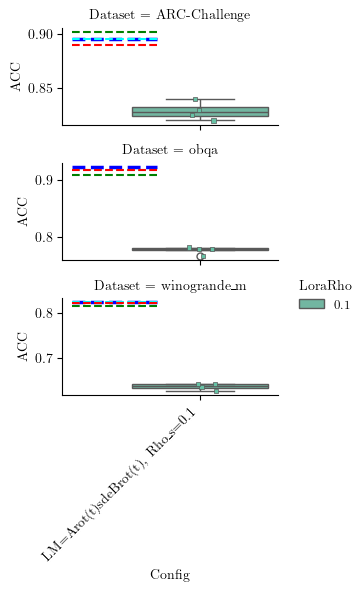

In [28]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

df_subset['LoraRho'] = df_subset['LoraRho'].astype(str)
numeric_rhos = sorted(df_subset['LoraRho'].astype(float).unique())
hue_order = [str(x) for x in numeric_rhos]

# # Filter out bad runs with dataset-specific thresholds
# min_acc = {
#     'ARC-Easy': 0.85,
#     'obqa': 0.83,
#     'ARC-Challenge': 0.85,
#     'boolq': 0.65,
#     'winogrande_m': 0.7,
#     'winogrande_s': 0.55
# }
# df_subset = df_subset[df_subset['acc'] > df_subset['Dataset'].map(min_acc).fillna(0)]

# # df_subset = df_subset[df_subset['Config']==0]
# hue_order = list(df_subset['LoraRho'].unique())
# hue_order.sort()
# # hue_order = None
# # hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='Config', y='acc', hue='LoraRho', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        # entropy_scale = ax.get_title().split('=')[2].strip()
        # print(ds, entropy_scale)
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
            data=df_subset[(df_subset['Dataset'] == ds)],
            x='Config',
            y='acc',
            hue='LoraRho',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    # print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    # print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
# g.set_xticklabels(rotation=90, ha='center')
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_193706/2861870824.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_193706/2861870824.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_193706/2861870824.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


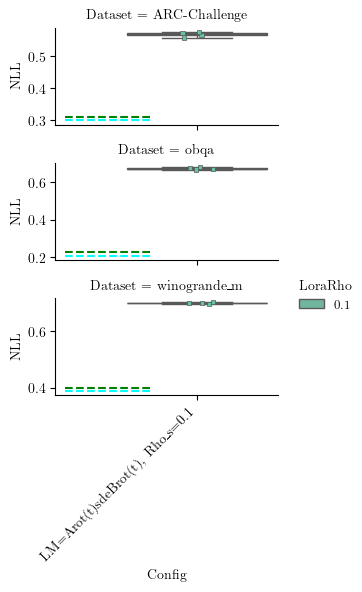

In [29]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='Config', y='nll', hue='LoraRho', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    # entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        data=df_subset[(df_subset['Dataset'] == ds)],
        x='Config',
        y='nll',
        hue='LoraRho',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_193706/166450926.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_193706/166450926.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_193706/166450926.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


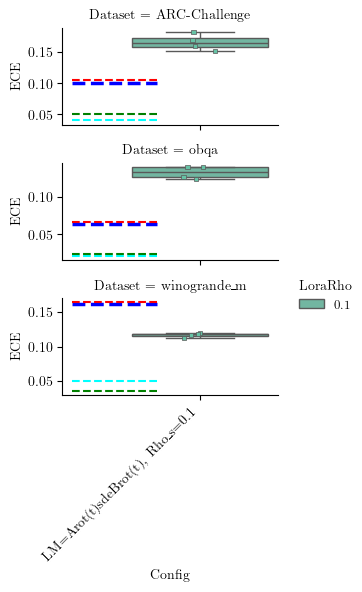

In [30]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='Config', y='ece', hue='LoraRho', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    # entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        data=df_subset[(df_subset['Dataset'] == ds)],
        x='Config',
        y='ece',
        hue='LoraRho',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed

for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

### FixedPoints compare with VI vs DE vs MLE vs Curve


In [3]:
api = wandb.Api()
results = []

for s in ["20h06muz",]: # Fixed Control Points training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="Curve (Fixed CP)",
            DegFreedom=len(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

for s in ["0zkos614",]: # Curve training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="MLE" if run.config['curve_params']['k'] == 0 else "Curve",
            DegFreedom=run.config['curve_params']['k'] + 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        # res = dict(Id=run.id,
        # #    CurveSpace=f"{run.config['curve_params']['k']}",
        #     CurveSpace=run.config['curve_params']['k'],
        #     Jitter=run.config['curve_params']['jitter_multiplier'],
        #     Seed=run.config['rng_seed'],
        #     WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
        #     Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        #     Metric="mean",
        #     DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
        #     DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
        #     DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
        #     EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
        #     NumSteps=run.config['curve_params'].get('num_steps', -1),
        #     LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
        #     CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
        #     LoraRank=run.config['lora_params'].get('r', -1),
        #     RegularizationMode=run.config['curve_params'].get('regularizer', False),
        #     Gravity=run.config['curve_params'].get('gravity', 0.),
        #     EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
        #     bezierLength=run.summary.get('Curve length', 0),
        #     acc=run.summary.get(f"post_pred_test_mean_acc", 0),
        #     ece=run.summary.get(f"post_pred_test_mean_ece", 0),
        #     nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
        #     # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
        #     # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
        #     # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        #     # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        #     )
        # results.append(res)

for s in ["uasav1sa",]: # think DE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="DE",
            DegFreedom=run.config['curve_params']['k'], #+ 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode="minibatch",
            DS_WindowSize=-1,
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_de_acc", 0),
            ece=run.summary.get(f"test_de_ece", 0),
            nll=-run.summary.get(f"test_de_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

t_run = tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"))  # ScalaBL
for run in t_run:
    if run.state != 'finished':
        print(f"Skipping {run.name} because it is not finished")
        continue
    t_run.set_postfix_str(run.name)
    res = dict(Id=run.id,
    #    CurveSpace=f"{run.config['curve_params']['k']}",
        Model="ScalaBL",
        DegFreedom=1,
        Jitter=-1,
        Seed=run.config['seed'],
        WeightDecay=-1,
        Dataset=run.config['dataset'],
        Metric="ppd",
        DS_Sampling=-1,
        DS_Mode="minibatch",
        DS_WindowSize=-1,
        EntropyMaxScale=-1,
        NumSteps=run.config['max_train_steps'],
        LoraMode="AsB",
        CurveMode=-1,
        LoraRank=run.config['lora_r'],
        RegularizationMode=False,
        Gravity=-1,
        EnergyWeakening=-1,
        # bezierLength=run.summary.get('Curve length', 0),
        acc=run.summary.get(f"final_val_acc", 0),
        ece=run.summary.get(f"final_val_ece", 0),
        nll=run.summary.get(f"final_val_nll", 0),
        # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
        # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
        # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        )
    results.append(res)

    

df = pd.DataFrame(results)
# df['CurveSpace'] = df['CurveSpace'].apply(lambda x: 'MLE' if x == 0 else f'Curve_{x}')
df.head()

uasav1sa:  84%|████████▍ | 101/120 [00:00<00:00, 468.12it/s, devout-sweep-29]   

Skipping grateful-sweep-108 because it is not finished
Skipping volcanic-sweep-89 because it is not finished
Skipping fancy-sweep-73 because it is not finished
Skipping breezy-sweep-108 because it is not finished
Skipping stoic-sweep-107 because it is not finished
Skipping bumbling-sweep-106 because it is not finished
Skipping denim-sweep-105 because it is not finished
Skipping sweet-sweep-84 because it is not finished
Skipping dashing-sweep-83 because it is not finished
Skipping eager-sweep-81 because it is not finished
Skipping worldly-sweep-63 because it is not finished
Skipping true-sweep-62 because it is not finished
Skipping iconic-sweep-46 because it is not finished
Skipping eternal-sweep-45 because it is not finished
Skipping golden-sweep-44 because it is not finished
Skipping olive-sweep-43 because it is not finished
Skipping sparkling-sweep-40 because it is not finished
Skipping easy-sweep-51 because it is not finished
Skipping stellar-sweep-52 because it is not finished


100%|██████████| 24/24 [00:00<00:00, 2714.39it/s, scalabl-obqa-sample40-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id]

Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-obqa-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished


,Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,acc,ece,nll
0,2xvp3zs6,Curve (Fixed CP),5,0,2,0.01,obqa,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.908,0.046752,0.281359
1,028khyb6,Curve (Fixed CP),5,0,1,0.01,obqa,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.916,0.037688,0.243501
2,gt8yomfo,Curve (Fixed CP),5,0,8,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.895,0.081241,0.355721
3,9vy38brp,Curve (Fixed CP),5,0,4,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.895,0.082773,0.329764
4,jtkv1ts9,Curve (Fixed CP),5,0,2,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.895,0.041659,0.319878


In [4]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,acc,ece,nll
Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,,,


In [5]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
Model ['Curve (Fixed CP)' 'Curve' 'MLE' 'DE' 'ScalaBL']
DegFreedom [ 5  3  6  1 20 10  2]
Jitter [ 0 -1]
Seed [   2    1    8    4 8000  400   20    0    7    6]
WeightDecay [ 0.01 -1.  ]
Dataset ['obqa' 'ARC-Challenge' 'winogrande_m' 'ARC-Easy' 'winogrande_s' 'boolq']
Metric ['ppd']
DS_Sampling ['minibatch' 'None' -1]
DS_Mode ['classic' 'minibatch']
DS_WindowSize [-1]
EntropyMaxScale [ 0 -1]
NumSteps [5000]
LoraMode ['A(t)B(t)' 'As(t)B' 'A(t)B' 'AsB']
CurveMode ['bezier' 'Bezier' -1]
LoraRank [8]
RegularizationMode [False]
Gravity [ 0 -1]
EnergyWeakening [ 1 -1]

Experiment differs in ['Model', 'DegFreedom', 'Jitter', 'WeightDecay', 'Dataset', 'DS_Sampling', 'DS_Mode', 'EntropyMaxScale', 'LoraMode', 'CurveMode', 'Gravity', 'EnergyWeakening'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc compare Entropy Scale

In [6]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['Dataset']!='ARC-Easy']
# df_subset = df_subset[df_subset['Dataset']!='winogrande_s']
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'Model', 'DegFreedom'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       Model            DegFreedom                              
ARC-Challenge Curve            3           0.883750  0.337572  0.048529
                               6           0.892500  0.324448  0.050696
              Curve (Fixed CP) 3           0.890000  0.332597  0.058876
                               5           0.896250  0.325617  0.064234
              DE               2           0.890000  0.317633  0.052563
                               3           0.891250  0.312713  0.044903
                               5           0.896250  0.303288  0.039699
                               10          0.902500  0.298311  0.038797
                               20          0.898750  0.299474  0.032708
              MLE              1           0.886250  0.326249  0.060490
              ScalaBL          1           0.902027  0.297852  0.041976
ARC-Easy      DE               2           0.961000  0.111632  0.014468
                               3           0.961500  0.108132  0.020012
                               5           0.962000  0.107909  0.021829
                               10          0.960000  0.109179  0.017525
                               20          0.961000  0.106369  0.019313
              ScalaBL          1           0.962148  0.111572  0.016679
boolq         DE               2           0.891250  0.265203  0.012310
                               5           0.893125  0.260390  0.016408
obqa          Curve            3           0.915000  0.244980  0.028358
                               6           0.906000  0.264976  0.029702
              Curve (Fixed CP) 3           0.918000  0.272386  0.044783
                               5           0.915500  0.246856  0.032080
              DE               2           0.913000  0.231231  0.026328
                               3           0.914000  0.226075  0.025911
                               5           0.921000  0.220734  0.026174
                               10          0.920500  0.220993  0.021821
                               20          0.920500  0.220415  0.024063
              MLE              1           0.917000  0.244404  0.024823
              ScalaBL          1           0.915000  0.224854  0.023838
winogrande_m  Curve            3           0.804583  0.437815  0.038768
                               6           0.811042  0.435443  0.040568
              Curve (Fixed CP) 3           0.816250  0.478852  0.090298
                               5           0.815625  0.447932  0.069590
              DE               2           0.815208  0.423964  0.040531
                               3           0.817917  0.414088  0.038009
                               5           0.820833  0.407780  0.031742
                               10          0.827292  0.400393  0.023911
                               20          0.826250  0.393942  0.022464
              MLE              1           0.811250  0.434169  0.062158
              ScalaBL          1           0.816653  0.393066  0.038685
winogrande_s  DE               2           0.758333  0.524306  0.069274
                               3           0.767500  0.512202  0.056971
                               5           0.781667  0.496343  0.056236
                               10          0.782500  0.496589  0.055748
                               20          0.777500  0.493683  0.047642
              ScalaBL          1           0.787777  0.503906  0.087122

In [7]:
df_subset = df_subset.loc[:, ["Seed", 'Model', 'DegFreedom', 'Dataset', 'acc', 'nll', 'ece']].melt(id_vars=['Seed', 'Model', 'DegFreedom', 'Dataset'], var_name="Metric")

model_order = ['MLE', 'Curve', 'Curve (Fixed CP)', 'DE', 'ScalaBL']
df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

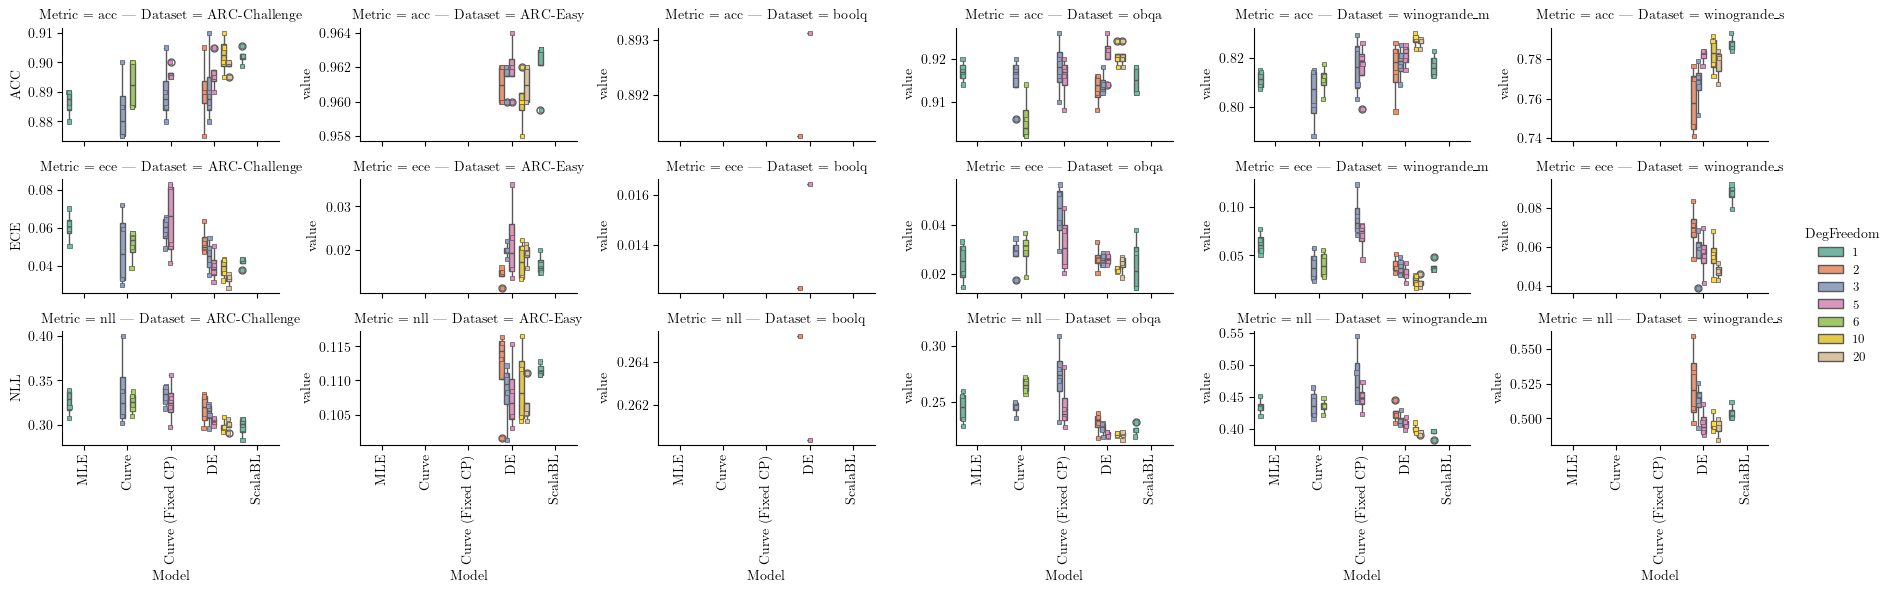

In [8]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])


g = sns.catplot(data=df_subset, x='Model', y='value', hue='DegFreedom', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Metric'] == row_name) & (df_subset['Dataset'] == col_name)],
            x='Model',
            y='value',
            hue='DegFreedom',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
# rotate x tick labels for all subplots
for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=90)
g.tight_layout()


/tmp/ipykernel_230235/2015359192.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)


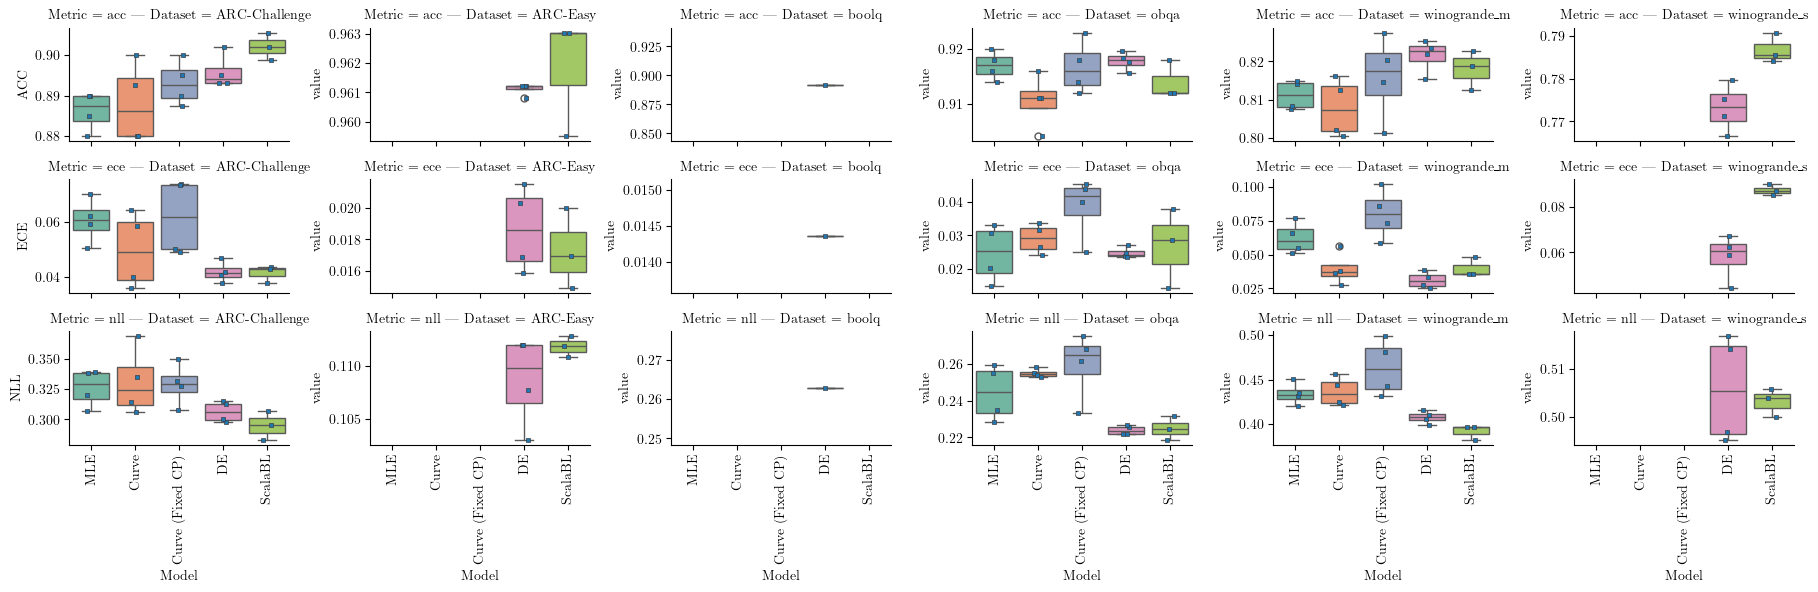

In [9]:
# Reference accuracy values from table 2
# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric'], observed=False).mean().reset_index()
# Sort by Model order (MLE, Curve, DE, ScalaBL) and DegFreedom
# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset2[(df_subset2['Metric'] == row_name) & (df_subset2['Dataset'] == col_name)],
            x='Model',
            y='value',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
# rotate x tick labels for all subplots
for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=90)
g.tight_layout()


### Rotation Tunnel 


In [47]:
api = wandb.Api()
results = []


for s in ["p3oa1rff",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "combined":
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        else:
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            LoraRhoS=run.config['lora_params'].get('lora_rho_s', -1),
            RhoFrequency=run.config['lora_params'].get('rho_scheduler_frequency', 0),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)

for s in ["ri3z6se0",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "combined":
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        else:
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            LoraRhoS=run.config['lora_params'].get('lora_rho_s', -1),
            RhoFrequency=run.config['lora_params'].get('rho_scheduler_frequency', 0),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)

 
df = pd.DataFrame(results)
df

p3oa1rff: 100%|██████████| 40/40 [00:00<00:00, 405.62it/s, ethereal-sweep-1]


Skipping fiery-sweep-40 because it is not finished
Skipping robust-sweep-36 because it is not finished
Skipping chocolate-sweep-34 because it is not finished
Skipping fragrant-sweep-28 because it is not finished
Skipping distinctive-sweep-26 because it is not finished
Skipping vital-sweep-24 because it is not finished
Skipping comfy-sweep-22 because it is not finished
Skipping crimson-sweep-16 because it is not finished
Skipping driven-sweep-14 because it is not finished
Skipping splendid-sweep-4 because it is not finished
Skipping gallant-sweep-2 because it is not finished


ri3z6se0: 100%|██████████| 20/20 [00:00<00:00, 443.50it/s, earnest-sweep-1]

Skipping fearless-sweep-17 because it is not finished
Skipping balmy-sweep-8 because it is not finished


,Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,LoraRhoS,RhoFrequency,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,pvr0jdaw,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.1,50,0.100034,0.506667,0.009754,0.693308,0.692592,0.000010,0.000040,0.692582
1,xol09ysp,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.0,50,0.880457,0.813333,0.086871,0.466392,0.269692,0.000280,0.000370,0.269411
2,glkxr7ap,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.0,50,0.125686,0.780833,0.081569,0.487947,0.341886,0.000309,0.000345,0.341577
3,g4s422py,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.1,50,49.260479,0.635000,0.119620,0.701023,0.509451,0.000466,0.001043,0.508985
4,tdv34afa,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.0,50,49.218987,0.632500,0.117509,0.700251,0.509565,0.000425,0.000989,0.509140
5,stt4unvi,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.1,50,316.902954,0.805833,0.079788,0.461428,0.293905,0.004090,0.011576,0.289816
6,mkma4ep5,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.1,50,61.262230,0.805833,0.094610,0.472695,0.269939,0.007463,0.017102,0.262476
7,hykj26nh,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.0,50,316.895874,0.811667,0.085765,0.479617,0.272215,0.005017,0.013796,0.267197
8,vxbz2gxd,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.0,50,61.294407,0.812500,0.090326,0.478146,0.294749,0.009337,0.026092,0.285411
9,q46y71xc,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.1,50,37.413639,0.811667,0.078967,0.472561,0.298423,0.006485,0.022296,0.291937


In [48]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,LoraRho,LoraRhoS,RhoFrequency,,,,,,,,


In [49]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [6 3]
CpFix ['[0, 0, 0, 0, 0, 0]' '[0, 0, 0]']
Jitter [0]
Seed [1]
WeightDecay [0.01]
Dataset ['winogrande_m']
Metric ['ppd']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['Arotsd(t)eB' 'Arot(t)sdeBrot(t)' 'Asd(t)eB' 'A(t)eB' 'A(t)eB(t)']
CurveMode ['bezier']
LoraRank [  8 224  64]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_noBMA']
LoraRho [0.5]
LoraRhoS [0.1 0. ]
RhoFrequency [50]

Experiment differs in ['CurveSpace', 'CpFix', 'LoraMode', 'LoraRank', 'LoraRhoS'] configs


array(['winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [55]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']

df_subset['Config'] = df_subset.apply(lambda row: f"LM={row['LoraMode']}, r={row['LoraRank']}, rho_s={row['LoraRhoS']}", axis=1)
df_subset['Config'] = df_subset.apply(lambda row: f"LM={row['LoraMode']}, r={row['LoraRank']}", axis=1)
# df_subset = df_subset[df_subset['Tsample'] == 'per_leaf']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]
df_subset.sort_values(by="Config", inplace=True)

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'LoraRank', 'LoraMode', 'CurveSpace', 'LoraRho', 'LoraRhoS'])[['acc', 'nll', 'ece']].mean()

acc  \
Dataset      LoraRank LoraMode          CurveSpace LoraRho LoraRhoS             
winogrande_m 8        A(t)eB            3          0.5     0.0       0.805000   
                                                           0.1       0.804167   
                                        6          0.5     0.0       0.816667   
                                                           0.1       0.811667   
                      A(t)eB(t)         3          0.5     0.0       0.802500   
                                                           0.1       0.811667   
                                        6          0.5     0.0       0.819167   
                                                           0.1       0.800000   
                      Arot(t)sdeBrot(t) 3          0.5     0.0       0.632500   
                                                           0.1       0.637500   
                                        6          0.5     0.0       0.632500   
                                                           0.1       0.635000   
                      Arotsd(t)eB       3          0.5     0.0       0.793333   
                                                           0.1       0.787500   
                                        6          0.5     0.0       0.780833   
                                                           0.1       0.506667   
                      Asd(t)eB          3          0.5     0.0       0.806667   
                                                           0.1       0.817500   
                                        6          0.5     0.0       0.812500   
                                                           0.1       0.805833   
             64       A(t)eB            3          0.5     0.0       0.801667   
                                                           0.1       0.813333   
                                        6          0.5     0.0       0.808333   
                                                           0.1       0.812500   
                      A(t)eB(t)         3          0.5     0.0       0.811667   
                                                           0.1       0.811667   
                                        6          0.5     0.0       0.813333   
                                                           0.1       0.805833   
                      Arot(t)sdeBrot(t) 3          0.5     0.0       0.631667   
                                        6          0.5     0.1       0.630000   
                      Arotsd(t)eB       3          0.5     0.0       0.788333   
                                                           0.1       0.828333   
                                        6          0.5     0.0       0.822500   
                                                           0.1       0.690833   
                      Asd(t)eB          3          0.5     0.0       0.814167   
                                                           0.1       0.817500   
                                        6          0.5     0.0       0.826667   
                                                           0.1       0.810833   
             224      A(t)eB            3          0.5     0.0       0.830833   
                                                           0.1       0.807500   
                      Arotsd(t)eB       3          0.5     0.0       0.828333   
                                                           0.1       0.828333   
                                        6          0.5     0.0       0.813333   
                      Asd(t)eB          3          0.5     0.0       0.817500   
                                                           0.1       0.806667   
                                        6          0.5     0.0       0.811667   
                                                           0.1       0.805833   

                                                                          nll  \
Dataset      LoraRank L

/tmp/ipykernel_230235/1025700726.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


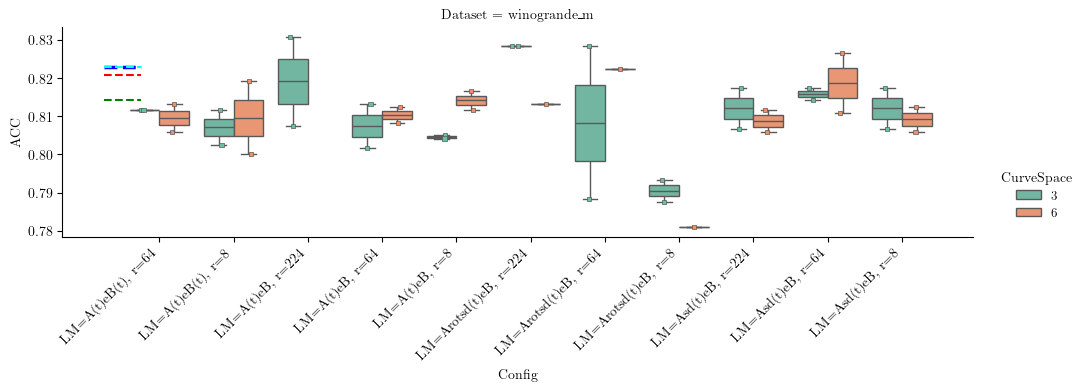

In [59]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

numeric_rhos = sorted(df_subset['CurveSpace'].unique())
df_subset['CurveSpace'] = df_subset['CurveSpace'].astype(str)
hue_order = [str(x) for x in numeric_rhos]

# Filter out bad runs with dataset-specific thresholds
min_acc = {
    'ARC-Easy': 0.85,
    'obqa': 0.83,
    'ARC-Challenge': 0.85,
    'boolq': 0.65,
    'winogrande_m': 0.7,
    'winogrande_s': 0.55
}
df_subset = df_subset[df_subset['acc'] > df_subset['Dataset'].map(min_acc).fillna(0)]

# # df_subset = df_subset[df_subset['Config']==0]
# hue_order = list(df_subset['CurveSpace'].unique())
# hue_order.sort()
# # hue_order = None
# # hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='Config', y='acc', hue='CurveSpace', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1]*2, row_order=col_order, hue_order=hue_order, aspect=2.5)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        # entropy_scale = ax.get_title().split('=')[2].strip()
        # print(ds, entropy_scale)
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
            data=df_subset[(df_subset['Dataset'] == ds)],
            x='Config',
            y='acc',
            hue='CurveSpace',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    # print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    # print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
# g.set_xticklabels(rotation=90, ha='center')
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_230235/2807819643.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


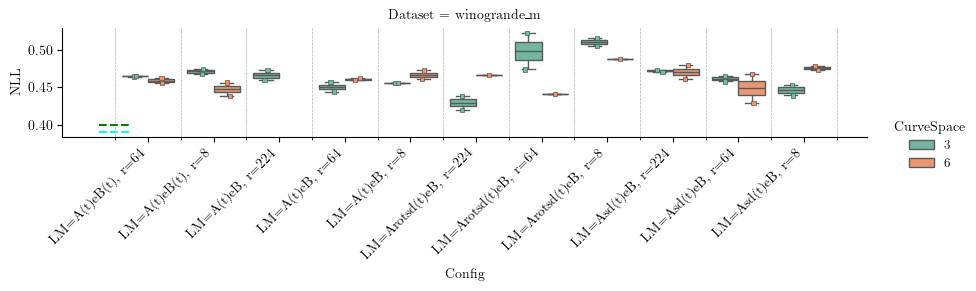

In [ ]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='Config', y='nll', hue='CurveSpace', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1]*1.5, row_order=col_order, hue_order=hue_order, aspect=3,)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    # entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        data=df_subset[(df_subset['Dataset'] == ds)],
        x='Config',
        y='nll',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()
# make grid (only lines for y-axis) but at +- 0.5pt
major_ticks = ax.get_xticks()
minor_ticks = np.arange(start=min(major_ticks) - 0.5, 
                        stop=max(major_ticks) + 1.5, 
                        step=1)
# Set these positions as minor ticks
ax.set_xticks(minor_ticks, minor=True)
for ax in g.axes.flat:
    ax.grid(True, axis='x', which='minor', linestyle='--', linewidth=0.5,)

/tmp/ipykernel_230235/4087892978.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


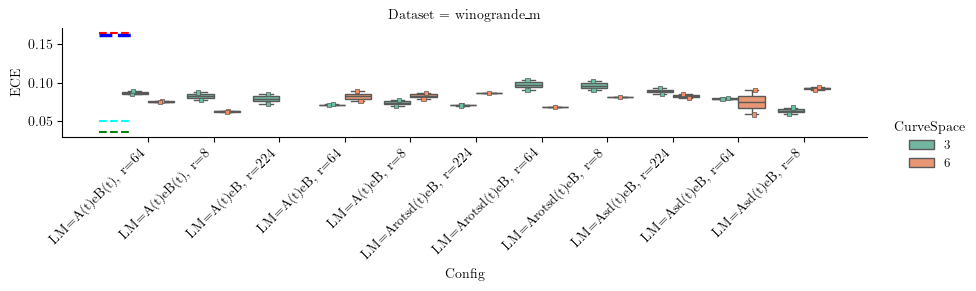

In [62]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='Config', y='ece', hue='CurveSpace', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1]*1.5, row_order=col_order, hue_order=hue_order, aspect=3)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    # entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        data=df_subset[(df_subset['Dataset'] == ds)],
        x='Config',
        y='ece',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed

for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_230235/2367440844.py:7: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)


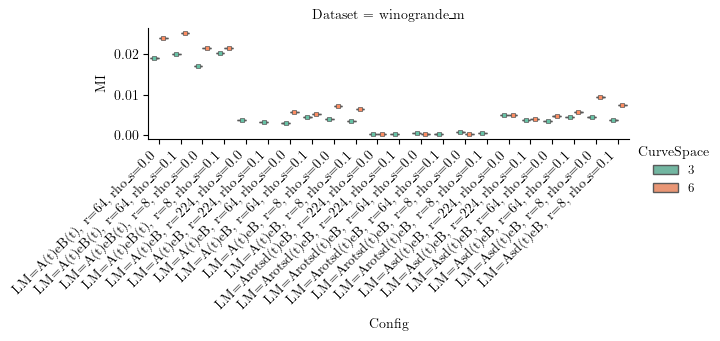

In [54]:

g = sns.catplot(data=df_subset, x='Config', y='test_mutual_information_ppd', hue='CurveSpace', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=3)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    # entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        data=df_subset[(df_subset['Dataset'] == ds)],
        x='Config',
        y='test_mutual_information_ppd',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('MI')

# Adjust legend placement if needed

for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

### FixedPoints compare with VI vs DE vs MLE vs Curve


In [45]:
api = wandb.Api()
results = []
for s in ["uasav1sa",]: # think DE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="DE",
            DegFreedom=run.config['curve_params']['k'], #+ 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode="minibatch",
            DS_WindowSize=-1,
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_de_acc", 0),
            ece=run.summary.get(f"test_de_ece", 0),
            nll=-run.summary.get(f"test_de_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

df = pd.DataFrame(results)
df

uasav1sa:   0%|          | 0/120 [00:00<?, ?it/s, deep-sweep-113]     

uasav1sa:  51%|█████     | 61/120 [00:00<00:00, 276.69it/s, dry-sweep-110]     

Skipping grateful-sweep-108 because it is not finished
Skipping volcanic-sweep-89 because it is not finished
Skipping fancy-sweep-73 because it is not finished
Skipping breezy-sweep-108 because it is not finished
Skipping stoic-sweep-107 because it is not finished
Skipping bumbling-sweep-106 because it is not finished


uasav1sa: 100%|██████████| 120/120 [00:00<00:00, 288.58it/s, efficient-sweep-1]

Skipping denim-sweep-105 because it is not finished
Skipping sweet-sweep-84 because it is not finished
Skipping dashing-sweep-83 because it is not finished
Skipping eager-sweep-81 because it is not finished
Skipping worldly-sweep-63 because it is not finished
Skipping true-sweep-62 because it is not finished
Skipping iconic-sweep-46 because it is not finished
Skipping eternal-sweep-45 because it is not finished
Skipping golden-sweep-44 because it is not finished
Skipping olive-sweep-43 because it is not finished
Skipping sparkling-sweep-40 because it is not finished
Skipping easy-sweep-51 because it is not finished
Skipping stellar-sweep-52 because it is not finished


,Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,RegularizationMode,Gravity,EnergyWeakening,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,lxb197kc,DE,20,0,8000,0.01,ARC-Easy,ppd,None,minibatch,...,False,0,1,0.962000,0.021363,0.104103,-inf,-inf,-inf,-inf
1,g6drnsqp,DE,20,0,400,0.01,ARC-Easy,ppd,None,minibatch,...,False,0,1,0.962000,0.019312,0.111040,-inf,-inf,-inf,-inf
2,efvq3bwq,DE,20,0,20,0.01,ARC-Easy,ppd,None,minibatch,...,False,0,1,0.960000,0.020621,0.105149,-inf,-inf,-inf,-inf
3,fxscuc4p,DE,20,0,1,0.01,ARC-Easy,ppd,None,minibatch,...,False,0,1,0.960000,0.015957,0.105185,-inf,-inf,-inf,-inf
4,031ok7yz,DE,20,0,8000,0.01,ARC-Challenge,ppd,None,minibatch,...,False,0,1,0.900000,0.032972,0.300295,-inf,-inf,-inf,-inf
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,g9jerjne,DE,2,0,400,0.01,winogrande_s,ppd,None,minibatch,...,False,0,1,0.740833,0.083515,0.559315,-inf,-inf,-inf,-inf
97,5guj82ch,DE,2,0,20,0.01,winogrande_s,ppd,None,minibatch,...,False,0,1,0.770000,0.071033,0.507625,-inf,-inf,-inf,-inf
98,a15h3l3z,DE,2,0,1,0.01,winogrande_s,ppd,None,minibatch,...,False,0,1,0.776667,0.053730,0.496819,-inf,-inf,-inf,-inf
99,d1gf86ac,DE,2,0,20,0.01,winogrande_m,ppd,None,minibatch,...,False,0,1,0.798333,0.051673,0.445338,-inf,-inf,-inf,-inf


### Flat Lora A(t)B(t) Modeconnect  


In [74]:
api = wandb.Api()
results = []


for s in ["3p3okc1w",]: # winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "combined":
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        else:
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            LoraRhoS=run.config['lora_params'].get('lora_rho_s', -1),
            RhoFrequency=run.config['lora_params'].get('rho_scheduler_frequency', 0),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)
 
df = pd.DataFrame(results)
df

3p3okc1w: 100%|██████████| 16/16 [00:00<00:00, 361.35it/s, worldly-sweep-1]

Skipping daily-sweep-16 because it is not finished
Skipping chocolate-sweep-15 because it is not finished
Skipping dazzling-sweep-14 because it is not finished


,Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,LoraRhoS,RhoFrequency,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,m251fvgi,7,"[1, 0, 1, 0, 1, 0, 1]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.1,50,46.233025,0.801667,0.084060,0.472108,0.311410,0.034782,0.043054,0.276628
1,be9mrvkp,7,"[1, 0, 1, 0, 1, 0, 1]",0,20,0.01,winogrande_m,ppd,minibatch,classic,...,0.0,50,129.869064,0.820833,0.089688,0.446738,0.310425,0.031275,0.038450,0.279149
2,tc5fxib5,7,"[1, 0, 1, 0, 1, 0, 1]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.0,50,131.174774,0.820000,0.074024,0.448737,0.308380,0.030322,0.029330,0.278057
3,gripbbuj,7,"[1, 0, 1, 0, 1, 0, 1]",0,20,0.01,winogrande_m,ppd,minibatch,classic,...,0.0,50,45.903984,0.805000,0.082537,0.456767,0.312274,0.030812,0.030850,0.281462
4,d2xtr7rd,7,"[1, 0, 1, 0, 1, 0, 1]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.0,50,46.013008,0.810833,0.073615,0.458389,0.324751,0.029651,0.033985,0.295100
5,h3lgunn6,5,"[1, 0, 1, 0, 1]",0,20,0.01,winogrande_m,ppd,minibatch,classic,...,0.1,50,111.289719,0.815000,0.097134,0.482756,0.280184,0.026437,0.020455,0.253747
6,zk5c46ks,5,"[1, 0, 1, 0, 1]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.1,50,110.257385,0.816667,0.090793,0.478757,0.271104,0.036931,0.026123,0.234173
7,0y97m7tv,5,"[1, 0, 1, 0, 1]",0,20,0.01,winogrande_m,ppd,minibatch,classic,...,0.1,50,39.138084,0.819167,0.079473,0.460701,0.296508,0.025233,0.025752,0.271274
8,q5inpwsy,5,"[1, 0, 1, 0, 1]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.1,50,39.467773,0.812500,0.091197,0.471536,0.272868,0.033904,0.014774,0.238964
9,6imifu2y,5,"[1, 0, 1, 0, 1]",0,20,0.01,winogrande_m,ppd,minibatch,classic,...,0.0,50,110.287224,0.812500,0.069547,0.439038,0.331045,0.031644,0.045551,0.299401


In [75]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,LoraRho,LoraRhoS,RhoFrequency,,,,,,,,


In [76]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [7 5]
CpFix ['[1, 0, 1, 0, 1, 0, 1]' '[1, 0, 1, 0, 1]']
Jitter [0]
Seed [ 1 20]
WeightDecay [0.01]
Dataset ['winogrande_m']
Metric ['ppd']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['A(t)eB(t)']
CurveMode ['b-spline']
LoraRank [ 8 64]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_noBMA']
LoraRho [0.5]
LoraRhoS [0.1 0. ]
RhoFrequency [50]

Experiment differs in ['CurveSpace', 'CpFix', 'LoraRank', 'LoraRhoS'] configs


array(['winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [90]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']

df_subset['Config'] = df_subset.apply(lambda row: f"LM={row['LoraMode']}, r={row['LoraRank']}, rho_s={row['LoraRhoS']}", axis=1)
# df_subset['Config'] = df_subset.apply(lambda row: f"LM={row['LoraMode']}, r={row['LoraRank']}", axis=1)
# df_subset = df_subset[df_subset['Tsample'] == 'per_leaf']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]
df_subset.sort_values(by="Config", inplace=True)

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'LoraRank', 'LoraMode', 'CurveSpace', 'LoraRho', 'LoraRhoS'])[['acc', 'nll', 'ece']].mean()

acc  \
Dataset      LoraRank LoraMode  CurveSpace LoraRho LoraRhoS             
winogrande_m 8        A(t)eB(t) 5          0.5     0.0       0.819167   
                                                   0.1       0.815833   
                                7          0.5     0.0       0.807917   
                                                   0.1       0.801667   
             64       A(t)eB(t) 5          0.5     0.0       0.817083   
                                                   0.1       0.815833   
                                7          0.5     0.0       0.820417   

                                                                  nll  \
Dataset      LoraRank LoraMode  CurveSpace LoraRho LoraRhoS             
winogrande_m 8        A(t)eB(t) 5          0.5     0.0       0.457298   
                                                   0.1       0.466118   
                                7          0.5     0.0       0.457578   
                                                   0.1       0.472108   
             64       A(t)eB(t) 5          0.5     0.0       0.458062   
                                                   0.1       0.480756   
                                7          0.5     0.0       0.447738   

                                                                  ece  
Dataset      LoraRank LoraMode  CurveSpace LoraRho LoraRhoS            
winogrande_m 8        A(t)eB(t) 5          0.5     0.0       0.082220  
                                                   0.1       0.085335  
                                7          0.5     0.0       0.078076  
                                                   0.1       0.084060  
             64       A(t)eB(t) 5          0.5     0.0       0.083813  
                                                   0.1       0.093963  
                                7          0.5     0.0       0.081856

/tmp/ipykernel_230235/2540057516.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


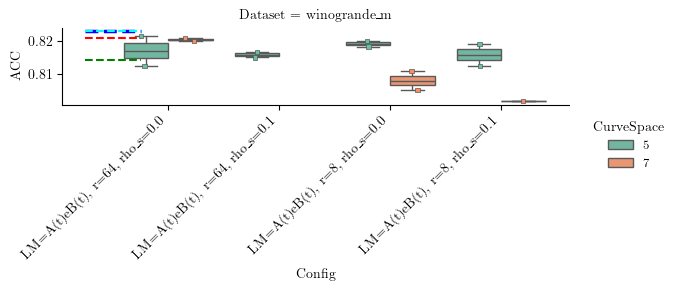

In [91]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

numeric_rhos = sorted(df_subset['CurveSpace'].unique())
df_subset['CurveSpace'] = df_subset['CurveSpace'].astype(str)
hue_order = [str(x) for x in numeric_rhos]

# # Filter out bad runs with dataset-specific thresholds
# min_acc = {
#     'ARC-Easy': 0.85,
#     'obqa': 0.83,
#     'ARC-Challenge': 0.85,
#     'boolq': 0.65,
#     'winogrande_m': 0.7,
#     'winogrande_s': 0.55
# }
# df_subset = df_subset[df_subset['acc'] > df_subset['Dataset'].map(min_acc).fillna(0)]

# # df_subset = df_subset[df_subset['Config']==0]
# hue_order = list(df_subset['CurveSpace'].unique())
# hue_order.sort()
# # hue_order = None
# # hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='Config', y='acc', hue='CurveSpace', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1]*1.5, row_order=col_order, hue_order=hue_order, aspect=2)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        # entropy_scale = ax.get_title().split('=')[2].strip()
        # print(ds, entropy_scale)
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
            data=df_subset[(df_subset['Dataset'] == ds)],
            x='Config',
            y='acc',
            hue='CurveSpace',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    # print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    # print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
# g.set_xticklabels(rotation=90, ha='center')
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_230235/3085832084.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


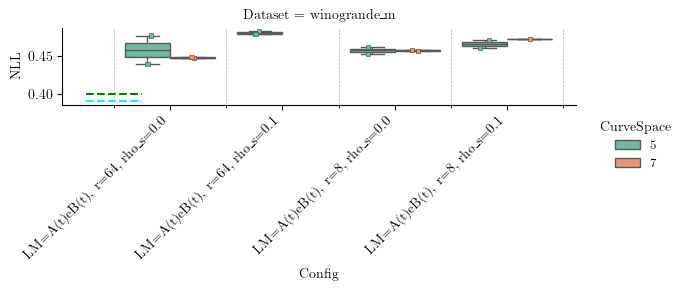

In [92]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='Config', y='nll', hue='CurveSpace', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1]*1.5, row_order=col_order, hue_order=hue_order, aspect=2,)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    # entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        data=df_subset[(df_subset['Dataset'] == ds)],
        x='Config',
        y='nll',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()
# make grid (only lines for y-axis) but at +- 0.5pt
major_ticks = ax.get_xticks()
minor_ticks = np.arange(start=min(major_ticks) - 0.5, 
                        stop=max(major_ticks) + 1.5, 
                        step=1)
# Set these positions as minor ticks
ax.set_xticks(minor_ticks, minor=True)
for ax in g.axes.flat:
    ax.grid(True, axis='x', which='minor', linestyle='--', linewidth=0.5,)

/tmp/ipykernel_230235/2679788837.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


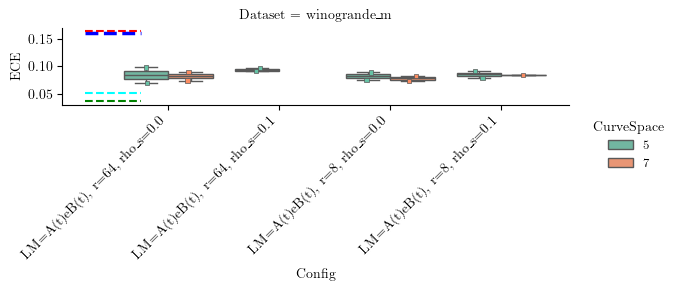

In [93]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='Config', y='ece', hue='CurveSpace', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1]*1.5, row_order=col_order, hue_order=hue_order, aspect=2)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    # entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        data=df_subset[(df_subset['Dataset'] == ds)],
        x='Config',
        y='ece',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed

for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_230235/2488060115.py:7: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


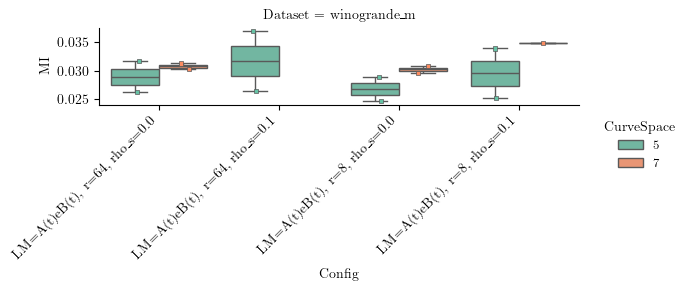

In [94]:

g = sns.catplot(data=df_subset, x='Config', y='test_mutual_information_ppd', hue='CurveSpace', kind='box', row='Dataset', sharey='row', palette='Set2', height=figsize[1]*1.5, row_order=col_order, hue_order=hue_order, aspect=2)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    # entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        data=df_subset[(df_subset['Dataset'] == ds)],
        x='Config',
        y='test_mutual_information_ppd',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('MI')

# Adjust legend placement if needed

for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

### ModeConnect vs DE

We run Modeconnected exp with A(t)B(t) and [1,0,1,0,1] or + 0,1] fixed control points. 
Then the pretrained models are used as DE members and compared against curve training with these fixed control points

In [5]:
import wandb
from tqdm import tqdm

api = wandb.Api()
results = []


for s in ["3p3okc1w",]: # winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "combined":
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        else:
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            LoraRhoS=run.config['lora_params'].get('lora_rho_s', -1),
            RhoFrequency=run.config['lora_params'].get('rho_scheduler_frequency', 0),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            de_acc=run.summary.get(f"de_post_pred_acc", 0),
            de_ece=run.summary.get(f"de_post_pred_ece", 0),
            de_nll=-run.summary.get(f"de_post_pred_ll", 0)
            )
        results.append(res)
 
df = pd.DataFrame(results)
df

3p3okc1w: 100%|██████████| 16/16 [00:00<00:00, 708.71it/s, worldly-sweep-1]

,Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve,de_acc,de_ece,de_nll
0,p4t12n0z,7,"[1, 0, 1, 0, 1, 0, 1]",0,20,0.01,winogrande_m,ppd,minibatch,classic,...,0.816667,0.079189,0.446529,0.314338,0.028304,0.023261,0.286034,0.824167,0.054315,0.419836
1,tqu11ijt,7,"[1, 0, 1, 0, 1, 0, 1]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.813333,0.078330,0.458006,0.309101,0.031110,0.040482,0.277991,0.810833,0.082101,0.434022
2,uz26th39,7,"[1, 0, 1, 0, 1, 0, 1]",0,20,0.01,winogrande_m,ppd,minibatch,classic,...,0.813333,0.077313,0.447352,0.326206,0.028875,0.030855,0.297331,0.815000,0.051941,0.416126
3,m251fvgi,7,"[1, 0, 1, 0, 1, 0, 1]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.801667,0.084060,0.472108,0.311410,0.034782,0.043054,0.276628,0.822500,0.075485,0.427678
4,be9mrvkp,7,"[1, 0, 1, 0, 1, 0, 1]",0,20,0.01,winogrande_m,ppd,minibatch,classic,...,0.820833,0.089688,0.446738,0.310425,0.031275,0.038450,0.279149,0.822500,0.060210,0.412711
5,tc5fxib5,7,"[1, 0, 1, 0, 1, 0, 1]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.820000,0.074024,0.448737,0.308380,0.030322,0.029330,0.278057,0.821667,0.059170,0.411182
6,gripbbuj,7,"[1, 0, 1, 0, 1, 0, 1]",0,20,0.01,winogrande_m,ppd,minibatch,classic,...,0.805000,0.082537,0.456767,0.312274,0.030812,0.030850,0.281462,0.816667,0.060711,0.422830
7,d2xtr7rd,7,"[1, 0, 1, 0, 1, 0, 1]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.810833,0.073615,0.458389,0.324751,0.029651,0.033985,0.295100,0.823333,0.057842,0.420375
8,h3lgunn6,5,"[1, 0, 1, 0, 1]",0,20,0.01,winogrande_m,ppd,minibatch,classic,...,0.815000,0.097134,0.482756,0.280184,0.026437,0.020455,0.253747,0.828333,0.062092,0.420101
9,zk5c46ks,5,"[1, 0, 1, 0, 1]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,0.816667,0.090793,0.478757,0.271104,0.036931,0.026123,0.234173,0.811667,0.084622,0.447611


In [6]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [7 5]
CpFix ['[1, 0, 1, 0, 1, 0, 1]' '[1, 0, 1, 0, 1]']
Jitter [0]
Seed [20  1]
WeightDecay [0.01]
Dataset ['winogrande_m']
Metric ['ppd']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['A(t)eB(t)']
CurveMode ['b-spline']
LoraRank [64  8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_noBMA']
LoraRho [0.5]
LoraRhoS [0.1 0. ]
RhoFrequency [50]

Experiment differs in ['CurveSpace', 'CpFix', 'LoraRank', 'LoraRhoS'] configs


array(['winogrande_m'], dtype=object)

Original label: 0.0
Original label: 0.1
Original label: 0.0
Original label: 0.1


/tmp/ipykernel_275921/3275602703.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


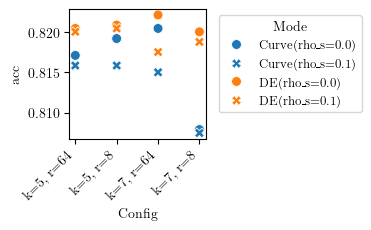

In [16]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']

df_subset = df_subset.groupby(['Dataset', 'CurveSpace', 'LoraRank', 'LoraRhoS'])[['acc', 'de_acc', 'nll', 'de_nll', 'ece', 'de_ece']].mean().reset_index()

df_subset['Config'] = df_subset.apply(lambda row: f"k={row['CurveSpace']}, r={row['LoraRank']}, rho_s={row['LoraRhoS']}", axis=1)
df_subset['Config'] = df_subset.apply(lambda row: f"k={row['CurveSpace']}, r={row['LoraRank']}", axis=1)
df_subset.sort_values(by="Config", inplace=True)

col_order = df_subset['Dataset'].unique()
col_order.sort()

ax = plt.figure(figsize=np.array(figsize)*1.2).gca()
ax = sns.scatterplot(data=df_subset, x='Config', y='acc', style='LoraRhoS', s=50, ax=ax, )
ax = sns.scatterplot(data=df_subset, x='Config', y='de_acc', style='LoraRhoS', s=50, ax=ax, )
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

# add title to legend (First plot is ppd and second is de)
handles, labels = ax.get_legend_handles_labels()
new_labels = []
for i, label in enumerate(labels):
    print(f"Original label: {label}")
    if i < len(labels) // 2:
        new_labels.append(f"Curve(rho_s={label})")
    else:
        new_labels.append(f"DE(rho_s={label})")
ax.legend(handles, new_labels, title='Mode', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

Original label: 0.0
Original label: 0.1
Original label: 0.0
Original label: 0.1


/tmp/ipykernel_275921/2315349640.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


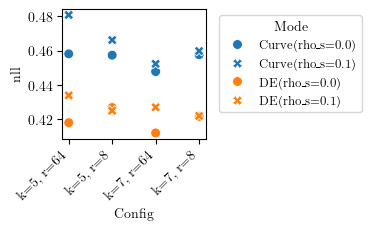

In [17]:
ax = plt.figure(figsize=np.array(figsize)*1.2).gca()
ax = sns.scatterplot(data=df_subset, x='Config', y='nll', style='LoraRhoS', s=50, ax=ax, )
ax = sns.scatterplot(data=df_subset, x='Config', y='de_nll', style='LoraRhoS', s=50, ax=ax, )
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

# add title to legend (First plot is ppd and second is de)
handles, labels = ax.get_legend_handles_labels()
new_labels = []
for i, label in enumerate(labels):
    print(f"Original label: {label}")
    if i < len(labels) // 2:
        new_labels.append(f"Curve(rho_s={label})")
    else:
        new_labels.append(f"DE(rho_s={label})")
ax.legend(handles, new_labels, title='Mode', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

## new config 

### Bezier Segments with independent pretraining

We run Modeconnected exp with A(t)B(t) and [1,0,0,1,0, 0,1] fixed control points. 
Then the pretrained models are used as DE members and compared against curve training with these fixed control points

In [3]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in ["qd3vby8c", "zyk44mta", "6uh01z19"]: # winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_seg/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            CurveSpace=len(mp['cp_fix']),
            CpFix=str(mp['cp_fix']),
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegment=mp.get('curve_segment', len(mp['cp_fix'])),
            OpenEndSegment=mp.get('independent_connected', False),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        # add DE   
        _res = deepcopy(res)
        _res['BmaMode'] = "DE"
        _res['acc'] = run.summary.get(f"DE_acc", -np.inf)
        _res['ece'] = run.summary.get(f"DE_ece", -np.inf)
        _res['ll'] = run.summary.get(f"DE_ll", -np.inf)
        results.append(_res)
        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)

        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)
 
df = pd.DataFrame(results)
df.describe().T

6uh01z19: 100%|██████████| 40/40 [00:00<00:00, 155.90it/s, northern-sweep-1] 


,count,mean,std,min,25%,50%,75%,max
CurveSpace,480.0,7.000000,3.745561e+00,3.000000,4.500000,6.000000,8.500000,13.000000
Jitter,480.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
Seed,480.0,2105.250000,3.410609e+03,1.000000,15.250000,210.000000,2300.000000,8000.000000
WeightDecay,480.0,0.001000,4.341333e-19,0.001000,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,480.0,-1.000000,0.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,480.0,-1.000000,0.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,480.0,10000.000000,0.000000e+00,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,480.0,8.000000,0.000000e+00,8.000000,8.000000,8.000000,8.000000,8.000000
Gravity,480.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
EnergyWeakening,480.0,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000


In [4]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [13  7  5  3]
CpFix ['[1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]' '[1, 0, 0, 1, 0, 0, 1]'
 '[1, 0, 1, 0, 1]' '[1, 1, 1]']
Jitter [0]
Seed [8000  400   20    1]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'winogrande_s' 'obqa' 'winogrande_m']
BmaMode ['PPD' 'DE' 'PPD Uniform']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.5  0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegment [3 2 1]
OpenEndSegment [False]

Experiment differs in ['CurveSpace', 'CpFix', 'Dataset', 'BmaMode', 'LoraRho', 'CurveSegment'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [5]:
# Build Config label
df_subset = df_clean.copy()

# df_subset = df_subset.sort_values(by='Config')

# Melt all lowercase-named columns → long form with Metric column
# lower_cols = [c for c in df_subset.columns if c[0].islower()]
# id_cols = [c for c in df_subset.columns if c not in lower_cols]
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: f"k={r['CurveSpace']}, rho={r['LoraRho']}", axis=1)

col_order = df_subset['Dataset'].unique()
col_order.sort()


/tmp/ipykernel_3628080/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale c

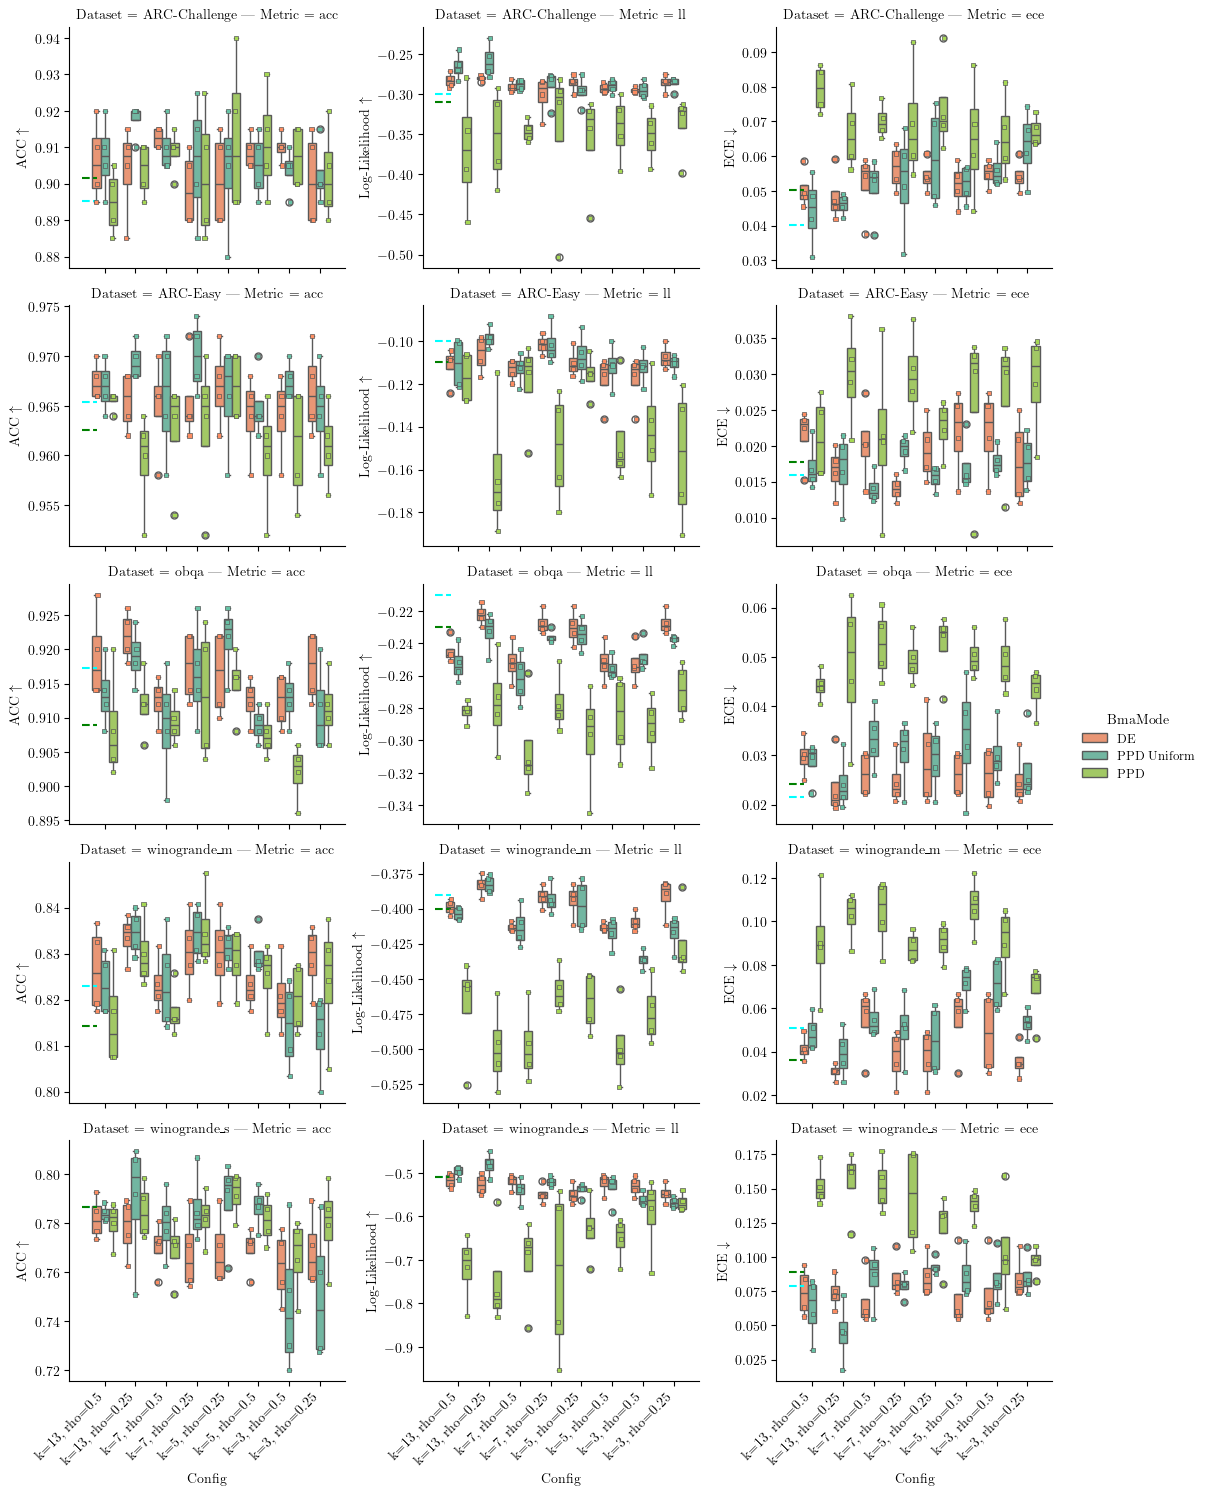

In [6]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':  {'MLE': 78.86, 'MAP': 78.94, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':      {'MLE': 95.60, 'MAP': 95.73, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':  {'MLE': 82.30, 'MAP': 82.09, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':          {'MLE': 92.25, 'MAP': 91.72, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':         {'MLE': 89.06, 'MAP': 89.04, 'BLoB': 89.05, 'ScalaBL': 88.48},
}
# Reference NLL values (our ll = -nll, so ref_ll = -ref_nll)
ref_nll = {
    'boolq':         {'MLE': 0.25, 'MAP': 0.25, 'BLoB': 0.23, 'ScalaBL': 0.24},
    'ARC-Easy':      {'MLE': 0.44, 'MAP': 0.43, 'BLoB': 0.10, 'ScalaBL': 0.11},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.05, 'BLoB': 0.30, 'ScalaBL': 0.31},
    'obqa':          {'MLE': 0.38, 'MAP': 0.39, 'BLoB': 0.21, 'ScalaBL': 0.23},
    'winogrande_s':  {'MLE': 1.94, 'MAP': 1.88, 'BLoB': 0.51, 'ScalaBL': 0.51},
    'winogrande_m':  {'MLE': 1.20, 'MAP': 1.27, 'BLoB': 0.39, 'ScalaBL': 0.40},
}
# Reference ECE values (in %, divide by 100)
ref_ece = {
    'winogrande_s':  {'MLE': 20.14, 'MAP': 19.99, 'BLoB': 7.88,  'ScalaBL': 8.88},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54, 'BLoB': 4.03,  'ScalaBL': 5.03},
    'ARC-Easy':      {'MLE': 4.17,  'MAP': 4.08,  'BLoB': 1.60,  'ScalaBL': 1.78},
    'winogrande_m':  {'MLE': 16.10, 'MAP': 16.42, 'BLoB': 5.08,  'ScalaBL': 3.64},
    'obqa':          {'MLE': 6.40,  'MAP': 6.61,  'BLoB': 2.16,  'ScalaBL': 2.43},
    'boolq':         {'MLE': 3.79,  'MAP': 3.81,  'BLoB': 1.40,  'ScalaBL': 1.96},
}

# Melt to long form: acc, ll, ece → Metric + value
# id_cols = [c for c in df_subset.columns if c not in ('acc', 'll', 'ece')]
# df_plot = df_subset.melt(id_vars=id_cols, value_vars=['acc', 'll', 'ece'], var_name='Metric', value_name='value')

# hue_order = df_plot['BmaMode'].unique()
hue_order = ['DE', 'PPD Uniform', 'PPD']
# Single color for all hue levels
cmap = sns.color_palette("Set2")
hue_palette = {'DE': cmap[1], 'PPD Uniform': cmap[0], 'PPD': cmap[4]}

metric_order = ['acc', 'll', 'ece']

g = sns.catplot(
    data=df_plot, x='Config', y='value', hue='BmaMode', kind='box',
    row='Dataset', col='Metric', palette=hue_palette, sharey=False,
    height=figsize[1] * 1.5, row_order=col_order, col_order=metric_order,
    hue_order=hue_order, aspect=1.2
)

# Overlay strip plots
for (ds, metric), ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[(df_plot['Dataset'] == ds) & (df_plot['Metric'] == metric)],
        x='Config', y='value', hue='BmaMode',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='gray', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )

# Set y-axis labels per metric column
ylabel_map = {'acc': r'ACC $\uparrow$', 'll': r'Log-Likelihood $\uparrow$', 'ece': r'ECE $\downarrow$'}
for col_idx, metric in enumerate(metric_order):
    for ax in g.axes[:, col_idx]:
        ax.set_ylabel(ylabel_map[metric])

# Draw reference lines for all three metrics
ref_map = {
    'acc': (ref_acc, lambda v: v / 100),
    'll':  (ref_nll, lambda v: -v),       # ll = -nll
    'ece': (ref_ece, lambda v: v / 100),
}
for col_idx, metric in enumerate(metric_order):
    ref_dict, transform = ref_map[metric]
    for row_idx, ds in enumerate(col_order):
        if ds not in ref_dict:
            continue
        ax = g.axes[row_idx, col_idx]
        tick = -0.5
        # ax.hlines(y=transform(ref_dict[ds]['MLE']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='blue',  linestyles='--', lw=2.5, label='MLE')
        ax.hlines(y=transform(ref_dict[ds]['BLoB']),    xmin=tick-0.25, xmax=tick+0.25,
                  colors='cyan',  linestyles='--', lw=1.5, label='BLoB')
        ax.hlines(y=transform(ref_dict[ds]['ScalaBL']), xmin=tick-0.25, xmax=tick+0.25,
                  colors='green', linestyles='--', lw=1.5, label='ScalaBL')
        # ax.hlines(y=transform(ref_dict[ds]['MAP']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='red',   linestyles='--', lw=1.5, label='MAP')

# Rotate x-tick labels on last row
for ax in g.axes[-1, :].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

g.tight_layout()


/tmp/ipykernel_3628080/742950105.py:51: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/742950105.py:51: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/742950105.py:51: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/742950105.py:51: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/742950105.py:51: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/742950105.py:51: FutureWarning: Use "auto" to set automatic grayscale colors.

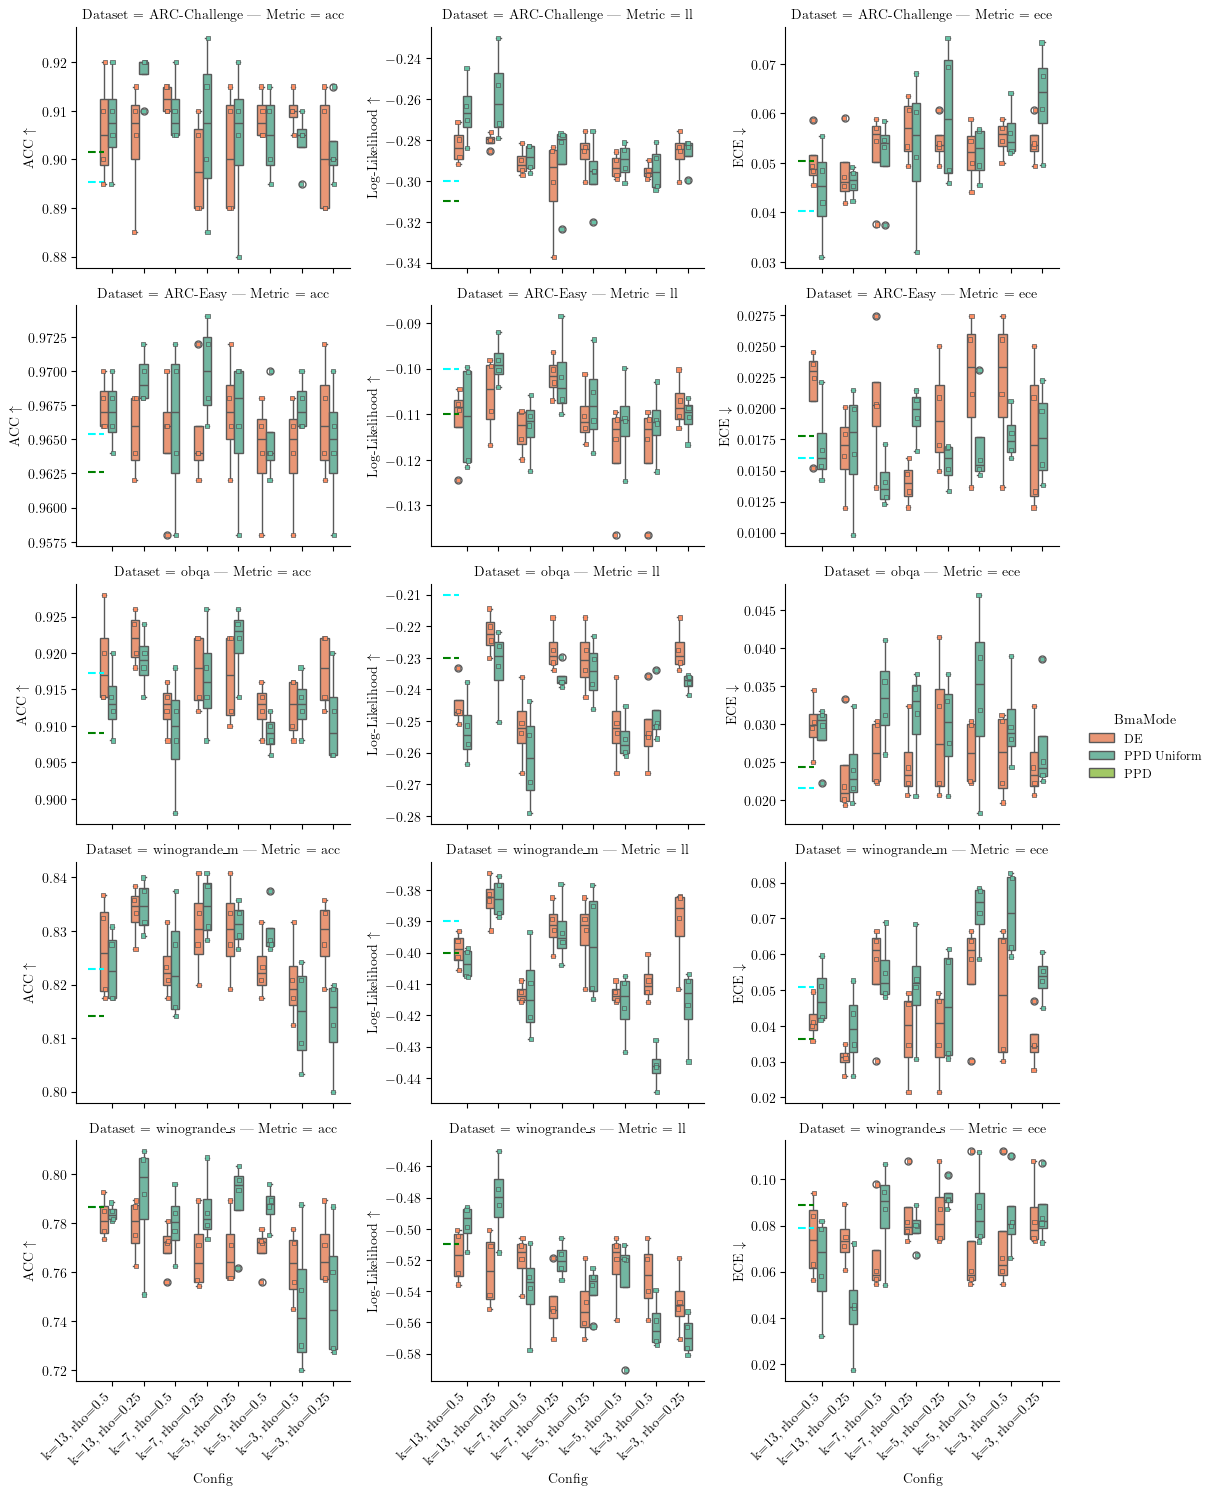

In [7]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':  {'MLE': 78.86, 'MAP': 78.94, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':      {'MLE': 95.60, 'MAP': 95.73, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':  {'MLE': 82.30, 'MAP': 82.09, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':          {'MLE': 92.25, 'MAP': 91.72, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':         {'MLE': 89.06, 'MAP': 89.04, 'BLoB': 89.05, 'ScalaBL': 88.48},
}
# Reference NLL values (our ll = -nll, so ref_ll = -ref_nll)
ref_nll = {
    'boolq':         {'MLE': 0.25, 'MAP': 0.25, 'BLoB': 0.23, 'ScalaBL': 0.24},
    'ARC-Easy':      {'MLE': 0.44, 'MAP': 0.43, 'BLoB': 0.10, 'ScalaBL': 0.11},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.05, 'BLoB': 0.30, 'ScalaBL': 0.31},
    'obqa':          {'MLE': 0.38, 'MAP': 0.39, 'BLoB': 0.21, 'ScalaBL': 0.23},
    'winogrande_s':  {'MLE': 1.94, 'MAP': 1.88, 'BLoB': 0.51, 'ScalaBL': 0.51},
    'winogrande_m':  {'MLE': 1.20, 'MAP': 1.27, 'BLoB': 0.39, 'ScalaBL': 0.40},
}
# Reference ECE values (in %, divide by 100)
ref_ece = {
    'winogrande_s':  {'MLE': 20.14, 'MAP': 19.99, 'BLoB': 7.88,  'ScalaBL': 8.88},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54, 'BLoB': 4.03,  'ScalaBL': 5.03},
    'ARC-Easy':      {'MLE': 4.17,  'MAP': 4.08,  'BLoB': 1.60,  'ScalaBL': 1.78},
    'winogrande_m':  {'MLE': 16.10, 'MAP': 16.42, 'BLoB': 5.08,  'ScalaBL': 3.64},
    'obqa':          {'MLE': 6.40,  'MAP': 6.61,  'BLoB': 2.16,  'ScalaBL': 2.43},
    'boolq':         {'MLE': 3.79,  'MAP': 3.81,  'BLoB': 1.40,  'ScalaBL': 1.96},
}

# Melt to long form: acc, ll, ece → Metric + value
# id_cols = [c for c in df_subset.columns if c not in ('acc', 'll', 'ece')]
# df_plot = df_subset.melt(id_vars=id_cols, value_vars=['acc', 'll', 'ece'], var_name='Metric', value_name='value')
df_plot = df_plot[df_plot['BmaMode'] != 'PPD']

# hue_order = df_plot['BmaMode'].unique()
hue_order = ['DE', 'PPD Uniform', 'PPD']
# Single color for all hue levels
cmap = sns.color_palette("Set2")
hue_palette = {'DE': cmap[1], 'PPD Uniform': cmap[0], 'PPD': cmap[4]}

metric_order = ['acc', 'll', 'ece']

g = sns.catplot(
    data=df_plot, x='Config', y='value', hue='BmaMode', kind='box',
    row='Dataset', col='Metric', palette=hue_palette, sharey=False,
    height=figsize[1] * 1.5, row_order=col_order, col_order=metric_order,
    hue_order=hue_order, aspect=1.2
)

# Overlay strip plots
for (ds, metric), ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[(df_plot['Dataset'] == ds) & (df_plot['Metric'] == metric)],
        x='Config', y='value', hue='BmaMode',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='gray', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )

# Set y-axis labels per metric column
ylabel_map = {'acc': r'ACC $\uparrow$', 'll': r'Log-Likelihood $\uparrow$', 'ece': r'ECE $\downarrow$'}
for col_idx, metric in enumerate(metric_order):
    for ax in g.axes[:, col_idx]:
        ax.set_ylabel(ylabel_map[metric])

# Draw reference lines for all three metrics
ref_map = {
    'acc': (ref_acc, lambda v: v / 100),
    'll':  (ref_nll, lambda v: -v),       # ll = -nll
    'ece': (ref_ece, lambda v: v / 100),
}
for col_idx, metric in enumerate(metric_order):
    ref_dict, transform = ref_map[metric]
    for row_idx, ds in enumerate(col_order):
        if ds not in ref_dict:
            continue
        ax = g.axes[row_idx, col_idx]
        tick = -0.5
        # ax.hlines(y=transform(ref_dict[ds]['MLE']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='blue',  linestyles='--', lw=2.5, label='MLE')
        ax.hlines(y=transform(ref_dict[ds]['BLoB']),    xmin=tick-0.25, xmax=tick+0.25,
                  colors='cyan',  linestyles='--', lw=1.5, label='BLoB')
        ax.hlines(y=transform(ref_dict[ds]['ScalaBL']), xmin=tick-0.25, xmax=tick+0.25,
                  colors='green', linestyles='--', lw=1.5, label='ScalaBL')
        # ax.hlines(y=transform(ref_dict[ds]['MAP']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='red',   linestyles='--', lw=1.5, label='MAP')

# Rotate x-tick labels on last row
for ax in g.axes[-1, :].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

g.tight_layout()


### Bezier Segments with independent pretraining and MLE results

We run Modeconnected exp with A(t)B(t) and [1,0,0,1,0,0,1], [1,0,0,1,0,0,1,0,0,1,0,0,1], [1,0,1,0,1] fixed control points. 
Then the pretrained models are used as DE members and compared against curve training with these fixed control points

In [ ]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in ["qd3vby8c", "zyk44mta"]: # winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_seg/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            CurveSpace=len(mp['cp_fix']),
            CpFix=str(mp['cp_fix']),
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegment=mp.get('curve_segment', len(mp['cp_fix'])),
            OpenEndSegment=mp.get('independent_connected', False),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        # add DE   
        _res = deepcopy(res)
        _res['BmaMode'] = "DE"
        _res['acc'] = run.summary.get(f"DE_acc", -np.inf)
        _res['ece'] = run.summary.get(f"DE_ece", -np.inf)
        _res['ll'] = run.summary.get(f"DE_ll", -np.inf)
        results.append(_res)
        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)

        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)

        for i in mp['cp_fix']:
            if i != False
 
df = pd.DataFrame(results)
df.describe().T

zyk44mta: 100%|██████████| 40/40 [00:00<00:00, 172.78it/s, cerulean-sweep-1] 


Skipping true-sweep-3 because it is not finished


,count,mean,std,min,25%,50%,75%,max
CurveSpace,357.0,8.361345,3.404552e+00,5.000000,5.000000,7.000000,13.000000,13.000000
Jitter,357.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
Seed,357.0,2119.579832,3.422534e+03,1.000000,1.000000,20.000000,8000.000000,8000.000000
WeightDecay,357.0,0.001000,2.171448e-19,0.001000,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,357.0,-1.000000,0.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,357.0,-1.000000,0.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,357.0,10000.000000,0.000000e+00,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,357.0,8.000000,0.000000e+00,8.000000,8.000000,8.000000,8.000000,8.000000
Gravity,357.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
EnergyWeakening,357.0,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [13  7  5]
CpFix ['[1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]' '[1, 0, 0, 1, 0, 0, 1]'
 '[1, 0, 1, 0, 1]']
Jitter [0]
Seed [8000  400   20    1]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'winogrande_s' 'obqa' 'winogrande_m']
BmaMode ['PPD' 'DE' 'PPD Uniform']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.5  0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegment [3 2]
OpenEndSegment [False]

Experiment differs in ['CurveSpace', 'CpFix', 'Dataset', 'BmaMode', 'LoraRho', 'CurveSegment'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [ ]:
# Build Config label
df_subset = df_clean.copy()

# df_subset = df_subset.sort_values(by='Config')

# Melt all lowercase-named columns → long form with Metric column
# lower_cols = [c for c in df_subset.columns if c[0].islower()]
# id_cols = [c for c in df_subset.columns if c not in lower_cols]
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: f"k={r['CurveSpace']}, rho={r['LoraRho']}", axis=1)

col_order = df_subset['Dataset'].unique()
col_order.sort()


/tmp/ipykernel_3576707/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3576707/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3576707/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3576707/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3576707/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3576707/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale c

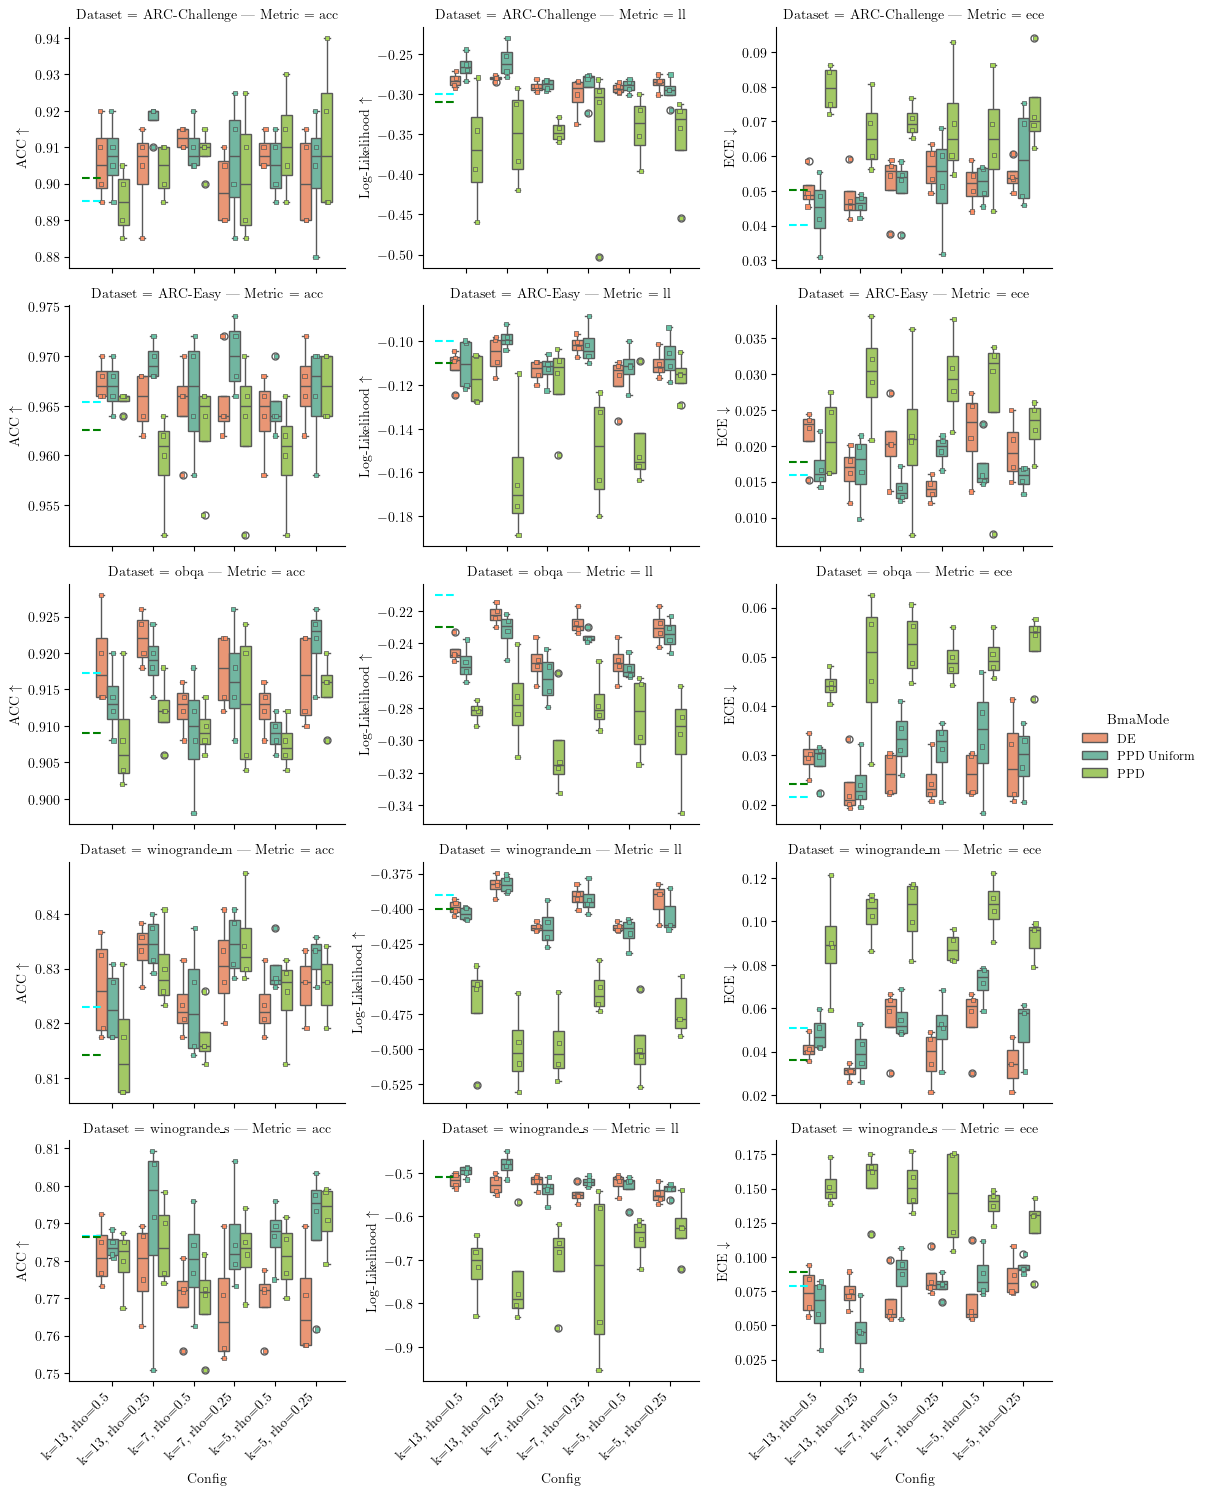

In [ ]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':  {'MLE': 78.86, 'MAP': 78.94, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':      {'MLE': 95.60, 'MAP': 95.73, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':  {'MLE': 82.30, 'MAP': 82.09, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':          {'MLE': 92.25, 'MAP': 91.72, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':         {'MLE': 89.06, 'MAP': 89.04, 'BLoB': 89.05, 'ScalaBL': 88.48},
}
# Reference NLL values (our ll = -nll, so ref_ll = -ref_nll)
ref_nll = {
    'boolq':         {'MLE': 0.25, 'MAP': 0.25, 'BLoB': 0.23, 'ScalaBL': 0.24},
    'ARC-Easy':      {'MLE': 0.44, 'MAP': 0.43, 'BLoB': 0.10, 'ScalaBL': 0.11},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.05, 'BLoB': 0.30, 'ScalaBL': 0.31},
    'obqa':          {'MLE': 0.38, 'MAP': 0.39, 'BLoB': 0.21, 'ScalaBL': 0.23},
    'winogrande_s':  {'MLE': 1.94, 'MAP': 1.88, 'BLoB': 0.51, 'ScalaBL': 0.51},
    'winogrande_m':  {'MLE': 1.20, 'MAP': 1.27, 'BLoB': 0.39, 'ScalaBL': 0.40},
}
# Reference ECE values (in %, divide by 100)
ref_ece = {
    'winogrande_s':  {'MLE': 20.14, 'MAP': 19.99, 'BLoB': 7.88,  'ScalaBL': 8.88},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54, 'BLoB': 4.03,  'ScalaBL': 5.03},
    'ARC-Easy':      {'MLE': 4.17,  'MAP': 4.08,  'BLoB': 1.60,  'ScalaBL': 1.78},
    'winogrande_m':  {'MLE': 16.10, 'MAP': 16.42, 'BLoB': 5.08,  'ScalaBL': 3.64},
    'obqa':          {'MLE': 6.40,  'MAP': 6.61,  'BLoB': 2.16,  'ScalaBL': 2.43},
    'boolq':         {'MLE': 3.79,  'MAP': 3.81,  'BLoB': 1.40,  'ScalaBL': 1.96},
}

# Melt to long form: acc, ll, ece → Metric + value
# id_cols = [c for c in df_subset.columns if c not in ('acc', 'll', 'ece')]
# df_plot = df_subset.melt(id_vars=id_cols, value_vars=['acc', 'll', 'ece'], var_name='Metric', value_name='value')

# hue_order = df_plot['BmaMode'].unique()
hue_order = ['DE', 'PPD Uniform', 'PPD']
# Single color for all hue levels
cmap = sns.color_palette("Set2")
hue_palette = {'DE': cmap[1], 'PPD Uniform': cmap[0], 'PPD': cmap[4]}

metric_order = ['acc', 'll', 'ece']

g = sns.catplot(
    data=df_plot, x='Config', y='value', hue='BmaMode', kind='box',
    row='Dataset', col='Metric', palette=hue_palette, sharey=False,
    height=figsize[1] * 1.5, row_order=col_order, col_order=metric_order,
    hue_order=hue_order, aspect=1.2
)

# Overlay strip plots
for (ds, metric), ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[(df_plot['Dataset'] == ds) & (df_plot['Metric'] == metric)],
        x='Config', y='value', hue='BmaMode',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='gray', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )

# Set y-axis labels per metric column
ylabel_map = {'acc': r'ACC $\uparrow$', 'll': r'Log-Likelihood $\uparrow$', 'ece': r'ECE $\downarrow$'}
for col_idx, metric in enumerate(metric_order):
    for ax in g.axes[:, col_idx]:
        ax.set_ylabel(ylabel_map[metric])

# Draw reference lines for all three metrics
ref_map = {
    'acc': (ref_acc, lambda v: v / 100),
    'll':  (ref_nll, lambda v: -v),       # ll = -nll
    'ece': (ref_ece, lambda v: v / 100),
}
for col_idx, metric in enumerate(metric_order):
    ref_dict, transform = ref_map[metric]
    for row_idx, ds in enumerate(col_order):
        if ds not in ref_dict:
            continue
        ax = g.axes[row_idx, col_idx]
        tick = -0.5
        # ax.hlines(y=transform(ref_dict[ds]['MLE']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='blue',  linestyles='--', lw=2.5, label='MLE')
        ax.hlines(y=transform(ref_dict[ds]['BLoB']),    xmin=tick-0.25, xmax=tick+0.25,
                  colors='cyan',  linestyles='--', lw=1.5, label='BLoB')
        ax.hlines(y=transform(ref_dict[ds]['ScalaBL']), xmin=tick-0.25, xmax=tick+0.25,
                  colors='green', linestyles='--', lw=1.5, label='ScalaBL')
        # ax.hlines(y=transform(ref_dict[ds]['MAP']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='red',   linestyles='--', lw=1.5, label='MAP')

# Rotate x-tick labels on last row
for ax in g.axes[-1, :].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

g.tight_layout()


### Bezier Segments all with and without pretraining

We run Modeconnected exp with A(t)B(t) and [1,0,0,1,0, 0,1] fixed control points. 
Then the pretrained models are used as DE members and compared against curve training with these fixed control points

In [72]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in ["qd3vby8c", "zyk44mta", "6uh01z19", "t22z66i9", "8gsfttso", "rh3grlrt", "devtarld", "79p5dbfg", "scxaczgl" ]: # winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_seg/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        if mp.get('curve_segment', False) == False:
            NCurveSegment = 1
            CurveDegree = len(mp['cp_fix']) - 1
        else:
            NCurveSegment=(len(mp['cp_fix']) - 1) // mp['curve_segment']
            CurveDegree = mp['curve_segment']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            CurveSpace=len(mp['cp_fix']),
            CpFix=str(mp['cp_fix']),
            NumPretrained=np.sum(mp['cp_fix']),
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        # add DE   
        _res = deepcopy(res)
        _res['BmaMode'] = "DE"
        _res['acc'] = run.summary.get(f"DE_acc", -np.inf)
        _res['ece'] = run.summary.get(f"DE_ece", -np.inf)
        _res['ll'] = run.summary.get(f"DE_ll", -np.inf)
        results.append(_res)
        for i, fix in enumerate(mp['cp_fix']):
            if fix != False:
                _res = deepcopy(res)
                _res['BmaMode'] = "MAP"
                # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                # print(_res['acc'], _res['ece'], _res['ll'])
                results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)

        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)
 
df = pd.DataFrame(results)
df.describe().T

qd3vby8c:   0%|          | 0/80 [00:00<?, ?it/s, glowing-sweep-71]

scxaczgl: 100%|██████████| 120/120 [00:00<00:00, 327.94it/s, stellar-sweep-1]   
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
CurveSpace,2168.0,8.743542e+00,3.757620,3.000000e+00,5.000000,7.000000,13.000000,13.000000
NumPretrained,2168.0,2.536900e+00,1.938968,0.000000e+00,0.000000,3.000000,5.000000,5.000000
Jitter,2168.0,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,2168.0,8.114182e+03,16338.680853,1.000000e+00,20.000000,400.000000,8000.000000,64000.000000
WeightDecay,2168.0,1.000000e-03,0.000000,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,2168.0,-1.000000e+00,0.000000,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,2168.0,-1.000000e+00,0.000000,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,2168.0,1.000000e+04,0.000000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,2168.0,8.000000e+00,0.000000,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,2168.0,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [73]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [13  7  5  3 11  8]
CpFix ['[1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]' '[1, 0, 0, 1, 0, 0, 1]'
 '[1, 0, 1, 0, 1]' '[1, 1, 1]' '[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]'
 '[0, 0, 0, 0, 0, 0, 0]' '[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]'
 '[0, 0, 0, 0, 0, 0, 0, 0]' '[0, 0, 0, 0, 0]' '[0, 0, 0]']
NumPretrained [5 3 0]
Jitter [0]
Seed [ 8000   400    20     1 64000    40     2   800 32000 16000]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'winogrande_s' 'obqa' 'winogrande_m']
BmaMode ['PPD' 'DE' 'MAP' 'PPD Uniform']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)' 'Asd(t)eB' 'A(t)eB']
CurveMode ['bezier' 'b-spline']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.5  0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [ 3  2  1  7  4 12 10]
NCurveSegment [4 2 5 3 1 6]
OpenEndSegment [False]

Experiment differs in ['

array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [74]:
# Build Config label
df_subset = df_clean.copy()

# df_subset = df_subset.sort_values(by='Config')

# Melt all lowercase-named columns → long form with Metric column
# lower_cols = [c for c in df_subset.columns if c[0].islower()]
# id_cols = [c for c in df_subset.columns if c not in lower_cols]
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: f"fix={r['NumPretrained']}, k={r['CurveSpace']}, SegDeg={r['CurveSegmentDegree']}, N_Seg={r['NCurveSegment']}, rho={r['LoraRho']}, Mode={r['LoraMode']}/{r['CurveMode']}", axis=1)

col_order = df_subset['Dataset'].unique()
col_order.sort()


/tmp/ipykernel_669511/2176114597.py:52: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_669511/2176114597.py:52: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_669511/2176114597.py:52: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_669511/2176114597.py:52: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_669511/2176114597.py:52: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_669511/2176114597.py:52: FutureWarning: Use "auto" to set automatic grayscale colors.

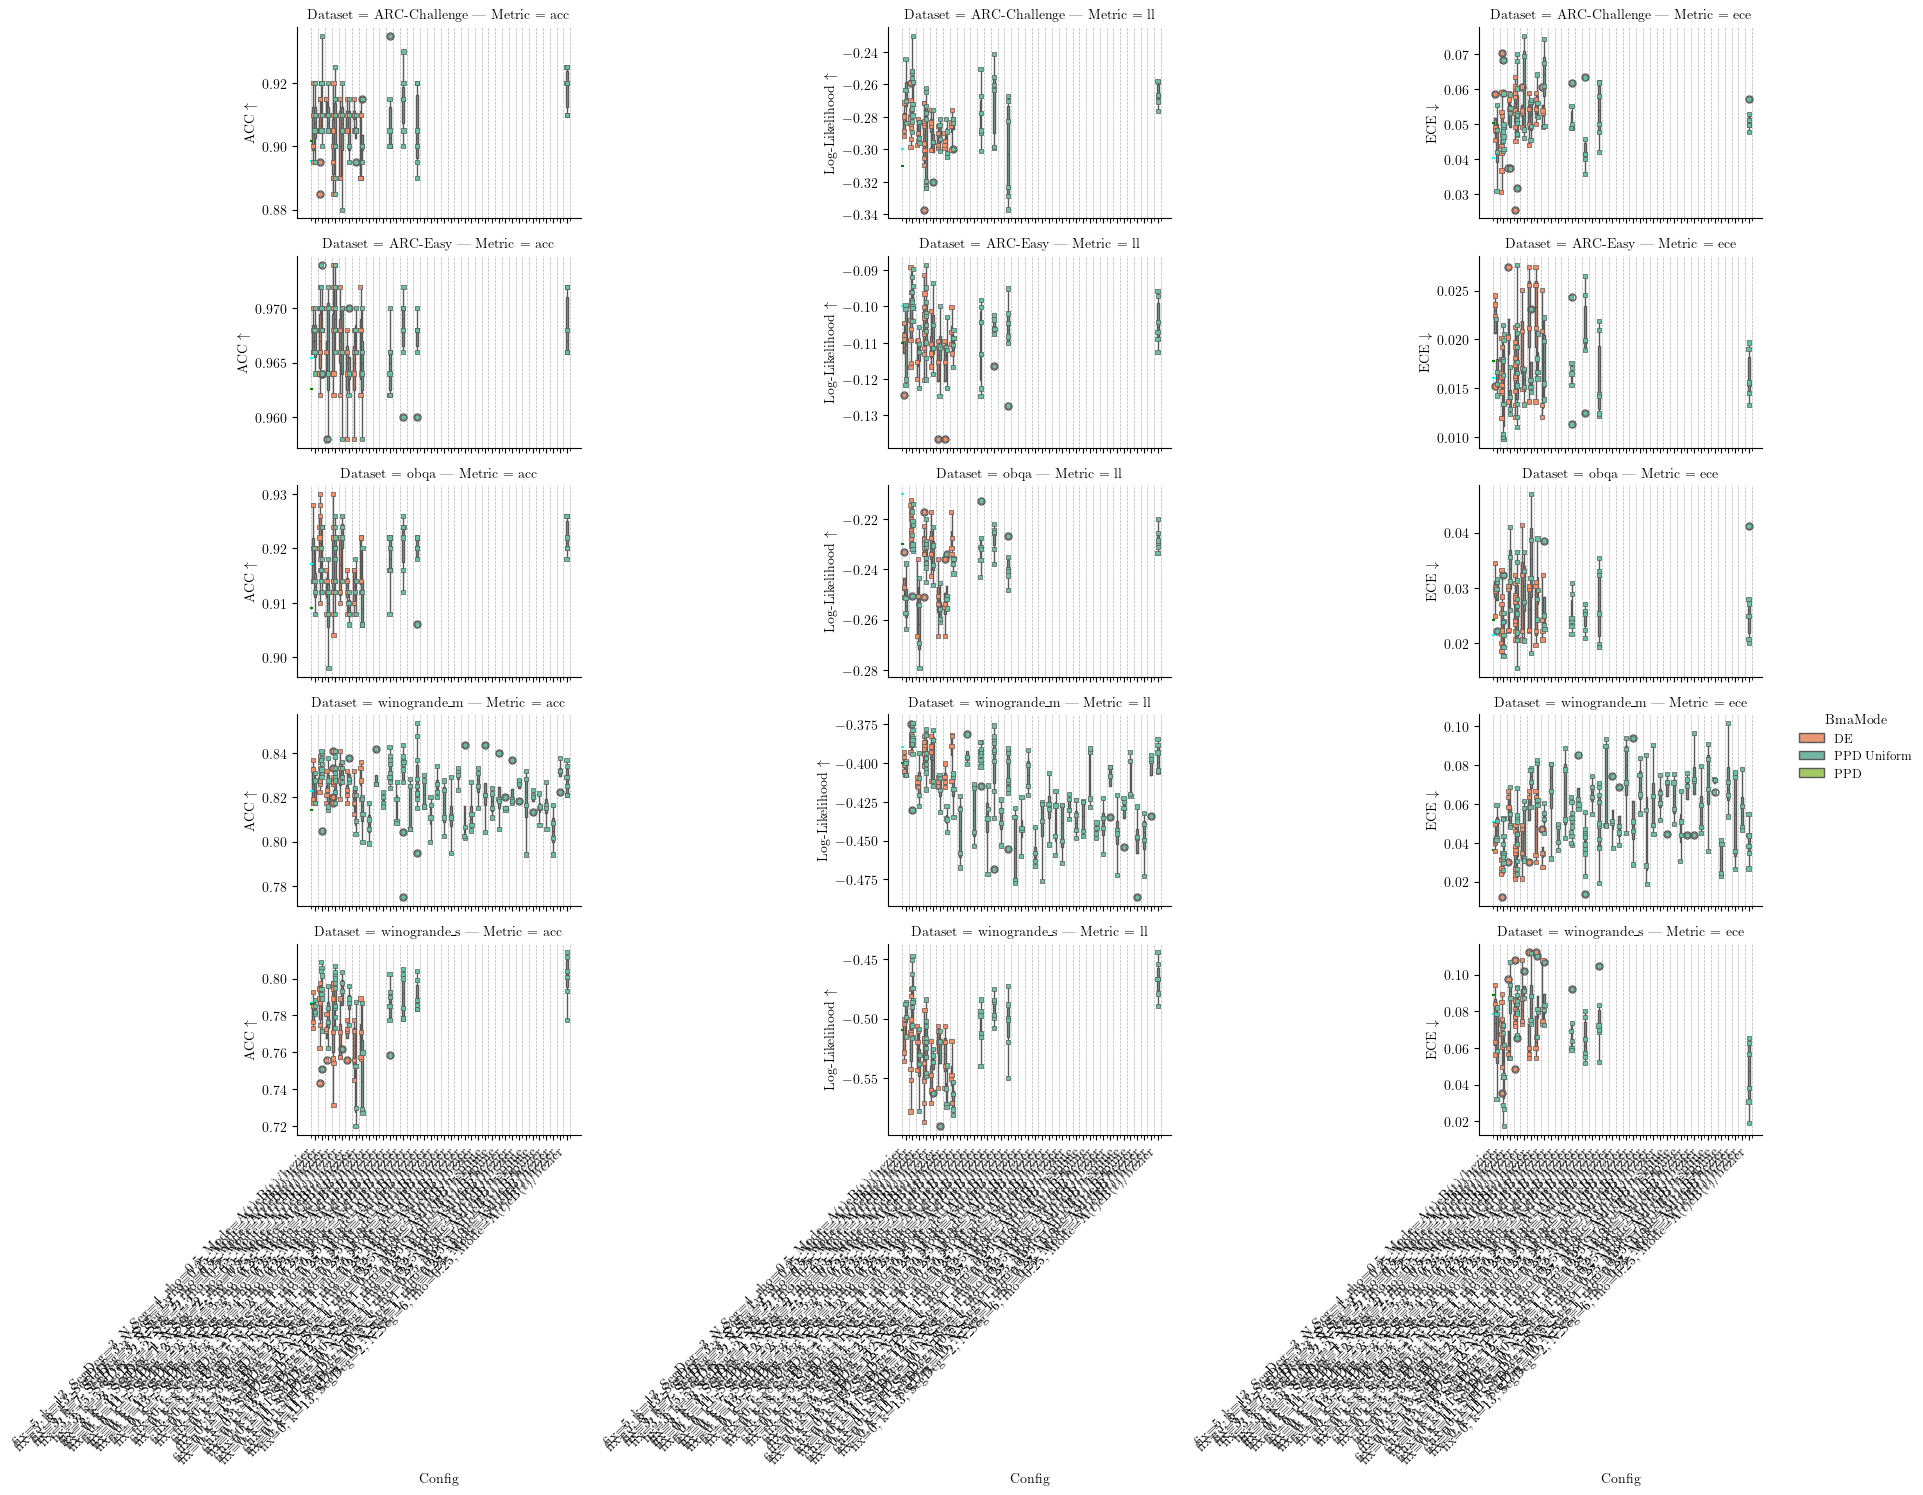

In [75]:
# all
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':  {'MLE': 78.86, 'MAP': 78.94, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':      {'MLE': 95.60, 'MAP': 95.73, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':  {'MLE': 82.30, 'MAP': 82.09, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':          {'MLE': 92.25, 'MAP': 91.72, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':         {'MLE': 89.06, 'MAP': 89.04, 'BLoB': 89.05, 'ScalaBL': 88.48},
}
# Reference NLL values (our ll = -nll, so ref_ll = -ref_nll)
ref_nll = {
    'boolq':         {'MLE': 0.25, 'MAP': 0.25, 'BLoB': 0.23, 'ScalaBL': 0.24},
    'ARC-Easy':      {'MLE': 0.44, 'MAP': 0.43, 'BLoB': 0.10, 'ScalaBL': 0.11},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.05, 'BLoB': 0.30, 'ScalaBL': 0.31},
    'obqa':          {'MLE': 0.38, 'MAP': 0.39, 'BLoB': 0.21, 'ScalaBL': 0.23},
    'winogrande_s':  {'MLE': 1.94, 'MAP': 1.88, 'BLoB': 0.51, 'ScalaBL': 0.51},
    'winogrande_m':  {'MLE': 1.20, 'MAP': 1.27, 'BLoB': 0.39, 'ScalaBL': 0.40},
}
# Reference ECE values (in %, divide by 100)
ref_ece = {
    'winogrande_s':  {'MLE': 20.14, 'MAP': 19.99, 'BLoB': 7.88,  'ScalaBL': 8.88},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54, 'BLoB': 4.03,  'ScalaBL': 5.03},
    'ARC-Easy':      {'MLE': 4.17,  'MAP': 4.08,  'BLoB': 1.60,  'ScalaBL': 1.78},
    'winogrande_m':  {'MLE': 16.10, 'MAP': 16.42, 'BLoB': 5.08,  'ScalaBL': 3.64},
    'obqa':          {'MLE': 6.40,  'MAP': 6.61,  'BLoB': 2.16,  'ScalaBL': 2.43},
    'boolq':         {'MLE': 3.79,  'MAP': 3.81,  'BLoB': 1.40,  'ScalaBL': 1.96},
}

# Melt to long form: acc, ll, ece → Metric + value
# id_cols = [c for c in df_subset.columns if c not in ('acc', 'll', 'ece')]
# df_plot = df_subset.melt(id_vars=id_cols, value_vars=['acc', 'll', 'ece'], var_name='Metric', value_name='value')
df_plot = df_plot[df_plot['BmaMode'] != 'PPD']

# hue_order = df_plot['BmaMode'].unique()
hue_order = ['DE', 'PPD Uniform', 'PPD']
# Single color for all hue levels
cmap = sns.color_palette("Set2")
hue_palette = {'DE': cmap[1], 'PPD Uniform': cmap[0], 'PPD': cmap[4]}

metric_order = ['acc', 'll', 'ece']

g = sns.catplot(
    data=df_plot, x='Config', y='value', hue='BmaMode', kind='box',
    row='Dataset', col='Metric', palette=hue_palette, sharey=False,
    height=figsize[1] * 1.5, row_order=col_order, col_order=metric_order,
    hue_order=hue_order, aspect=2
)

# Overlay strip plots
for (ds, metric), ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[(df_plot['Dataset'] == ds) & (df_plot['Metric'] == metric)],
        x='Config', y='value', hue='BmaMode',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='gray', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )

# Set y-axis labels per metric column
ylabel_map = {'acc': r'ACC $\uparrow$', 'll': r'Log-Likelihood $\uparrow$', 'ece': r'ECE $\downarrow$'}
for col_idx, metric in enumerate(metric_order):
    for ax in g.axes[:, col_idx]:
        ax.set_ylabel(ylabel_map[metric])

# Draw reference lines for all three metrics
ref_map = {
    'acc': (ref_acc, lambda v: v / 100),
    'll':  (ref_nll, lambda v: -v),       # ll = -nll
    'ece': (ref_ece, lambda v: v / 100),
}
for col_idx, metric in enumerate(metric_order):
    ref_dict, transform = ref_map[metric]
    for row_idx, ds in enumerate(col_order):
        if ds not in ref_dict:
            continue
        ax = g.axes[row_idx, col_idx]
        tick = -0.5
        # ax.hlines(y=transform(ref_dict[ds]['MLE']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='blue',  linestyles='--', lw=2.5, label='MLE')
        ax.hlines(y=transform(ref_dict[ds]['BLoB']),    xmin=tick-0.25, xmax=tick+0.25,
                  colors='cyan',  linestyles='--', lw=1.5, label='BLoB')
        ax.hlines(y=transform(ref_dict[ds]['ScalaBL']), xmin=tick-0.25, xmax=tick+0.25,
                  colors='green', linestyles='--', lw=1.5, label='ScalaBL')
        # ax.hlines(y=transform(ref_dict[ds]['MAP']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='red',   linestyles='--', lw=1.5, label='MAP')

# Rotate x-tick labels on last row
for ax in g.axes[-1, :].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

g.tight_layout()

# make grid (only lines for y-axis) but at +- 0.5pt
major_ticks = ax.get_xticks()
minor_ticks = np.arange(start=min(major_ticks) - 0.5, 
                        stop=max(major_ticks) + 1.5, 
                        step=1)
# Set these positions as minor ticks
ax.set_xticks(minor_ticks, minor=True)
for ax in g.axes.flat:
    ax.grid(True, axis='x', which='minor', linestyle='--', linewidth=0.5,)


/tmp/ipykernel_669511/2042315865.py:31: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_669511/2042315865.py:31: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_669511/2042315865.py:31: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_669511/2042315865.py:31: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_669511/2042315865.py:31: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


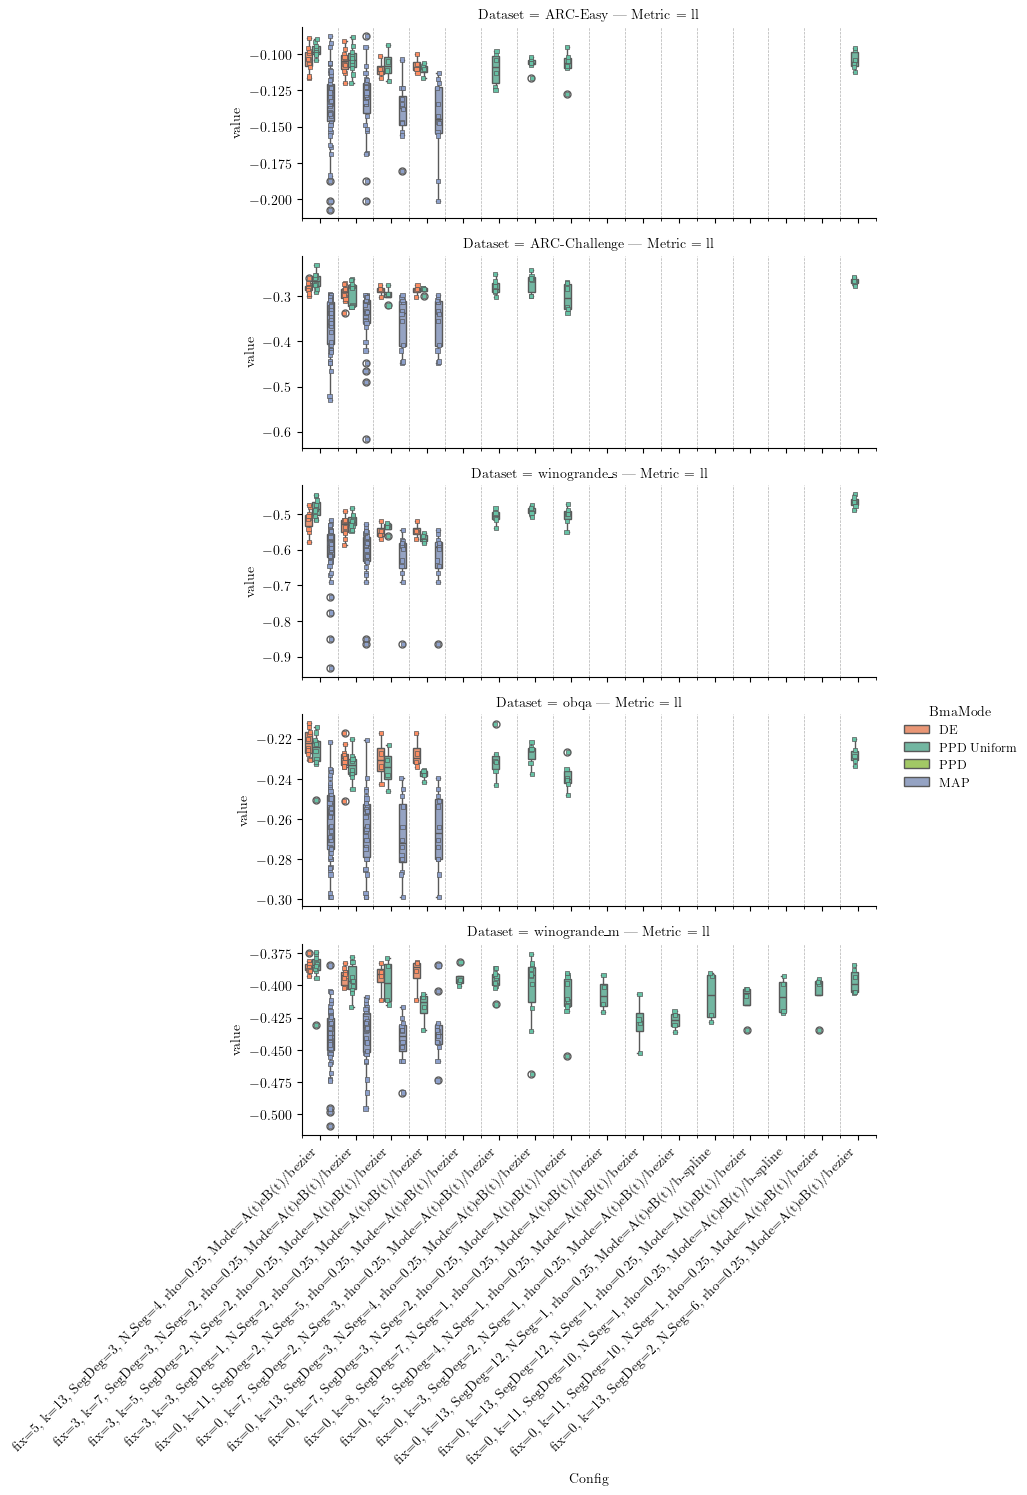

In [76]:
# DE vs Curve
# Build Config label
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: f"fix={r['NumPretrained']}, k={r['CurveSpace']}, SegDeg={r['CurveSegmentDegree']}, N_Seg={r['NCurveSegment']}, rho={r['LoraRho']}, Mode={r['LoraMode']}/{r['CurveMode']}", axis=1)

# Melt to long form: acc, ll, ece → Metric + value
# id_cols = [c for c in df_subset.columns if c not in ('acc', 'll', 'ece')]
# df_plot = df_subset.melt(id_vars=id_cols, value_vars=['acc', 'll', 'ece'], var_name='Metric', value_name='value')
df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]

# hue_order = df_plot['BmaMode'].unique()
hue_order = ['DE', 'PPD Uniform', 'PPD', 'MAP']
# Single color for all hue levels
cmap = sns.color_palette("Set2")
hue_palette = {'DE': cmap[1], 'PPD Uniform': cmap[0], 'PPD': cmap[4], 'MAP': cmap[2]}

metric_order = ['acc', 'll', 'ece']

g = sns.catplot(
    data=df_plot, x='Config', y='value', hue='BmaMode', kind='box',
    row='Dataset', col='Metric', palette=hue_palette, sharey=False,
    height=figsize[1] * 1.5,
    hue_order=hue_order, aspect=3
)

# Overlay strip plots
for (ds, metric), ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[(df_plot['Dataset'] == ds) & (df_plot['Metric'] == metric)],
        x='Config', y='value', hue='BmaMode',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='gray', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )

# # Set y-axis labels per metric column
# ylabel_map = {'acc': r'ACC $\uparrow$', 'll': r'Log-Likelihood $\uparrow$', 'ece': r'ECE $\downarrow$'}
# for col_idx, metric in enumerate(metric_order):
#     for ax in g.axes[:, col_idx]:
#         ax.set_ylabel(ylabel_map[metric])


# Rotate x-tick labels on last row
for ax in g.axes[-1, :].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

g.tight_layout()

# make grid (only lines for y-axis) but at +- 0.5pt
major_ticks = ax.get_xticks()
minor_ticks = np.arange(start=min(major_ticks) - 0.5, 
                        stop=max(major_ticks) + 1.5, 
                        step=1)
# Set these positions as minor ticks
ax.set_xticks(minor_ticks, minor=True)
for ax in g.axes.flat:
    ax.grid(True, axis='x', which='minor', linestyle='--', linewidth=0.5,)


#### final summary

In [77]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: f"fix={r['NumPretrained']}, k={r['CurveSpace']}, SegDeg={r['CurveSegmentDegree']}, N_Seg={r['NCurveSegment']}, rho={r['LoraRho']}, Mode={r['LoraMode']}/{r['CurveMode']}", axis=1)

# Melt to long form: acc, ll, ece → Metric + value
# id_cols = [c for c in df_subset.columns if c not in ('acc', 'll', 'ece')]
# df_plot = df_subset.melt(id_vars=id_cols, value_vars=['acc', 'll', 'ece'], var_name='Metric', value_name='value')
df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]


def map_model(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE({x['NumPretrained']})"
    elif x['BmaMode'] == 'PPD Uniform':
        return f"Fix={np.sum(x['NumPretrained']) > 0}, N_Seg={x['NCurveSegment']}, SegDeg={x['CurveSegmentDegree']}"

df_plot['Model'] = df_plot.apply(map_model, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot.loc[df_plot['BmaMode'] == 'MAP', 'NCurveSegment'] = 0
df_plot.loc[df_plot['BmaMode'] == 'DE', 'NCurveSegment'] = 0

df_plot.sort_values(by=['Model'], inplace=True)

# df_plot['NCurveSegment'] = pd.Categorical(df_plot['NCurveSegment'], categories=sorted(df_plot['NCurveSegment'].unique()), ordered=True)

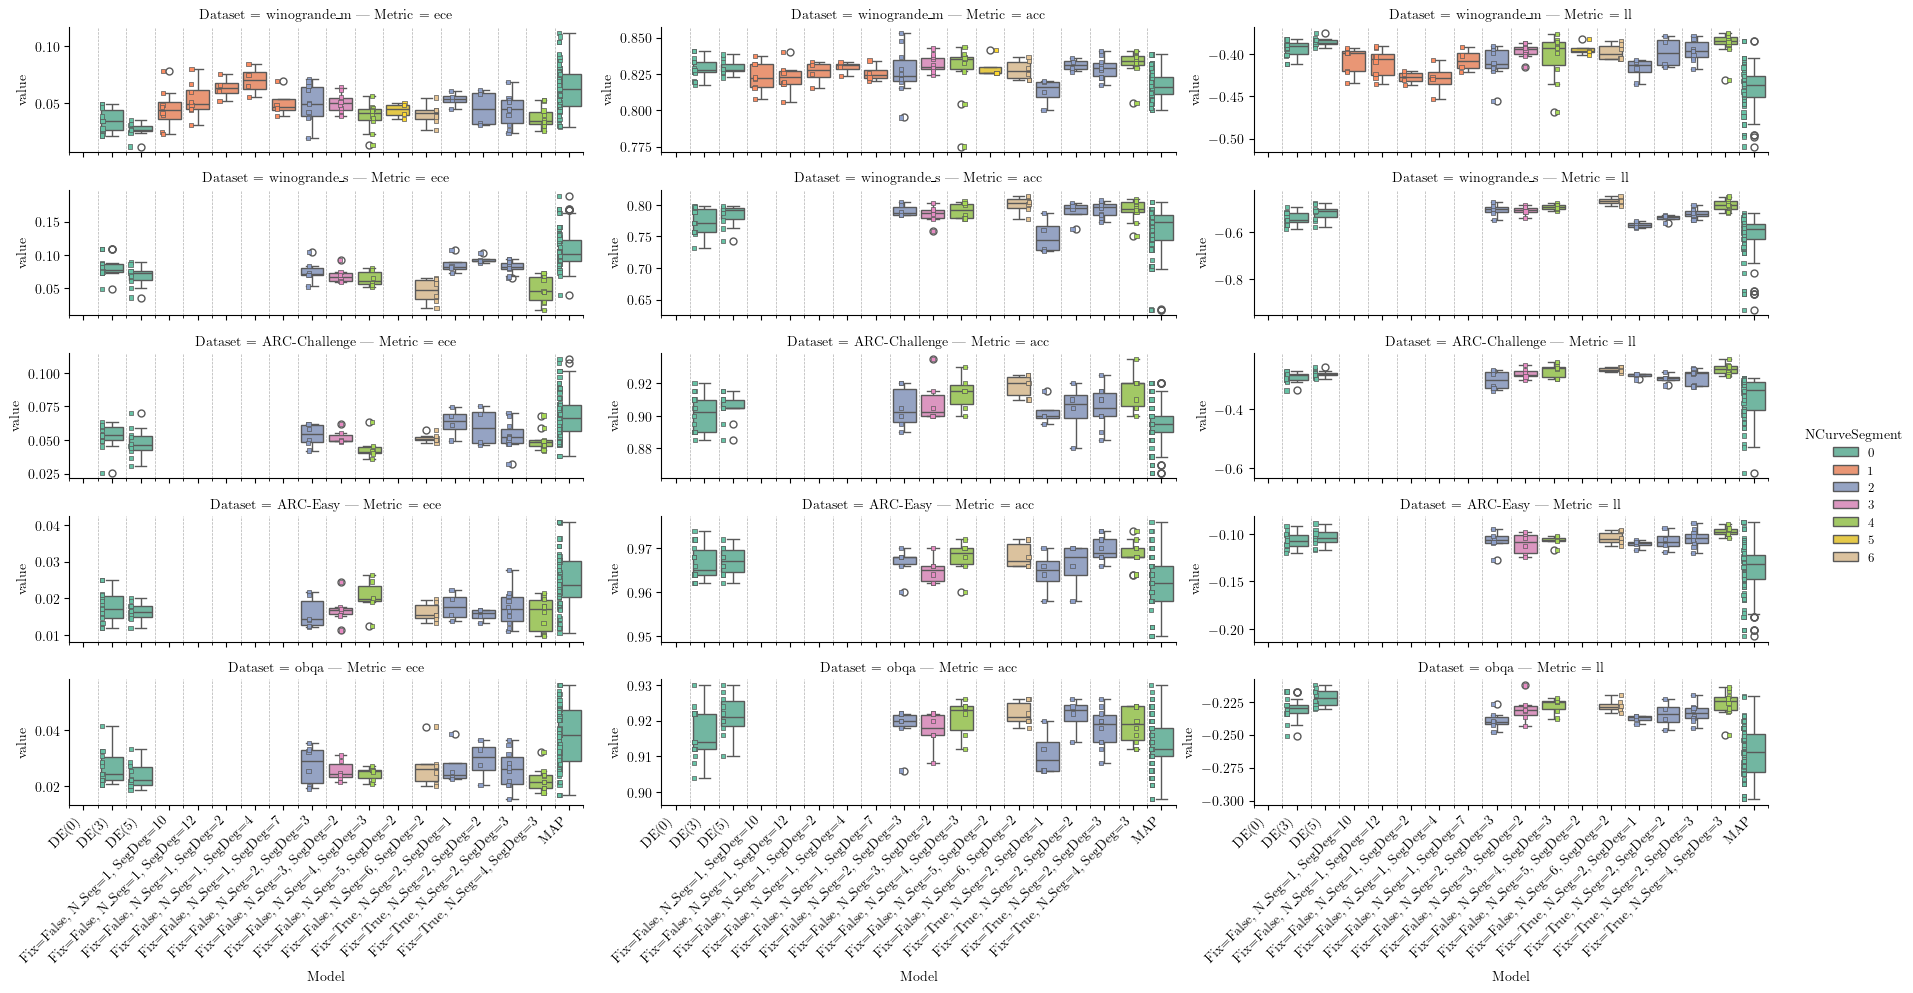

In [78]:
numeric_rhos = sorted(int(x) for x in df_plot['NCurveSegment'].unique())
df_plot['NCurveSegment'] = df_plot['NCurveSegment'].astype(str)
hue_order = [str(x) for x in numeric_rhos]

hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))


g = sns.catplot(
    data=df_plot, x='Model', y='value', hue='NCurveSegment', kind='box',
    row='Dataset', col='Metric', palette=hue_palette, sharey=False,
    height=figsize[1] * 1.,
    hue_order=hue_order, aspect=3
)

# Overlay strip plots
for (ds, metric), ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[(df_plot['Dataset'] == ds) & (df_plot['Metric'] == metric)],
        x='Model', y='value', hue='NCurveSegment',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='auto', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False,
    )

# # Set y-axis labels per metric column
# ylabel_map = {'acc': r'ACC $\uparrow$', 'll': r'Log-Likelihood $\uparrow$', 'ece': r'ECE $\downarrow$'}
# for col_idx, metric in enumerate(metric_order):
#     for ax in g.axes[:, col_idx]:
#         ax.set_ylabel(ylabel_map[metric])


# Rotate x-tick labels on last row
for ax in g.axes[-1, :].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

g.tight_layout()

# make grid (only lines for y-axis) but at +- 0.5pt
major_ticks = ax.get_xticks()
minor_ticks = np.arange(start=min(major_ticks) - 0.5, 
                        stop=max(major_ticks) + 1.5, 
                        step=1)
# Set these positions as minor ticks
ax.set_xticks(minor_ticks, minor=True)
for ax in g.axes.flat:
    ax.grid(True, axis='x', which='minor', linestyle='--', linewidth=0.5,)


In [79]:
summary_df = df_plot[['Dataset', 'Model', 'Metric', 'value']].dropna(subset=['value'])
summary_df = summary_df[np.isfinite(summary_df['value'])]
summary_df_csv = summary_df.groupby(['Dataset', 'Model', 'Metric'])['value'].describe(percentiles=[]).pivot_table(index=['Dataset'], columns=['Metric', 'Model']).T
summary_df_csv.to_csv("summary.csv")
summary_df_csv

Dataset                                   ARC-Challenge  ARC-Easy      obqa  \
    Metric Model                                                              
50% acc    DE(3)                               0.902500  0.965000  0.914000   
           DE(5)                               0.905000  0.967000  0.921000   
           Fix=False, N_Seg=1, SegDeg=10            NaN       NaN       NaN   
           Fix=False, N_Seg=1, SegDeg=12            NaN       NaN       NaN   
           Fix=False, N_Seg=1, SegDeg=2             NaN       NaN       NaN   
...                                                 ...       ...       ...   
std ll     Fix=True, N_Seg=2, SegDeg=1         0.008822  0.004388  0.002772   
           Fix=True, N_Seg=2, SegDeg=2         0.018209  0.010560  0.009981   
           Fix=True, N_Seg=2, SegDeg=3         0.026274  0.009207  0.006957   
           Fix=True, N_Seg=4, SegDeg=3         0.017999  0.004308  0.010346   
           MAP                                 0.061872  0.024591  0.018282   

Dataset                                   winogrande_m  winogrande_s  
    Metric Model                                                      
50% acc    DE(3)                              0.827500      0.770833  
           DE(5)                              0.827917      0.791250  
           Fix=False, N_Seg=1, SegDeg=10      0.822083           NaN  
           Fix=False, N_Seg=1, SegDeg=12      0.822500           NaN  
           Fix=False, N_Seg=1, SegDeg=2       0.827917           NaN  
...                                                ...           ...  
std ll     Fix=True, N_Seg=2, SegDeg=1        0.012679      0.012659  
           Fix=True, N_Seg=2, SegDeg=2        0.018335      0.016482  
           Fix=True, N_Seg=2, SegDeg=3        0.012277      0.020026  
           Fix=True, N_Seg=4, SegDeg=3        0.016112      0.024809  
           MAP                                0.022073      0.079994  

[306 rows x 5 columns]

In [80]:
df_summary = df_plot.groupby(['Dataset', 'Model', 'Metric'])['value',].mean().pivot_table(index=['Dataset'], columns=['Metric', 'Model']).T
df_summary_std = 2*df_plot.groupby(['Dataset', 'Model', 'Metric'])['value',].std().pivot_table(index=['Dataset'], columns=['Metric', 'Model']).T
# combine summary with mean +-std and only 2 decimal places
df_summary = df_summary.round(2)
df_summary_std = df_summary_std.round(2)
df_summary_combined = df_summary.astype(str) + " ± " + df_summary_std.astype(str)
df_summary_combined

Dataset                                    ARC-Challenge      ARC-Easy  \
      Metric Model                                                       
value acc    DE(0)                                   NaN           NaN   
             DE(3)                            0.9 ± 0.02   0.97 ± 0.01   
             DE(5)                            0.9 ± 0.02   0.97 ± 0.01   
             Fix=False, N_Seg=1, SegDeg=10     nan ± nan     nan ± nan   
             Fix=False, N_Seg=1, SegDeg=12     nan ± nan     nan ± nan   
             Fix=False, N_Seg=1, SegDeg=2      nan ± nan     nan ± nan   
             Fix=False, N_Seg=1, SegDeg=4      nan ± nan     nan ± nan   
             Fix=False, N_Seg=1, SegDeg=7      nan ± nan     nan ± nan   
             Fix=False, N_Seg=2, SegDeg=3     0.9 ± 0.03   0.97 ± 0.01   
             Fix=False, N_Seg=3, SegDeg=2    0.91 ± 0.03   0.97 ± 0.01   
             Fix=False, N_Seg=4, SegDeg=3    0.91 ± 0.02   0.97 ± 0.01   
             Fix=False, N_Seg=5, SegDeg=2      nan ± nan     nan ± nan   
             Fix=False, N_Seg=6, SegDeg=2    0.92 ± 0.01   0.97 ± 0.01   
             Fix=True, N_Seg=2, SegDeg=1      0.9 ± 0.02   0.96 ± 0.01   
             Fix=True, N_Seg=2, SegDeg=2      0.9 ± 0.03   0.97 ± 0.01   
             Fix=True, N_Seg=2, SegDeg=3      0.9 ± 0.02   0.97 ± 0.01   
             Fix=True, N_Seg=4, SegDeg=3     0.92 ± 0.02   0.97 ± 0.01   
             MAP                             0.89 ± 0.02   0.96 ± 0.01   
      ece    DE(0)                                   NaN           NaN   
             DE(3)                           0.05 ± 0.02   0.02 ± 0.01   
             DE(5)                           0.05 ± 0.02    0.02 ± 0.0   
             Fix=False, N_Seg=1, SegDeg=10     nan ± nan     nan ± nan   
             Fix=False, N_Seg=1, SegDeg=12     nan ± nan     nan ± nan   
             Fix=False, N_Seg=1, SegDeg=2      nan ± nan     nan ± nan   
             Fix=False, N_Seg=1, SegDeg=4      nan ± nan     nan ± nan   
             Fix=False, N_Seg=1, SegDeg=7      nan ± nan     nan ± nan   
             Fix=False, N_Seg=2, SegDeg=3    0.05 ± 0.02   0.02 ± 0.01   
             Fix=False, N_Seg=3, SegDeg=2    0.05 ± 0.01   0.02 ± 0.01   
             Fix=False, N_Seg=4, SegDeg=3    0.04 ± 0.02   0.02 ± 0.01   
             Fix=False, N_Seg=5, SegDeg=2      nan ± nan     nan ± nan   
             Fix=False, N_Seg=6, SegDeg=2    0.05 ± 0.01   0.02 ± 0.01   
             Fix=True, N_Seg=2, SegDeg=1     0.06 ± 0.02   0.02 ± 0.01   
             Fix=True, N_Seg=2, SegDeg=2     0.06 ± 0.03    0.02 ± 0.0   
             Fix=True, N_Seg=2, SegDeg=3     0.05 ± 0.02   0.02 ± 0.01   
             Fix=True, N_Seg=4, SegDeg=3     0.05 ± 0.02   0.02 ± 0.01   
             MAP                             0.07 ± 0.03   0.02 ± 0.01   
      ll     DE(0)                                   NaN           NaN   
             DE(3)                          -0.29 ± 0.03  -0.11 ± 0.01   
             DE(5)                          -0.28 ± 0.02   -0.1 ± 0.02   
             Fix=False, N_Seg=1, SegDeg=10     nan ± nan     nan ± nan   
             Fix=False, N_Seg=1, SegDeg=12     nan ± nan     nan ± nan   
             Fix=False, N_Seg=1, SegDeg=2      nan ± nan     nan ± nan   
             Fix=False, N_Seg=1, SegDeg=4      nan ± nan     nan ± nan   
             Fix=False, N_Seg=1, SegDeg=7      nan ± nan     nan ± nan   
             Fix=False, N_Seg=2, SegDeg=3    -0.3 ± 0.06  -0.11 ± 0.02   
             Fix=False, N_Seg=3, SegDeg=2   -0.28 ± 0.04  -0.11 ± 0.02   
             Fix=False, N_Seg=4, SegDeg=3   -0.27 ± 0.05  -0.11 ± 0.01   
             Fix=False, N_Seg=5, SegDeg=2      nan ± nan     nan ± nan   
             Fix=False, N_Seg=6, SegDeg=2   -0.27 ± 0.01   -0.1 ± 0.01   
             Fix=True, N_Seg=2, SegDeg=1    -0.29 ± 0.02  -0.11 ± 0.01   
             Fix=True, N_Seg=2, SegDeg=2     -0.3 ± 0.04  -0.11 ± 0.02   
             Fix=True, N_Seg=2, SegDeg=3    -0.29 ± 0.05   -0.1 ± 0.02   
    

In [81]:
df_summary_combined.to_csv("summary_mean_std.csv")

#### sampling results

In [85]:
from pathlib import Path

sampling_files = [
    "result/sampling/wino_m_psmile.csv",
    "result/sampling/wino_m_sghmc.csv",
    "result/sampling/wino_s_psmile.csv",
    "result/sampling/wino_s_sghmc.csv",
]

rows = []
for file_path in sampling_files:
    df_s = pd.read_csv(file_path)

    # Keep only the step size that corresponds to rng=400 in this file
    ref = df_s[df_s["rng"] == 400]
    if ref.empty:
        print(f"Skipping {file_path}: no rng=400 row found")
        continue
    step_size = ref.iloc[0]["training_sampler_step_size"]
    df_sel = df_s[df_s["training_sampler_step_size"] == step_size].copy()

    dataset = "winogrande_m" if "wino_m" in file_path else "winogrande_s"

    # Build the same core structure used in our extracted dataframe
    for _, r in df_sel.iterrows():
        rows.append(
            {
                "Id": str(r.get("experiment", Path(file_path).stem)),
                "CurveSpace": -1,
                "CpFix": "sampling",
                "NumPretrained": -1,
                "Jitter": -1,
                "Seed": int(r.get("rng", -1)) if pd.notna(r.get("rng", np.nan)) else -1,
                "WeightDecay": -1,
                "Dataset": dataset,
                "BmaMode": "Sampling",
                "DS_Sampling": str(r.get("training_sampler_name", "unknown")),
                "DS_Mode": "sampler",
                "DS_WindowSize": -1,
                "EntropyMaxScale": -1,
                "NumSteps": -1,
                "LoraMode": "Sampling",
                "CurveMode": "Sampling",
                "LoraRank": -1,
                "RegularizationMode": False,
                "Gravity": -1,
                "EnergyWeakening": -1,
                "Tsample": "sampling",
                "LoraRho": -1,
                "LoraRhoS": -1,
                "RhoFrequency": -1,
                "CurveSegmentDegree": -1,
                "NCurveSegment": 0,
                "OpenEndSegment": False,
                "bezierLength": 0,
                "acc": r.get("PredPerf_sampling_bma_accuracy", np.nan),
                "ece": r.get("Calibration_sampling_calibration_error", np.nan),
                "ll": r.get("LPPD_sampling_LPPD", np.nan),
                "test_mean_entropy_ppd": np.nan,
                "test_mutual_information_ppd": np.nan,
                "test_std_entropy_along_curve": np.nan,
                "test_mean_entropy_along_curve": np.nan,
                "Method": str(r.get("training_sampler_name", "unknown")),
                "SamplerStepSize": step_size,
                "SourceFile": Path(file_path).name,
            }
        )

    print(f"{Path(file_path).name}: step_size@rng400={step_size}, rows_kept={len(df_sel)}")

df_sampling = pd.DataFrame(rows)

out_path = "result/sampling/sampling_merged_rng400_stepsize.csv"
df_sampling.to_csv(out_path, index=False)
print(f"Saved merged sampling dataframe to {out_path} with {len(df_sampling)} rows")

df_sampling = df_sampling.melt(
    id_vars=[c for c in df_sampling.columns if c not in ["acc", "ll", "ece"]],
    value_vars=["acc", "ll", "ece"],
    var_name="Metric",
    value_name="value",
)
df_sampling["Model"] = df_sampling["Method"].apply(lambda m: "Sampling-PSMILE" if m  == "noisysmile" in m else f"Sampling-SGHMC")
df_sampling["NCurveSegment"] = 0

df_sampling.head()



wino_m_psmile.csv: step_size@rng400=0.0001, rows_kept=5
wino_m_sghmc.csv: step_size@rng400=5e-06, rows_kept=5
wino_s_psmile.csv: step_size@rng400=0.01, rows_kept=5
wino_s_sghmc.csv: step_size@rng400=0.0001, rows_kept=5
Saved merged sampling dataframe to result/sampling/sampling_merged_rng400_stepsize.csv with 20 rows


,Id,CurveSpace,CpFix,NumPretrained,Jitter,Seed,WeightDecay,Dataset,BmaMode,DS_Sampling,...,test_mean_entropy_ppd,test_mutual_information_ppd,test_std_entropy_along_curve,test_mean_entropy_along_curve,Method,SamplerStepSize,SourceFile,Metric,value,Model
0,lora_wino_m_div5_20260320-063059,-1,sampling,-1,-1,40,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.830833,Sampling-PSMILE
1,lora_wino_m_div5_20260320-051752,-1,sampling,-1,-1,20,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.831667,Sampling-PSMILE
2,lora_wino_m_div5_20260320-074403,-1,sampling,-1,-1,400,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.835000,Sampling-PSMILE
3,lora_wino_m_div5_20260320-040549,-1,sampling,-1,-1,2,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.832500,Sampling-PSMILE
4,lora_wino_m_div5_2_20260317-211143,-1,sampling,-1,-1,1,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.838333,Sampling-PSMILE


#### ScalaBL rerun

In [86]:
api = wandb.Api()
scalabl_rows = []
for run in tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"), desc="ScalaBL from W&B"):
    if run.state != "finished":
        continue
    dataset = run.config.get("dataset")
    if dataset is None:
        continue

    acc = run.summary.get("final_val_acc", np.nan)
    ece = run.summary.get("final_val_ece", np.nan)
    nll = run.summary.get("final_val_nll", np.nan)
    ll = -nll if pd.notna(nll) else np.nan

    scalabl_rows.append({"Dataset": dataset, "Metric": "acc", "Model": "ScalaBL WB", "value": acc, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ece", "Model": "ScalaBL WB", "value": ece, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ll", "Model": "ScalaBL WB", "value": ll, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})

for run in tqdm(api.runs("ddold/BLoB-Qwen2.5-7B-id"), desc="BLoB from W&B"):
    if run.state != "finished":
        continue
    dataset = run.config.get("dataset")
    if dataset is None:
        continue

    acc = run.summary.get("final_val_acc", np.nan)
    ece = run.summary.get("final_val_ece", np.nan)
    nll = run.summary.get("final_val_nll", np.nan)
    ll = -nll if pd.notna(nll) else np.nan

    scalabl_rows.append({"Dataset": dataset, "Metric": "acc", "Model": "BLoB WB", "value": acc, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ece", "Model": "BLoB WB", "value": ece, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ll", "Model": "BLoB WB", "value": ll, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})


ref_acc = {
    'winogrande_s':  {'MLE': 78.86, 'MAP': 78.94, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':      {'MLE': 95.60, 'MAP': 95.73, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':  {'MLE': 82.30, 'MAP': 82.09, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':          {'MLE': 92.25, 'MAP': 91.72, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':         {'MLE': 89.06, 'MAP': 89.04, 'BLoB': 89.05, 'ScalaBL': 88.48},
}
# Reference NLL values (our ll = -nll, so ref_ll = -ref_nll)
ref_nll = {
    'boolq':         {'MLE': 0.25, 'MAP': 0.25, 'BLoB': 0.23, 'ScalaBL': 0.24},
    'ARC-Easy':      {'MLE': 0.44, 'MAP': 0.43, 'BLoB': 0.10, 'ScalaBL': 0.11},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.05, 'BLoB': 0.30, 'ScalaBL': 0.31},
    'obqa':          {'MLE': 0.38, 'MAP': 0.39, 'BLoB': 0.21, 'ScalaBL': 0.23},
    'winogrande_s':  {'MLE': 1.94, 'MAP': 1.88, 'BLoB': 0.51, 'ScalaBL': 0.51},
    'winogrande_m':  {'MLE': 1.20, 'MAP': 1.27, 'BLoB': 0.39, 'ScalaBL': 0.40},
}
# Reference ECE values (in %, divide by 100)
ref_ece = {
    'winogrande_s':  {'MLE': 20.14, 'MAP': 19.99, 'BLoB': 7.88,  'ScalaBL': 8.88},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54, 'BLoB': 4.03,  'ScalaBL': 5.03},
    'ARC-Easy':      {'MLE': 4.17,  'MAP': 4.08,  'BLoB': 1.60,  'ScalaBL': 1.78},
    'winogrande_m':  {'MLE': 16.10, 'MAP': 16.42, 'BLoB': 5.08,  'ScalaBL': 3.64},
    'obqa':          {'MLE': 6.40,  'MAP': 6.61,  'BLoB': 2.16,  'ScalaBL': 2.43},
    'boolq':         {'MLE': 3.79,  'MAP': 3.81,  'BLoB': 1.40,  'ScalaBL': 1.96},
}
ref_map = {
    'acc': jax.tree.map(lambda v: v / 100, ref_acc),  # convert % to [0,1]
    'll':  jax.tree.map(lambda v: -v, ref_nll),       # ll = -nll
    'ece': jax.tree.map(lambda v: v / 100, ref_ece),
}
metric_order = ['acc', 'll', 'ece']
df_vi_paper = pd.DataFrame([
        {'Dataset': ds, 'Metric': metric, 'Model': model, 'value': ref_map[metric][ds][model], 'NCurveSegment': 0}
        for ds in col_order for metric in metric_order for model in ['BLoB', 'ScalaBL']
    ])

df_vi = pd.DataFrame(scalabl_rows)
df_vi.head()


BLoB from W&B: 100%|██████████| 48/48 [00:00<00:00, 24441.74it/s]


,Dataset,Metric,Model,value,NCurveSegment,Seed
0,winogrande_s,acc,ScalaBL WB,0.793513,0,0
1,winogrande_s,ece,ScalaBL WB,0.079228,0,0
2,winogrande_s,ll,ScalaBL WB,-0.511719,0,0
3,winogrande_s,acc,ScalaBL WB,0.785601,0,7
4,winogrande_s,ece,ScalaBL WB,0.087242,0,7


In [87]:

# stack df_vi to df_plot
df_plot['NCurveSegment'] = df_plot['NCurveSegment'].astype(int)
df_plot_ = pd.concat([df_plot, df_vi_paper, df_vi, df_sampling], ignore_index=True)

In [88]:
df_plot_[['Model','NCurveSegment', 'Dataset', 'Metric', 'value']]

,Model,NCurveSegment,Dataset,Metric,value
0,DE(0),0,winogrande_m,ece,-inf
1,DE(0),0,winogrande_s,ece,-inf
2,DE(0),0,winogrande_s,ece,-inf
3,DE(0),0,winogrande_s,ece,-inf
4,DE(0),0,winogrande_s,ece,-inf
...,...,...,...,...,...
3745,Sampling-SGHMC,0,winogrande_s,ece,0.017275
3746,Sampling-SGHMC,0,winogrande_s,ece,0.013964
3747,Sampling-SGHMC,0,winogrande_s,ece,0.016158
3748,Sampling-SGHMC,0,winogrande_s,ece,0.013625


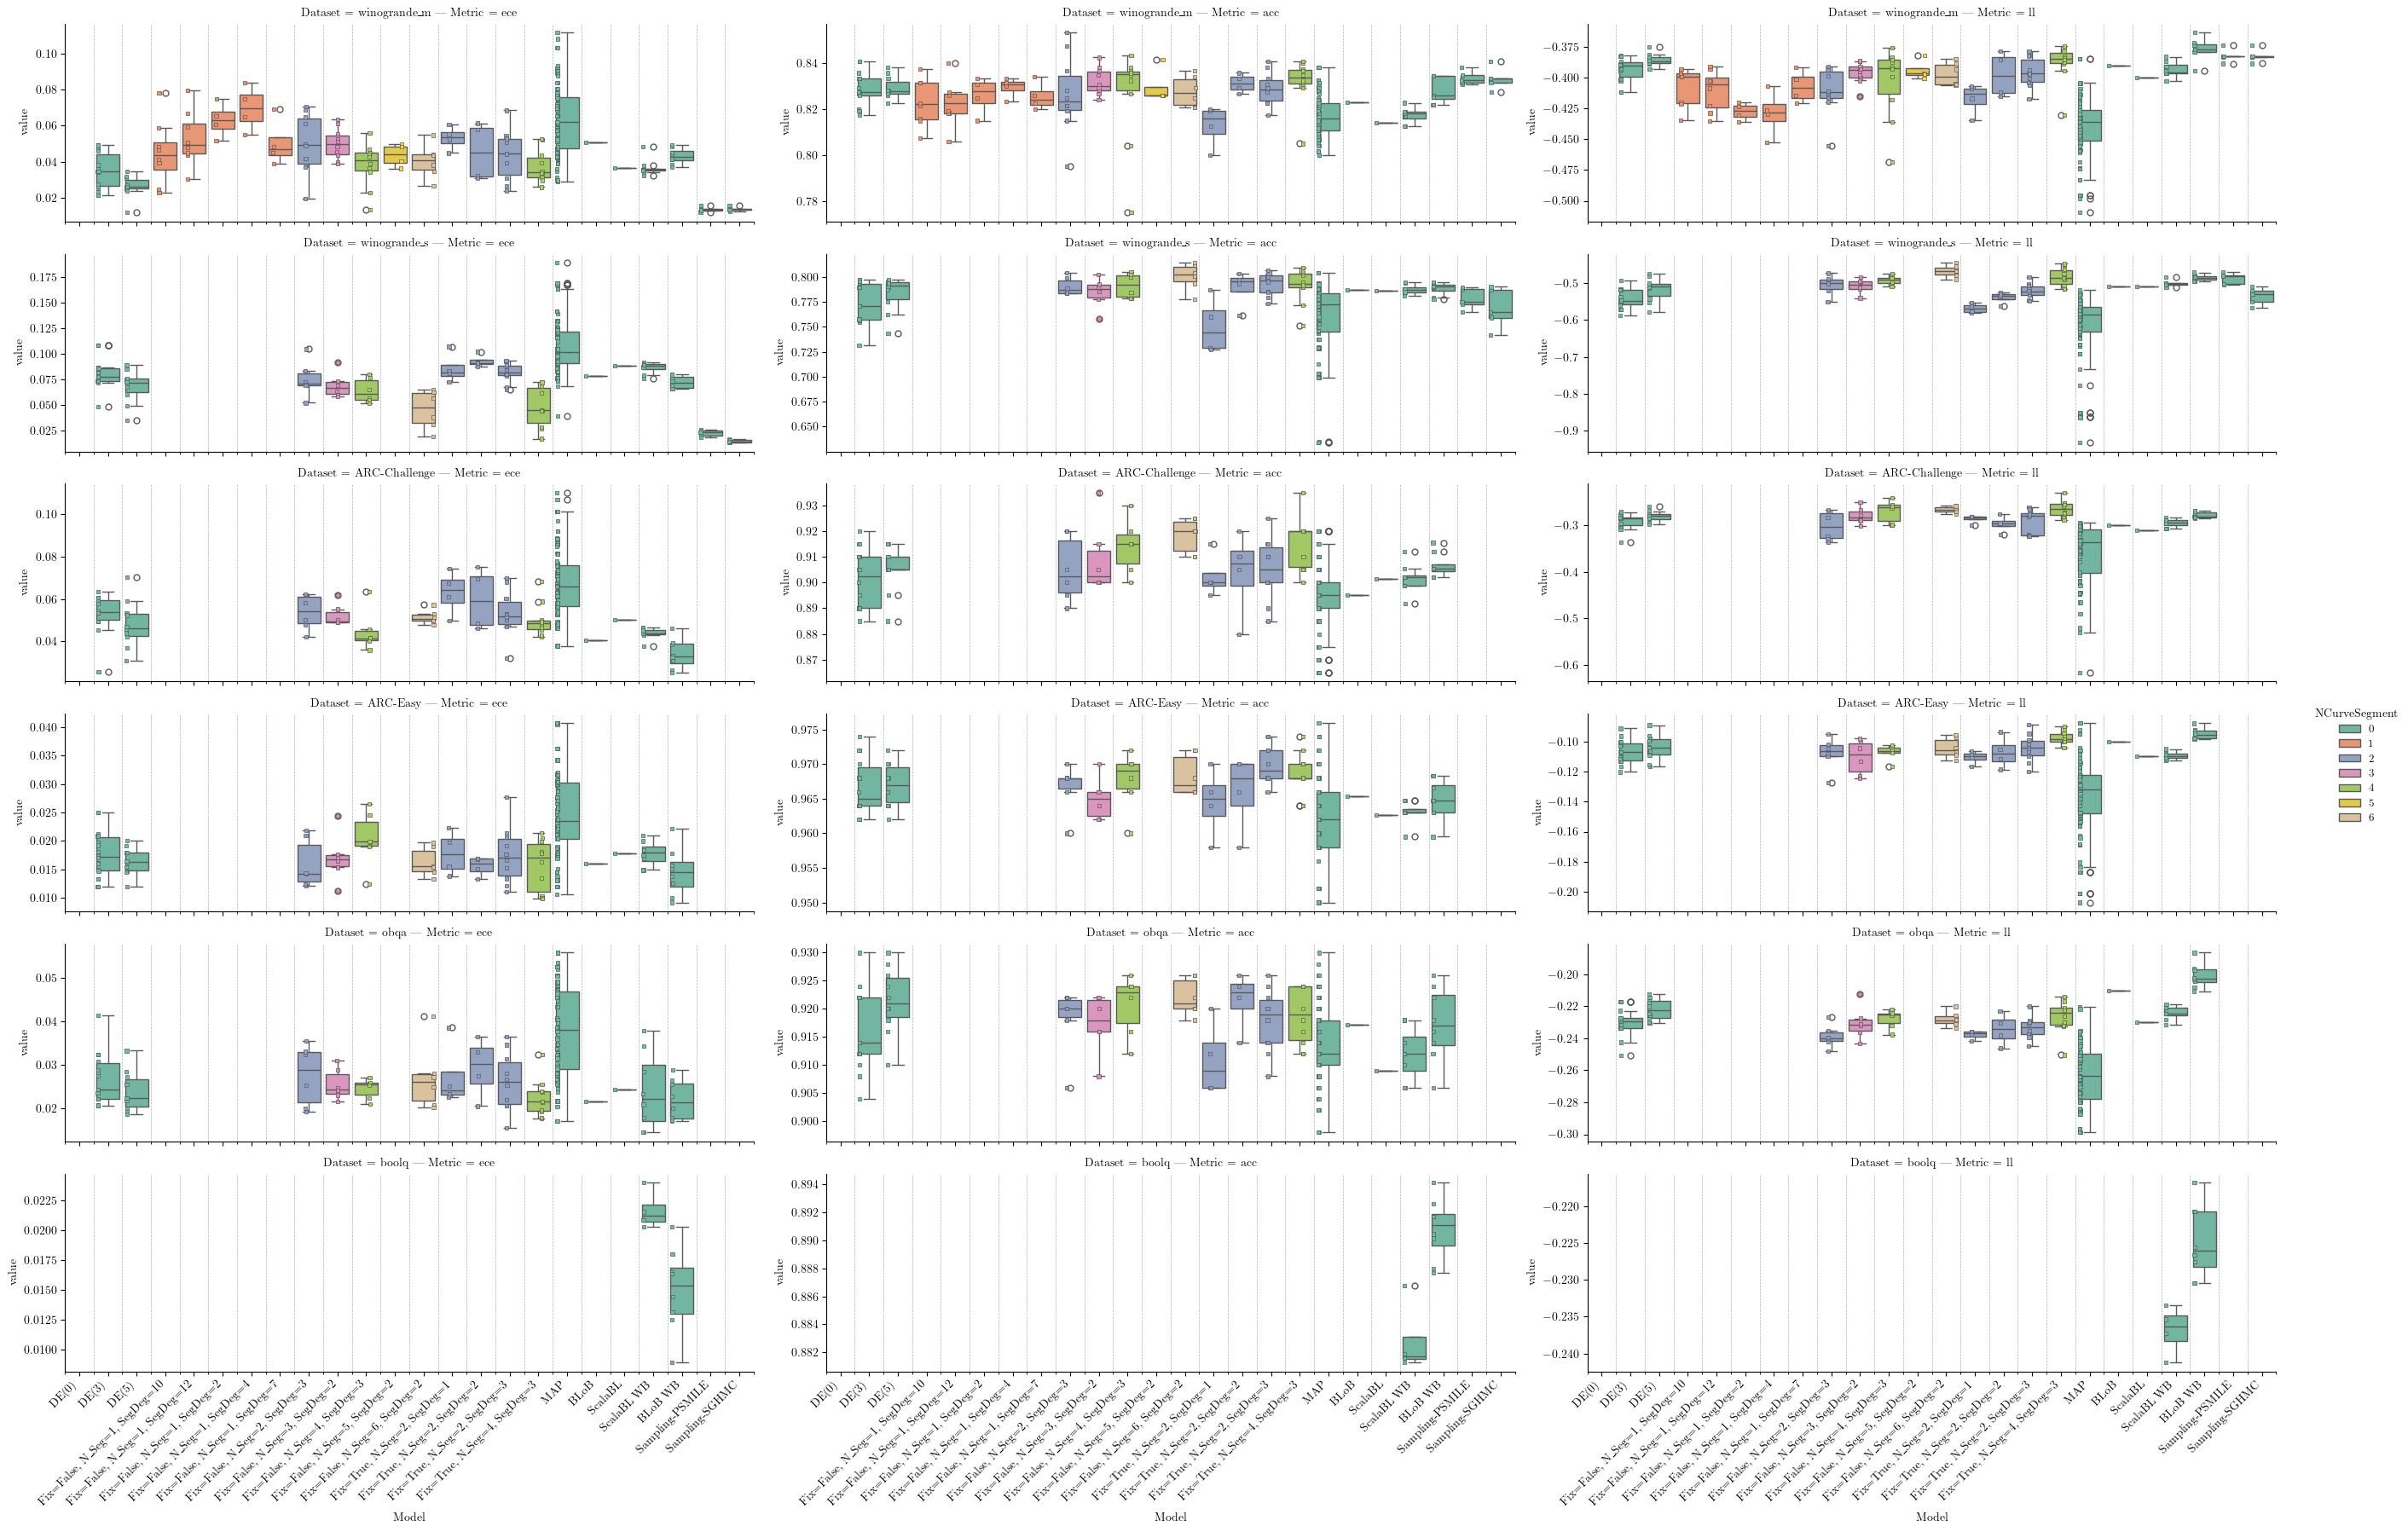

In [89]:
numeric_rhos = sorted(int(x) for x in df_plot_['NCurveSegment'].unique())
df_plot_['NCurveSegment'] = df_plot_['NCurveSegment'].astype(str)
hue_order = [str(x) for x in numeric_rhos]

hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))


g = sns.catplot(
    data=df_plot_, x='Model', y='value', hue='NCurveSegment', kind='box',
    row='Dataset', col='Metric', palette=hue_palette, sharey=False,
    height=figsize[1] * 1.5,
    hue_order=hue_order, aspect=3
)

# Overlay strip plots
for (ds, metric), ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)],
        x='Model', y='value', hue='NCurveSegment',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='auto', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )

# # Set y-axis labels per metric column
# ylabel_map = {'acc': r'ACC $\uparrow$', 'll': r'Log-Likelihood $\uparrow$', 'ece': r'ECE $\downarrow$'}
# for col_idx, metric in enumerate(metric_order):
#     for ax in g.axes[:, col_idx]:
#         ax.set_ylabel(ylabel_map[metric])


# Rotate x-tick labels on last row
for ax in g.axes[-1, :].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

g.tight_layout()

# make grid (only lines for y-axis) but at +- 0.5pt
major_ticks = ax.get_xticks()
minor_ticks = np.arange(start=min(major_ticks) - 0.5, 
                        stop=max(major_ticks) + 1.5, 
                        step=1)
# Set these positions as minor ticks
ax.set_xticks(minor_ticks, minor=True)
for ax in g.axes.flat:
    ax.grid(True, axis='x', which='minor', linestyle='--', linewidth=0.5,)

plt.savefig("result/performance.png", dpi=300)
plt.savefig("result/performance.pdf", dpi=300)


### table

In [90]:
# Generate updated LaTeX table from the latest merged dataframe (df_plot)
from pathlib import Path
import numpy as np
import pandas as pd

if "df_plot" not in globals():
    raise RuntimeError("df_plot not found. Run the merge cell (sampling_scalabl_merge_01) first.")

datasets = ["ARC-Challenge", "ARC-Easy", "obqa", "winogrande_m", "winogrande_s"]
metrics = ["acc", "ece", "ll"]

df_tbl = df_plot.copy()
df_tbl = df_tbl[df_tbl["Metric"].isin(metrics) & df_tbl["Dataset"].isin(datasets)].copy()
df_tbl = df_tbl[np.isfinite(df_tbl["value"])]

grp = df_tbl.groupby(["Metric", "Model", "Dataset"])["value"]
mean = grp.mean()
std2 = 2 * grp.std()

# Keep model order by first appearance in merged dataframe
model_order = []
for m in df_tbl["Model"].tolist():
    if m not in model_order:
        model_order.append(m)

def fmt_plain(m, s):
    if pd.isna(m):
        return "-"
    if pd.isna(s):
        return f"{m:.3f}"
    return f"{m:.3f} $\\pm$ {s:.3f}"

def is_better(metric, candidate, current):
    if pd.isna(current):
        return True
    if metric == "ece":
        return candidate < current
    return candidate > current

best_map = {}
for metric in metrics:
    for ds in datasets:
        best_val = np.nan
        for model in model_order:
            v = mean.get((metric, model, ds), np.nan)
            if pd.isna(v) or not np.isfinite(v):
                continue
            if is_better(metric, v, best_val):
                best_val = v
        best_map[(metric, ds)] = best_val

def mark_text(metric, model, ds):
    m = mean.get((metric, model, ds), np.nan)
    s = std2.get((metric, model, ds), np.nan)
    text = fmt_plain(m, s)
    if text == "-":
        return text

    best_val = best_map.get((metric, ds), np.nan)
    if pd.isna(best_val):
        return text

    if np.isclose(m, best_val, rtol=1e-12, atol=1e-12):
        return f"\\textbf{{\\underline{{{text}}}}}"

    low = m - s if pd.notna(s) else m
    high = m + s if pd.notna(s) else m
    if low <= best_val <= high:
        return f"\\underline{{{text}}}"
    return text

rows = []
for metric in metrics:
    for model in model_order:
        row = {"Metric": metric, "Model": model}
        any_present = False
        for ds in datasets:
            plain = fmt_plain(mean.get((metric, model, ds), np.nan), std2.get((metric, model, ds), np.nan))
            row[ds] = mark_text(metric, model, ds)
            if plain != "-":
                any_present = True
        if any_present:
            rows.append(row)

df_table = pd.DataFrame(rows)
out_csv = "result/performance_table.csv"
df_table.to_csv(out_csv, index=False)

# Build LaTeX table block
def esc(s):
    s = str(s)
    s = s.replace("_", "\\_")
    s = s.replace("&", "\\&")
    s = s.replace("%", "\\%")
    return s

lines = []
lines.append("\\begin{table*}[htbp]")
lines.append("\\centering")
lines.append("\\caption{Updated performance table from the latest merged plot data (mean $\\pm$ 2$\\sigma$ across available seeds/runs). Best per metric/dataset is bold+underlined; models whose mean$\\pm$2$\\sigma$ interval contains the best are underlined.}")
lines.append("\\label{tab:performance_metrics_updated}")
lines.append("\\resizebox{\\textwidth}{!}{%")
lines.append("\\begin{tabular}{llccccc}")
lines.append("\\toprule")
lines.append("\\textbf{Metric} & \\textbf{Model} & \\textbf{ARC-Challenge} & \\textbf{ARC-Easy} & \\textbf{obqa} & \\textbf{winogrande\\_m} & \\textbf{winogrande\\_s} " + r"\\")
lines.append("\\midrule")

for i, r in df_table.iterrows():
    if i > 0 and r["Metric"] != df_table.iloc[i - 1]["Metric"]:
        lines.append("\\midrule")
    lines.append(
        f"{esc(r['Metric'])} & {esc(r['Model'])} & {r['ARC-Challenge']} & {r['ARC-Easy']} & {r['obqa']} & {r['winogrande_m']} & {r['winogrande_s']} " + r"\\")

lines.append("\\bottomrule")
lines.append("\\end{tabular}%")
lines.append("}")
lines.append("\\end{table*}")

out_tex = "result/performance_table.tex"
Path(out_tex).write_text("\n".join(lines))

print(f"Saved table csv: {out_csv}")
print(f"Saved table tex: {out_tex}")
df_table



Saved table csv: result/performance_table.csv
Saved table tex: result/performance_table.tex


,Metric,Model,ARC-Challenge,ARC-Easy,obqa,winogrande_m,winogrande_s
0,acc,DE(3),\underline{0.901 $\pm$ 0.022},\underline{0.967 $\pm$ 0.008},\underline{0.917 $\pm$ 0.014},\underline{0.828 $\pm$ 0.014},\underline{0.774 $\pm$ 0.040}
1,acc,DE(5),\underline{0.905 $\pm$ 0.018},\underline{0.967 $\pm$ 0.006},\underline{0.921 $\pm$ 0.012},\underline{0.829 $\pm$ 0.010},\underline{0.783 $\pm$ 0.036}
2,acc,"Fix=False, N_Seg=1, SegDeg=10",-,-,-,\underline{0.823 $\pm$ 0.020},-
3,acc,"Fix=False, N_Seg=1, SegDeg=12",-,-,-,\underline{0.823 $\pm$ 0.020},-
4,acc,"Fix=False, N_Seg=1, SegDeg=2",-,-,-,\underline{0.826 $\pm$ 0.016},-
5,acc,"Fix=False, N_Seg=1, SegDeg=4",-,-,-,\underline{0.830 $\pm$ 0.009},-
6,acc,"Fix=False, N_Seg=1, SegDeg=7",-,-,-,\underline{0.826 $\pm$ 0.012},-
7,acc,"Fix=False, N_Seg=2, SegDeg=3",\underline{0.905 $\pm$ 0.025},\underline{0.967 $\pm$ 0.007},\underline{0.918 $\pm$ 0.012},\underline{0.826 $\pm$ 0.033},\underline{0.791 $\pm$ 0.018}
8,acc,"Fix=False, N_Seg=3, SegDeg=2",\underline{0.909 $\pm$ 0.028},\underline{0.965 $\pm$ 0.006},\underline{0.917 $\pm$ 0.011},\textbf{\underline{0.832 $\pm$ 0.012}},\underline{0.784 $\pm$ 0.030}
9,acc,"Fix=False, N_Seg=4, SegDeg=3",\underline{0.914 $\pm$ 0.021},\underline{0.968 $\pm$ 0.009},\underline{0.921 $\pm$ 0.011},\underline{0.826 $\pm$ 0.042},\underline{0.791 $\pm$ 0.025}
